# Curso de PyTorch y Modelos Neuronales

> Autor: Jorge García González (Universidad de Málaga)

## Índice

1. Manipulación de Datos en PyTorch
2. Manipulación de Datos en PyTorch II
3. Aprendizaje en PyTorch I
4. Aprendizaje en PyTorch II
5. Modelos Neuronales I
6. Modelos Neuronales II
7. Modelos Neuronales III
8. Modelos Neuronales IV

---
# Parte 1: Manipulación de Datos en PyTorch
---

# Manipulación de Datos en Pytorch

Antes de comenzar a usar PyTorch, es recomendable verificar con qué estamos trabajando.

In [4]:
# Importar la librería es importante para poder usarla :D
import torch
import sys
import numpy as np
import matplotlib.pyplot as plt
import time

In [5]:
print(f"Versión de Python: {sys.version}")
print(f"Versión de PyTorch: {torch.__version__}")
print(f"Disponibilidad de CUDA: {torch.cuda.is_available()}")
print(f"Versión de CUDA: {torch.version.cuda if torch.cuda.is_available() else None}")

Versión de Python: 3.12.11 (main, Jun  4 2025, 08:56:18) [GCC 11.4.0]
Versión de PyTorch: 2.8.0+cu126
Disponibilidad de CUDA: True
Versión de CUDA: 12.6


Nótese la coincidencia entre la versión de CUDA (12.6) y la versión de PyTorch (2.8.0+cu126). La versión de PyTorch nos indica que es PyTorch 2.8.0 compilado para CUDA 12.6. Si la versión del compilado de PyTorch y la versión de CUDA del sistema no coinciden, no funcionará.
Se puede acceder a las distintas versiones de PyTorch en: https://pytorch.org/get-started/previous-versions/

El código de distintas versiones de Pytorch no necesariamente es compatible entre sí.
La versión de CUDA dependerá principalmente de los controladores instalados en la máquina y estos a su vez de la GPU. Más información [aquí](https://developer.nvidia.com/cuda-gpus) y [aquí](https://docs.nvidia.com/deploy/cuda-compatibility/index.html).

---
El Aprendizaje Profundo se engloba dentro del Aprendizaje Computacional. Tiene como objetivo generar un modelo para resolver un problema a partir de datos. Muchos datos. ¡Inmensas cantidades de datos!

Por eso es vital cómo manejar y almacenar esos datos.

En PyTorch y otras librerías similares los cálculos se hacen sobre datos en punto flotante (números reales) y la mayoría de los procesos implican operar arrays n-dimensionales. Por convención nos referimos a esta estructura de datos como *tensor*. Pese al nombre específico, un tensor no es más que un array multidimensional. Un vector es un array de 1 dimensión, una matriz es un array de 2 dimensiones y un tensor es un array de cualquier número de dimensiones.
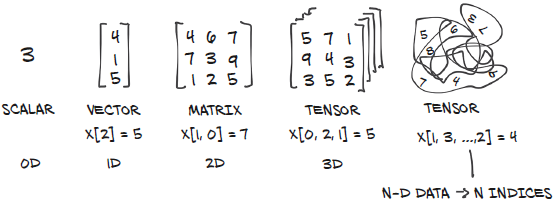


Aunque su funcionamiento interno sea distinto, la usabilidad de los tensores en PyTorch es similar a la de los arrays de Numpy. Se puede obtener un tensor de PyTorch a partir de un array de Numpy y viceversa.

In [6]:
np_array = np.random.rand(10) # Generamos con Numpy un vector de tamaño 10 a partir de la distribución uniforme entre [0,1)
print(np_array)
torch_tensor = torch.rand(10) # Generamos con PyTorch un vector de tamaño 10 a partir de la distribución uniforme entre [0,1)
print(torch_tensor)
np_array_from_torch_tensor = torch_tensor.numpy()
print(np_array_from_torch_tensor)
torch_tensor_from_np_array = torch.from_numpy(np_array)
print(torch_tensor_from_np_array)

[0.49016962 0.96776095 0.52208507 0.64796464 0.87686166 0.69791126
 0.92911354 0.58345151 0.93155055 0.73725814]
tensor([0.8862, 0.3416, 0.9193, 0.3284, 0.5210, 0.3203, 0.3250, 0.7399, 0.0147,
        0.1422])
[0.88615227 0.34159422 0.91925514 0.32837164 0.5210284  0.3203274
 0.32504874 0.73991996 0.01468199 0.1421513 ]
tensor([0.4902, 0.9678, 0.5221, 0.6480, 0.8769, 0.6979, 0.9291, 0.5835, 0.9316,
        0.7373], dtype=torch.float64)


Su indexado se realiza exactamente con la misma sintaxis y ambos siguen las mismas reglas de *broadcasting*.

In [7]:
print(np_array_from_torch_tensor[1:3])
print(torch_tensor[1:3])

[0.34159422 0.91925514]
tensor([0.3416, 0.9193])


¿Entonces por qué no usamos Numpy en lugar de los tensores de PyTorch? Porque los tensores de PyTorch pueden mandarse a la GPU para realizar las operaciones en ella. Podemos consultar dónde está alojado el tensor y moverlo de memoria principal a memoria de video.

In [8]:
print(f"torch_tensor está alojado en: {torch_tensor.device}")
torch_tensor_gpu = torch_tensor.to("cuda")
print(f"torch_tensor está ahora alojado en: {torch_tensor_gpu.device}")

torch_tensor está alojado en: cpu
torch_tensor está ahora alojado en: cuda:0


Nótese que la sentencia para mover a la GPU el tensor implica una asignación. La operación no se hace sobre el mismo objeto tensor, sino que se genera uno nuevo. Esto tiene sentido si uno lo piensa. El tensor es un objeto en memoria, pero no queremos modificar ese objeto, sino "moverlo" a otra memoria. Estamos generando un nuevo tensor con la misma información.

In [9]:
print(f"El torch_tensor original sigue en: {torch_tensor.device}")

El torch_tensor original sigue en: cpu


Es llamativo también que para indicar que el tensor está alojado en memoria de video se usa el indicativo 'cuda:0'. 'cuda' indica que está en memoria de video y el 0 indica el índice del dispositivo en el que está. Si dispusieramos de varias GPUs podríamos mover tensores entre distintas GPUs.

Ya que PyTorch permite operar en la GPU y nos interesa para acelerar nuestros cálculos, vamos a probar cómo evolucionan los tiempos de operación con distintos tamaños de matrices en Numpy, PyTorch en CPU y PyTorch en GPU.

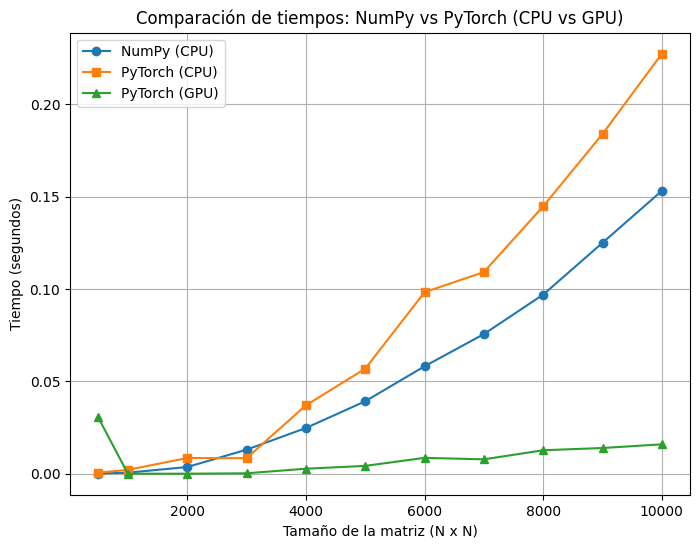

In [10]:
SIZES = [i*500 for i in range(30)]

numpy_times = []      # Lista para almacenar los tiempos de Numpy.
torch_cpu_times = []  # Lista para almacenar los tiempos de PyTorch en CPU.
torch_gpu_times = []  # Lista para almacenar los tiempos de PyTorch en GPU.

for size in SIZES:

  # Operamos en Numpy
  A_np = np.random.rand(size, size).astype(np.float32)
  B_np = np.random.rand(size, size).astype(np.float32)

  start_time = time.time()
  C_np = A_np*B_np
  end_time = time.time()
  numpy_times.append(end_time-start_time)

  # Operamos en PyTorch en CPU
  A_torch_cpu = torch.from_numpy(A_np)
  B_torch_cpu = torch.from_numpy(B_np)

  start_time = time.time()
  C_torch_cpu = A_torch_cpu*B_torch_cpu
  end_time = time.time()
  torch_cpu_times.append(end_time-start_time)

  # Operamos en PyTorch en CPU
  A_torch_gpu = A_torch_cpu.to('cuda')
  B_torch_gpu = B_torch_cpu.to('cuda')

  start_time = time.time()
  C_torch_cpu = A_torch_gpu*B_torch_gpu
  end_time = time.time()
  torch_gpu_times.append(end_time-start_time)

# Gráfica de resultados
plt.figure(figsize=(8,6))
plt.plot(SIZES, numpy_times, marker='o', label="NumPy (CPU)")
plt.plot(SIZES, torch_cpu_times, marker='s', label="PyTorch (CPU)")
plt.plot(SIZES, torch_gpu_times, marker='^', label="PyTorch (GPU)")
plt.xlabel("Tamaño de la matriz (N x N)")
plt.ylabel("Tiempo (segundos)")
plt.title("Comparación de tiempos: NumPy vs PyTorch (CPU vs GPU)")
plt.legend()
plt.grid(True)
plt.show()

Como se puede observar, el tiempo de ejecución tiene un aumento mucho menor al trabajar con PyTorch en GPU respecto a Numpy y PyTorch en CPU. Es interesante observar que los tiempos de PyTorch en CPU son peores que los de Numpy aunque ambos funcionan en CPU. Pytorch, en su versión de CPU, es menos eficiente que Numpy.

Sin embargo, esta comparación no es del todo justa. Con ella en mente lo lógico sería usar siempre que sea posible Pytorch en GPU.

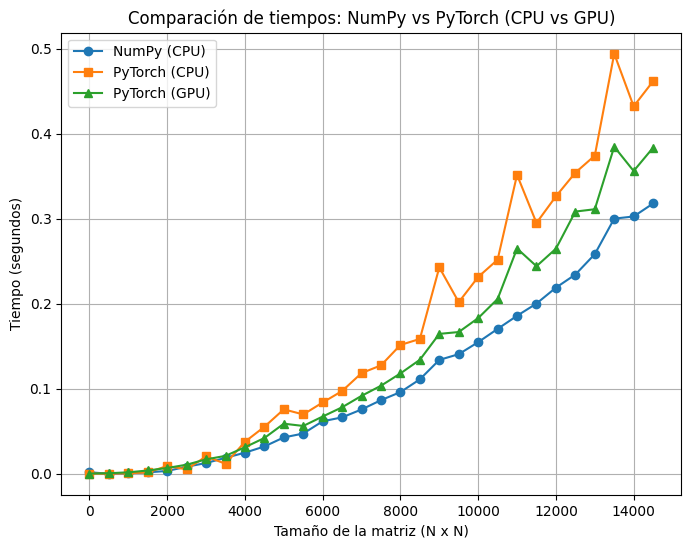

In [13]:
SIZES = [i*500 for i in range(30)]

numpy_times = []      # Lista para almacenar los tiempos de Numpy.
torch_cpu_times = []  # Lista para almacenar los tiempos de PyTorch en CPU.
torch_gpu_times = []  # Lista para almacenar los tiempos de PyTorch en GPU.

for size in SIZES:

  # Operamos en Numpy
  A_np = np.random.rand(size, size).astype(np.float32)
  B_np = np.random.rand(size, size).astype(np.float32)

  start_time = time.time()
  C_np = A_np*B_np
  end_time = time.time()
  numpy_times.append(end_time-start_time)

  # Operamos en PyTorch en CPU
  A_torch_cpu = torch.from_numpy(A_np)
  B_torch_cpu = torch.from_numpy(B_np)

  start_time = time.time()
  C_torch_cpu = A_torch_cpu*B_torch_cpu
  end_time = time.time()
  torch_cpu_times.append(end_time-start_time)

  # Operamos en PyTorch en GPU
  start_time = time.time()
  A_torch_gpu = A_torch_cpu.to('cuda')
  B_torch_gpu = B_torch_cpu.to('cuda')

  C_torch_cpu = A_torch_gpu*B_torch_gpu
  end_time = time.time()
  torch_gpu_times.append(end_time-start_time)

# Gráfica de resultados
plt.figure(figsize=(8,6))
plt.plot(SIZES, numpy_times, marker='o', label="NumPy (CPU)")
plt.plot(SIZES, torch_cpu_times, marker='s', label="PyTorch (CPU)")
plt.plot(SIZES, torch_gpu_times, marker='^', label="PyTorch (GPU)")
plt.xlabel("Tamaño de la matriz (N x N)")
plt.ylabel("Tiempo (segundos)")
plt.title("Comparación de tiempos: NumPy vs PyTorch (CPU vs GPU)")
plt.legend()
plt.grid(True)
plt.show()

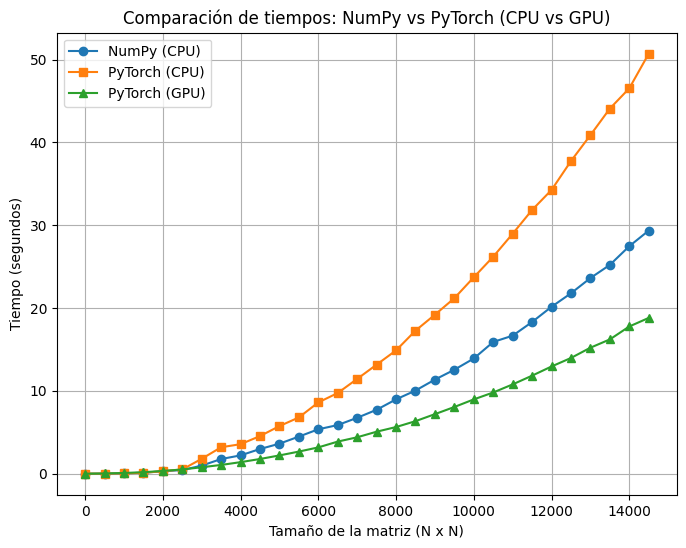

In [16]:
SIZES = [i*500 for i in range(30)]
N_OPS = 50
numpy_times = []      # Lista para almacenar los tiempos de Numpy.
torch_cpu_times = []  # Lista para almacenar los tiempos de PyTorch en CPU.
torch_gpu_times = []  # Lista para almacenar los tiempos de PyTorch en GPU.

for size in SIZES:

  # Operamos en Numpy
  A_np = np.random.rand(size, size).astype(np.float32)
  B_np = np.random.rand(size, size).astype(np.float32)

  start_time = time.time()
  for i in range(N_OPS):
    C_np = A_np*B_np*i
  end_time = time.time()
  numpy_times.append(end_time-start_time)

  # Operamos en PyTorch en CPU
  A_torch_cpu = torch.from_numpy(A_np)
  B_torch_cpu = torch.from_numpy(B_np)

  start_time = time.time()
  for i in range(N_OPS):
    C_torch_cpu = A_torch_cpu*B_torch_cpu*i
  end_time = time.time()
  torch_cpu_times.append(end_time-start_time)

  # Operamos en PyTorch en GPU
  start_time = time.time()
  for i in range(N_OPS):
    A_torch_gpu = A_torch_cpu.to('cuda')
    B_torch_gpu = B_torch_cpu.to('cuda')

    C_torch_cpu = A_torch_gpu*B_torch_gpu*i
  end_time = time.time()
  torch_gpu_times.append(end_time-start_time)

# Gráfica de resultados
plt.figure(figsize=(8,6))
plt.plot(SIZES, numpy_times, marker='o', label="NumPy (CPU)")
plt.plot(SIZES, torch_cpu_times, marker='s', label="PyTorch (CPU)")
plt.plot(SIZES, torch_gpu_times, marker='^', label="PyTorch (GPU)")
plt.xlabel("Tamaño de la matriz (N x N)")
plt.ylabel("Tiempo (segundos)")
plt.title("Comparación de tiempos: NumPy vs PyTorch (CPU vs GPU)")
plt.legend()
plt.grid(True)
plt.show()

---
# Parte 2: Manipulación de Datos en PyTorch II
---

# Manipulación de Datos en PyTorch II

Autor: Jorge García González (Universidad de Málaga)

Última Actualización: 1/10/2025

Asignatura: Programación para la Inteligencia Artificial

Antes de continuar con los modelos neuronales, debemos hacer un inciso para hablar otra vez de cómo gestionar los datos en PyTorch. Cuando entrenamos un modelo de aprendizaje profundo generalmente no tenemos el privilegio de poder ignorar la memoria. Tanto los modelos como los conjuntos de datos y los cálculos intermedios realizados durante el entrenamiento suelen requerir una cantidad no trivial de memoria y gestionarla bien (como hemos visto anteriormente) es determinante para que el entrenamiento sea eficiente. Además, hay ciertas manipulaciones de los datos que pueden ser convenientes durante el entrenamiento de un modelo, pero de eso hablaremos en el futuro.

Antes de hablar de ciertas herramientas de PyTorch para gestionar los datos durante el entrenamiento, vamos a entender unas funciones concretas de Python: los generadores.

Un generador es una función de Python que se comporta como un iterable eficiente. Veamos un ejemplo.

In [154]:
iterable_lista = [0,1,2,3,4,5,6,7,8,9]
print(iterable_lista)
for n in iterable_lista:
  print(n)

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
0
1
2
3
4
5
6
7
8
9


Ahí podemos ver la declaración explícita de una lista e iteramos sobre ella. A priori no hay problema con las listas. Sirven para almacenar información, poder acceder a ella, etc.

El "problema" es que las listas ocupan espacio. Suena obvio, pero es así. Si defino una lista de un millón de elementos, ese millón de elementos ocuparán espacio en memoria y en muchas ocasiones no sirve para nada tener ese millón de elementos en memoria a la vez porque el único uso que quiero hacer es iterarlos. Solo quiero usar los elementos de esa lista uno tras otro en un bucle bien definido. No voy a alterar el orden, añadir nuevos elementos, eliminar elementos, alterar los propios elementos... Solo tener acceso a uno tras otro.

Un generador es una función iterable que proporciona los elementos y los *genera* cuando se le pide sin tenerlos almacenados en memoria. Podríamos crear una clase para hacer eso, pero Python provee de una estructura muy simple para hacerlo. Un ejemplo:

In [155]:
def firstn(n):
  num = 0
  while num < n:
    yield num
    num += 1

print(firstn(10))
for n in firstn(10):
  print(n)

generador = firstn(n)
print(f"Dame el siguiente: {next(generador)}")
print(f"Dame el siguiente: {next(generador)}")
print(f"Dame el siguiente: {next(generador)}")

<generator object firstn at 0x7f8ef81b2d40>
0
1
2
3
4
5
6
7
8
9
Dame el siguiente: 0
Dame el siguiente: 1
Dame el siguiente: 2


Una estructura simple, ¿verdad? La palabra clave **yield** le indica a la función que devuelva un valor, pero a diferencia de **return**, no termina la función. Si tenemos un **return** dentro de un bucle (decisión de programación MUY cuestionable), Python se limita a devolver lo indicado y dar por finalizada la función sin atender al estado del bucle. **yield** permite devolver lo indicado y mantener el bucle "a la espera" en segundo plano. Una vez el generador está creado, podemos usar la función de Python **next** para solicitarle el siguiente elemento.

En realidad llevamos usando generadores desde el principio. Es básicamente **range**.

Más información: https://wiki.python.org/moin/Generators

Ahora que hemos entendido la idea de generar los datos sobre la marcha, vamos a centrarnos en PyTorch.

Igual que en el uso de los generadores, al entrenar un modelo normalmente no necesitamos todo el conjunto de datos a la vez en memoria. Los entrenamientos funcionan por lotes (o *batch*), aunque de eso hablaremos un poco más adelante. Lo relevante ahora es que hace falta una herramienta para proveer los datos según se necesitan sin necesitar que estén todos cargados en memoria todo el tiempo. Para eso PyTorch tiene las clases *Dataset* y *DataLoader*.

Conceptualmente, el trabajo de la clase *Dataset* es cargar los datos de uno en uno y el de *DataLoader* hacer una gestión de esos datos adaptada al entrenamiento. Vamos a ver un ejemplo.

Para este ejemplo vamos a usar acceso a carpetas. Como este cuadernos e está realizando en Google colab, necesitamos montar en colab una carpeta de Google Drive para trabajar. Si se ejecuta en un entorno local, este paso se omitiría o cambiaría según necesidad.

In [156]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Una vez montado en colab, definimos una ruta en la que trabajar y vamos a crear un conjunto de datos para resolver un hipotético problema en el que se relaciona una imagen con cuánto ruido uniforme tiene.

Vamos a importar algunas librerías útiles.

In [157]:
working_path = '/content/drive/MyDrive/Work/Docencia UMA/2025-2026/Programacion para la IA/data'
import torch
from torchvision.io import decode_image
from torchvision.utils import save_image
from tqdm import tqdm
import csv
import os

In [158]:
original_image_path = os.path.join(working_path, "Shin Chan/shin_chan_2.png")
original_image = decode_image(original_image_path, mode='RGBA')/255.                # Cargo la imagen original. Ignoro el canal alpha y la normalizo entre 0 y 1 por simplicidad.
alpha = original_image[-1]                                                          # Separo el alfa.
original_image = original_image[:-1] + (1-alpha[None,:])                            # Me quedo solo con RGB y le sumo 1-alfa por simple cuestióne stética. Quiero el fondo blanco.
dataset_size = 100                                                                  # Defino el número de imágenes a generar.
maximum_noise_range = 100                                                           # Defino el máximo de ruido que aceptaríamos añadir.
labels = []                                                                         # Inicializo la lista que almacenará las etiquetas.

for i in tqdm(range(dataset_size)):
  noise_range = torch.randint(low=0, high=maximum_noise_range, size=(1,))[0]       # Decido cuánto va a ser el ruido máximo de esta imagen.
  noise = torch.rand_like(original_image)*noise_range/255.                         # Genero el ruido.
  image_with_noise = torch.clamp(original_image+noise*alpha, 0,1)                  # Añado el ruido a la imagen (no al fondo) y me aseguro de que la imagen con ruido no tenga valores fuera del rango [0,1]
  image_path = os.path.join(working_path, f"Shin Chan/images/shin_chan_{i}.png")   # Creo el path de la imagen para guardarla.
  save_image(image_with_noise, image_path)                                         # Guardo la imagen desnormalizada.
  labels.append(int(noise_range))                                                  # Añado la etiqueta a la lista.

# Guardo la lista como un csv.
with open(os.path.join(working_path, f"Shin Chan/labels.csv"), mode='w', newline='') as csvfile:
  f = csv.writer(csvfile, quoting=csv.QUOTE_ALL)
  f.writerow(labels)

100%|██████████| 100/100 [00:13<00:00,  7.52it/s]


Una vez con un conjunto de datos que manipular, podemos ver para qué sirve la clase *Dataset*.

Como hemos dicho, su objetivo es cargar los datos de uno en uno. Sirve para enmascarar todo el proceso para lidiar con los archivos. Vamos a importar la clase base.

In [159]:
from torch.utils.data import Dataset

Un *Dataset* de PyTorch tiene que tener implementdos tres metodos: *\_\_init__* (el constructor), *\_\_len__* para que devuelva su tamaño cuando se use la función **len** y *\_\_getitem__* para solicitar un elemento.

Nota: que los métodos tengan nombres con guiones bajos es una manera de señalar que esos métodos no están pensados para ser llamados directamente por quien use la clase, sino que son utilidades intermedias.

Dentro de esos métodos uno puede hacer lo que considere oportuno. Típicamente en el constructor se guarda la información necesaria para trabajar. Un *Dataset* para nuestro conjunto de datos podría ser el siguiente.

In [164]:
class ShinChanDataset(Dataset):
  def __init__(self, images_path, labels_path, transform=None, target_transform=None):
    self.images_path = images_path
    self.labels_path = labels_path
    self.transform = transform
    self.target_transform = target_transform

    # Vamos a cargar las etiquetas en el constructor. No ocupan mucho en memoria y
    # ahorramos tiempo de acceso a disco duro durante la ejecución.
    with open(self.labels_path, newline='') as csvfile:
      f = csv.reader(csvfile)
      self.labels = [int(l) for l in list(f)[0]]

  def __len__(self):
    # La longitud del Dataset coincide con el número de etiquetas.
    return len(self.labels)

  def __getitem__(self, idx):
    img_path = os.path.join(self.images_path, f"shin_chan_{idx}.png")
    image = decode_image(img_path)
    label = self.labels[idx]
    #Si hay transformaciones, las aplico.
    if self.transform:
      image = self.transform(image)
    if self.target_transform:
      label = self.target_transform(label)
    return image, label

Obviando el argumento *self* necesario en los métodos de Python, al constructor se le pueden alterar los argumentos según sea necesario y no devuelve nada, *\_\_len__* es un método que no tiene argumentos y devuelve un entero (se asume que 0 o positivo), mientras que *\_\_getitem__* tiene como argumento el índice del elemento a devolver y devuelve una tupla con el dato y su etiqueta.

Los transform que se utilizan son transformaciones. Una convención de PyTorch para referirise a las funciones que transforman la información. Por ahora no vamos a usarlas y podrían ser omitidas, pero mejor si nos acostumbramos a verlas.

Vamos a crear una instancia de nuestro *Dataset* y a ver si funciona.

In [165]:
shin_chan_dataset = ShinChanDataset(
    os.path.join(working_path, "Shin Chan",  "images"),
    os.path.join(working_path, "Shin Chan", "labels.csv")
)
print(len(shin_chan_dataset))
print(shin_chan_dataset.__getitem__(0))

100
(tensor([[[255, 255, 255,  ..., 255, 255, 255],
         [255, 255, 255,  ..., 255, 255, 255],
         [255, 255, 255,  ..., 255, 255, 255],
         ...,
         [255, 255, 255,  ..., 255, 255, 255],
         [255, 255, 255,  ..., 255, 255, 255],
         [255, 255, 255,  ..., 255, 255, 255]],

        [[255, 255, 255,  ..., 255, 255, 255],
         [255, 255, 255,  ..., 255, 255, 255],
         [255, 255, 255,  ..., 255, 255, 255],
         ...,
         [255, 255, 255,  ..., 255, 255, 255],
         [255, 255, 255,  ..., 255, 255, 255],
         [255, 255, 255,  ..., 255, 255, 255]],

        [[255, 255, 255,  ..., 255, 255, 255],
         [255, 255, 255,  ..., 255, 255, 255],
         [255, 255, 255,  ..., 255, 255, 255],
         ...,
         [255, 255, 255,  ..., 255, 255, 255],
         [255, 255, 255,  ..., 255, 255, 255],
         [255, 255, 255,  ..., 255, 255, 255]]], dtype=torch.uint8), 30)


Todo parece funcionar. Tenemos un objeto que nos devuelve los datos según se los pedimos. Una vez con un *Dataset*, podemos aprovechar la clase *Dataloader*.

In [162]:
from torch.utils.data import DataLoader

Como hemos dicho, el *DataLoader* nos permite hacer una gestión de los conjuntos de datos de alto nivel. Se encarga de "organizar" los datos que el *Dataset* proporciona. Vamos a ver qué hace con nuestro *Dataset* si lo recorremos. ¡*DataLoader* también es un iterable!

In [167]:
dataloader = DataLoader(shin_chan_dataset, batch_size=64, shuffle=True)
for i, batch in enumerate(dataloader):
  print(f"Iteración {i}")
  print(f"Tipo de batch: {type(batch)}")
  print(f"Longitud de batch: {len(batch)}")
  print(f"Tamaño de batch[0]: {batch[0].shape}")
  print(f"Tamaño de batch[1]: {batch[1].shape}")

Iteración 0
Tipo de batch: <class 'list'>
Longitud de batch: 2
Tamaño de batch[0]: torch.Size([64, 3, 700, 600])
Tamaño de batch[1]: torch.Size([64])
Iteración 1
Tipo de batch: <class 'list'>
Longitud de batch: 2
Tamaño de batch[0]: torch.Size([36, 3, 700, 600])
Tamaño de batch[1]: torch.Size([36])


Vamos a ver qué está pasando aquí por partes. Primero observemos la llamada al constructor. Como podemos ver, lo primero que le proporcionamos como argumento es un *Dataset*. De ahí obtendrá los datos. El segundo argumento es el *batch_size* que determinará el tamaño de los lotes que irá generando el *DataLoader*. Por último con *shuffle* le hemos indicado que ordene aleatoriamente los datos cada *época*. Ahora vamos a explicar qué significa esto.

El trabajo del *DataLoader* es ir proporcionando al bucle de entrenamiento los datos con los que realizar el *forward* y posterior *backward* en cada iteración. Los datos de cada una de esas iteraciones es lo que entendemos por un *batch*. Como podemos ver en la ejecución, el *batch* (no nos engañemos, nadie lo llama lote) es una lista de tamaño 2. El primer elemento es un tensor con todos los inputs (el primer elemento de la tupla que devuelve el *Dataset*) y el segundo un tensor con todas las etiquetas (el segundo elemento que devuelve el *Dataset*). Alguno de ellos podría ser otro iterable si PyTorch no los identificara con un tipo apto para hacer un tensor.

Es interesante ver que en la primera iteración el *batch* tiene 64 datos y en la segunda tiene solo 36. Esto se debe simplemente a que nuestro conjunto de datos tiene 100 elementos (64+36=100). Cuando iteramos el *DataLoader* devuelve un *batch* tras otro hasta haber devuelto todos los elementos del conjunto de datos. A recorrer todos los elementos del conjunto de datos es lo que llamamos una *época* de entrenamiento y el argumento *shuffle* del *DataLoader* le indica que cada vez que inice una nueva época, devuelva los datos en un orden distinto.

En el siguiente cuaderno hablaremos de la importancia del tamaño del *batch* y que sea aleatorio. *DatasLoader* tiene otros argumentos que pueden ser relevantes desde el punto de vista de su eficiencia a la hora de acceder a los datos, pero ya hablaremos de ellos en el futuro si hay tiempo.





---
# Parte 3: Aprendizaje en PyTorch I
---

In [5]:
import torch
import matplotlib.pyplot as plt

# Aprendizaje

> Autor: Jorge García González (Universidad de Málaga)

> Última Actualización: 21/09/2026

> Asignatura: Programación para la Inteligencia Artificial

¿Qué entendemos por *aprender* en el contexto de las Redes Neuronales Artificiales? Ajustar los parámetros de un modelo.

Antes de empezar con las redes, vamos a observar el fenómeno del ajuste de parámetros en un modelo mucho más sencillo. Vamos a hacer un modelo que ajuste una recta a partir de unos datos que pertenezcan a esa recta.

Recordemos que la ecuación de una recta en 2 dimensiones es y=m*x+b. Por tanto una recta solo tiene dos parámetros que ajustar, la m (inclinación) y la b (valor donde se corta el eje y).

Lo primero que necesitamos es una función que, dados los parámetros de una recta, nos devuelva un conjunto de puntos que formen parte de esa recta. Para hacerlo un poquito más realista vamos a añadirle ruido gaussiano a esos datos. Así los puntos no encajarán perfectamente en la recta, pero deberían estar cerca.

Los datos en problemas reales rara vez son perfectos y nuestros modelos son solo aproximaciones.

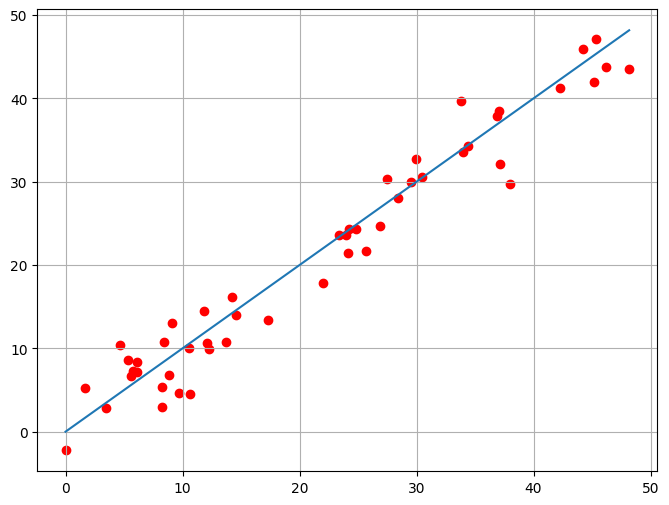

In [6]:
def get_data_from_a_line(m, b, n, sigma=2, range=50):
  """
  Función que devuelve datos a partir de una recta. Recordemos que la ecuación de la recta está definida por y=mx+b.
  Args:
    m: inclinación de la recta.
    b: ordenada en el origen de la recta.
    n: número de datos que queremos obtener.
    sigma: desviación típica para el ruido que añadiremos a los datos (2 por defecto).
    range: extremo del rango [0,rango] en el eje x en el que queremos situar los datos (50 por defecto).
  """
  x = range*torch.rand(n)                                                 # Generamos los datos en el eje x.
  y = m*x+b                                                               # Obtemeos la posición correspondiente en el eje y.
  noise_x = torch.normal(torch.zeros_like(y), sigma*torch.ones_like(y))   # Generamos un vector de ruido gaussiano para el eje x.
  noise_y = torch.normal(torch.zeros_like(y), sigma*torch.ones_like(y))   # Generamos un vector de ruido gaussiano para el eje y.
  x_with_noise = x + noise_x                                              # Añadimos el ruido al eje x.
  x_with_noise = torch.clamp(x_with_noise, min=0, max = range)            # Aseguramos que el eje x esté en el rango deseado.
  y_with_noise = y + noise_y                                              # Añadimos el ruido al eje y.

  data = torch.cat((x_with_noise[:,None], y_with_noise[:,None]), dim=1)   # Concatenamos los datos para tener parejas [x,y] .
  return data

def plot_line_with_data(m,b,data):
  """
  Procedimiento para dibujar una recta y un conjunto de puntos.
  Args:
    m: inclinación de la recta.
    b: ordenada en el origen.
    data: tensor de puntos con tamaño Nx2.
  """

  x = data[:,0]
  y = data[:,1]
  plt.figure(figsize=(8,6))
  plt.scatter(x, y, marker='o', c='r')
  plt.plot([x.min(),x.max()], [m*x.min()+b,m*x.max()+b])
  plt.grid(True)
  plt.show()

data = get_data_from_a_line(1,0,50)
plot_line_with_data(1,0,data)


Una vez podemos generar un conjunto de datos "del que aprender", vamos a crear nuestro modelo de recta. Este modelo se trata solo de aplicar la ecuación de la recta a unas entradas dados unos parámetros de la misma. Nótese que si podemos asumir que nuestro modelo a aprender tiene esta estructura es porque nosotros (diseñadores del sistema) *sabemos* que es una recta. Este modelo será incapaz de aprender de manera precisa datos que no provengan de una recta. Es un modelo muy limitado, pero que se ajusta a nuestras necesidades actuales.

In [7]:
def line_model(m, b, inputs):
  """
  Functión para modelar una recta.
  Args:
    m: inclinación de la recta.
    b: ordenada en el origen de la recta.
    inputs: vector con los valores de entrada para ser calculados por el modelo.
  """
  return m*inputs+b

Tenemos datos y un modelo que ajustar. ¿Ahora qué? ¿Cómo lo ajustamos?

Por simplificar, vamos a a suponer que el valor de b (la ordenada en el origen) es siempre cero, así que solo tendríamos que ajustar la inclinación de una recta que pase por el (0,0) a unos datos obtenidos. No sabemos qué recta originaron los datos (bueno, sí que lo sabemos, pero vamos a fingir que no), así que nuestra estrategia va a ser ir probando y ver si la recta que vamos obteniendo se ajusta mejor o peor.

Para saber si se ajusta mejor o peor tenemos que poder cuantificar el *error* que cometemos en cada una de nuestras pruebas. Para eso vamos a definir un par de funciones de error (también llamadas funciones de pérdida o funciones de coste) muy habituales: el error absoluto y el error cuadrático.

In [8]:
def AE_loss(y_pred, y_true):
  return torch.abs(y_pred - y_true)

def SE_loss(y_pred, y_true):
  return (y_pred-y_true)**2

Puede ser llamativo el nombre que hemos decidido darle a los argumentos de estas funciones. y_pred hace referencia a la predicción que hace el modelo, mientras que y_true hace referencia a un valor que tomamos como verdadero. Estas funciones tienen este aspecto:

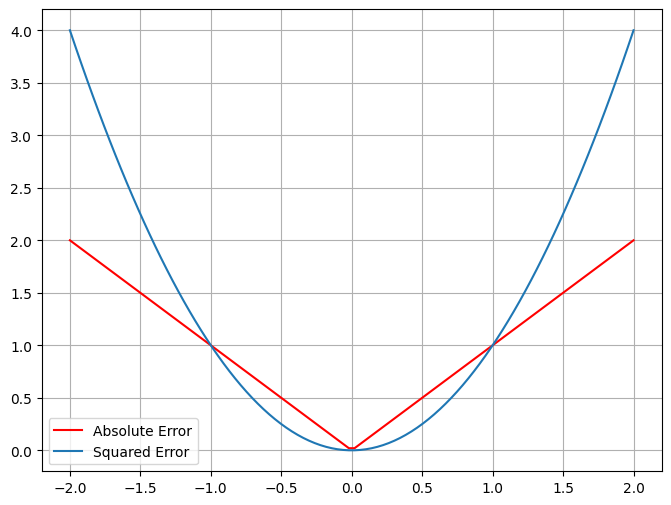

In [9]:
x = torch.linspace(-2,2,100)
ae = torch.abs(x)
se = x**2
plt.figure(figsize=(8,6))
plt.plot(x, ae, label="Absolute Error", c="r")
plt.plot(x, se, label="Squared Error")
plt.legend()
plt.grid(True)
plt.show()

Aunque su comportamiento general es parecido, hay algunas diferencias interesantes. La más obvia es que en valores de x ∈ (-1,1), el error cuadrático es menor que el error absoluto. Para el resto de los valores es igual (para {-1,1}) o mayor, y de hecho crece más rápido que el error absoluto. Comparemoslas en dos puntos distintos. Para x=0.5, el error absoluto señalará que hay un error de 0.5, mientras que el error cuadrático indicará que el error es de 0.25. Para x=2, el error absoluto indicará un error de 2, mientras que el error cuadrático indicará un error de 4. para x=3, el error absoluto indicará 3, el cuadrático indicará 9. ¡Es importante tener en cuenta el rango de valores en el que van a estar nuestros datos!

Hay una diferencia relevante más: el error cuadrático es derivable en todos los puntos, mientras que el error absoluto no es derivable en el 0. Por ahora no vamos a prestarle atención a eso, pero en el futuro volveremos a ese detalle.

Ahora que tenemos un par de maneras de cuantificar el *error* de nuestro problema. Vamos a ver cómo van encajando las piezas.

Si seguimos nuestra estrategia de *prueba y error*, lo que haríamos es tomar un punto cualquiera (xₙ,yₙ) de los datos de los que queremos aprender y lo vamos a *fijar*. Nuestros datos nos dicen que para x=xₙ, el modelo tendría que tener yₙ como resultado si estuviera bien ajustado. Ajustar el modelo en este caso, como hemos mencionado antes, consiste en ajustar el parámetro m (porque por simplificar el ejemplo asumimos b=0). Así que nuestras funciones de error lo que van a medir es la diferencia entre el resultado que consideramos cierto (yₙ) y el resultado que obtenemos (xₙ*m+b).

Vamos a ver qué aspecto tiene esa función de error según cómo modificamos m para un punto elegido arbitrariamente (4,4).

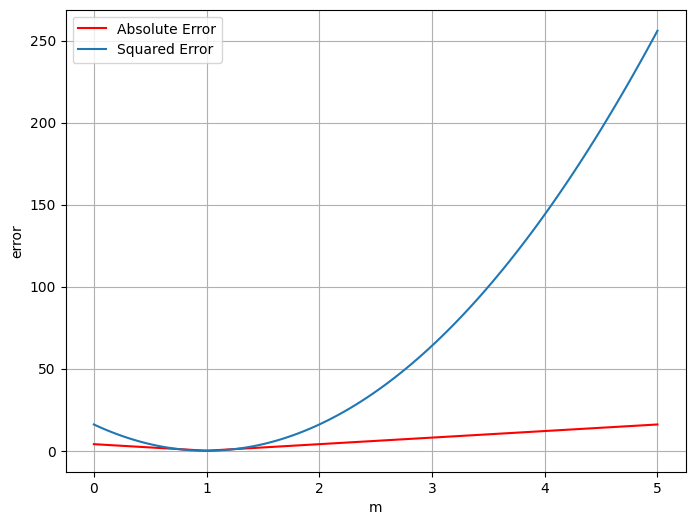

In [10]:
x_true, y_true = (4,4)
ae_list = []
se_list = []
b=0

m= torch.linspace(0,5,100)
y_pred = line_model(m,b,x_true)
ae_error = AE_loss(y_pred, y_true)
se_error = SE_loss(y_pred, y_true)

plt.figure(figsize=(8,6))
plt.plot(m, ae_error, label="Absolute Error", c="r")
plt.plot(m, se_error, label="Squared Error")
plt.legend()
plt.grid(True)
plt.xlabel("m")
plt.ylabel("error")
plt.show()

Como era de esperar, alterar la inclinación de nuestro modelo de recta tiene como consecuencia un cambio en el error. Podemos ver que el error se minimiza en m=1. Esto tiene sentido, ya que el punto (4,4) forma parte de la recta y=x. Si no hubieramos asumido b=0, habría infinitas soluciones que minimizan un punto dado. Con puntos que pertenezcan a rectas distintas obtendríamos el mínimo en lugares distintos.

Ahora que hemos visto cómo encaja la función de error con el modelo y los datos, vamos a intentar definir un algoritmo de optimización iterativo. Una opción sería probar valores aleatorios para m y cada vez que encontremos uno que tenga un error más bajo, actualizar m. Es una opción totalmente aleatoria que para un caso sencillo como este podría parecer aceptable, pero vamos a ir un paso más allá. Vamos a aprovechar la función de error para saber en qué dirección actualizar m.

Dado un punto (xₙ,yₙ) de los datos de entrenamiento y un valor del parámetro m=mₛ, vamos a estudiar qué ocurre si incrementamos o disminuimos ligeramente el parámetro m. Para eso vamos a definir un valor Δ y vamos a estudiar qué recta se ajusta mejor al punto dado, la recta con parámetro m=mₛ+Δ o la recta con parámetro m=mₛ-Δ.

La diferencia entre uno y otro la vamos a llamar ratio de cambio del error y vamos a actualizar el parámetro m con ese ratio tras normalizarlo (dividimos entre 2 Δ).

Usaremos el error absoluto para evitar retios de cambio del error muy grandes.

--------- step 0
m actual: 0.8
Dato escogido aleatoriamente (x_true,y_true): (tensor(45.7736), tensor(21.6058))
Valor de y predicho: 36.618896484375
Valor de y predicho 'bajando la m': 32.041534423828125, error: 10.435754776000977
Valor de y predicho 'aumentando la m': 41.196258544921875, error: 19.590478897094727
Ratio de cambio en la pérdida de m: -45.77362060546875, multiplicado por el ratio de aprendizaje: -45.77362060546875
--------- step 1
m actual: -44.9736213684082
Dato escogido aleatoriamente (x_true,y_true): (tensor(23.0586), tensor(12.2080))
Valor de y predicho: -1037.030517578125
Valor de y predicho 'bajando la m': -1039.3363037109375, error: 1051.5443115234375
Valor de y predicho 'aumentando la m': -1034.7247314453125, error: 1046.9327392578125
Ratio de cambio en la pérdida de m: 23.057861328125, multiplicado por el ratio de aprendizaje: 23.057861328125
--------- step 2
m actual: -21.915760040283203
Dato escogido aleatoriamente (x_true,y_true): (tensor(12.7930), tensor(8.1

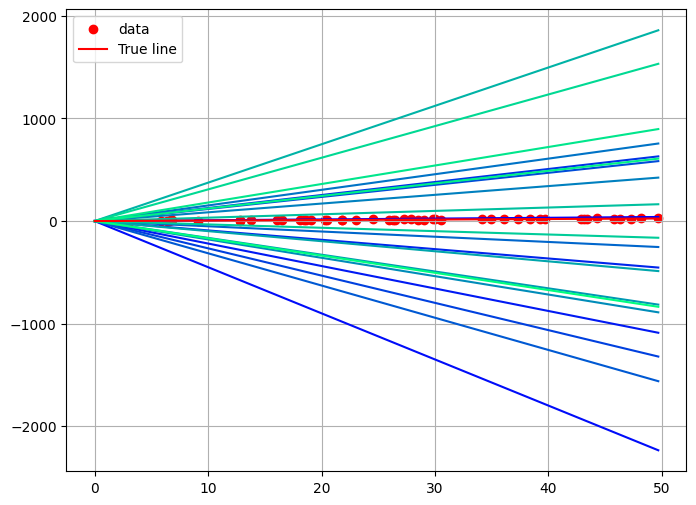

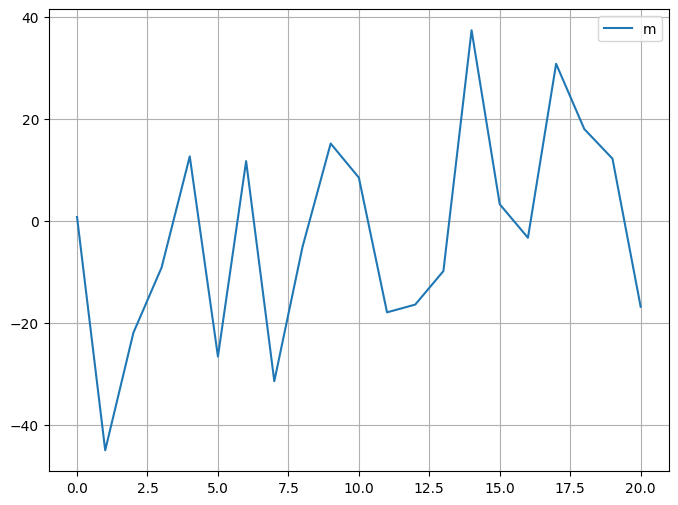

In [ ]:
delta = 0.1
steps = 20
loss_fn = AE_loss

true_m, true_b = [0.5,0]
data = get_data_from_a_line(true_m, true_b, 50)
m = 0.8                                         # Inicializamos la m a 0.8 con propósitos meramente didácticos. Debería ser aleatorio.
b = 0
line_evolution = [m]

for step in range(steps):
  # Obtenemos un dato aleatorio.
  random_index_to_select_data = torch.randint(low=0, high=data.size()[0], size=(1,))[0]
  random_point_from_data = data[random_index_to_select_data]
  x_true = random_point_from_data[0]
  y_true = random_point_from_data[1]

  # Calculamos el ratio de cambio de m.
  loss_rate_of_change_m = (loss_fn(line_model(m-delta,b,x_true), y_true) - loss_fn(line_model(m+delta,b,x_true), y_true)) / (2*delta)
  print(f"--------- step {step}")
  print(f"m actual: {m}")
  print(f"Dato escogido aleatoriamente (x_true,y_true): {x_true,y_true}")
  print(f"Valor de y predicho: {line_model(m,b,x_true)}")
  print(f"Valor de y predicho 'bajando la m': {line_model(m-delta,b,x_true)}, error: {loss_fn(line_model(m-delta,b,x_true), y_true)}")
  print(f"Valor de y predicho 'aumentando la m': {line_model(m+delta,b,x_true)}, error: {loss_fn(line_model(m+delta,b,x_true), y_true)}")
  print(f"Ratio de cambio en la pérdida de m: {loss_rate_of_change_m}")
  # Actualizamos la m.
  m = m + loss_rate_of_change_m
  line_evolution.append(m)

print(line_evolution)
plt.figure(figsize=(8,6))
colors = plt.cm.winter(torch.linspace(0,1,steps+1))
for index, m in enumerate(line_evolution):
  plt.plot([0,data.max()], [0,m*data.max()], c=colors[index])
plt.scatter(data[:,0], data[:,1], marker='o', c='r', label="data")
plt.plot([0,data.max()], [0,true_m*data.max()], c='r', label="True line")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8,6))
plt.plot(range(0, steps+1), line_evolution, label="m")
plt.legend()
plt.grid(True)
plt.show()

Vale. Esto es un caos. El valor m va saltando de un lado a otro alterado por valores de cambio en el orden de las decenas para un valor que está en el orden de las decimas. El error sube y baja a saltos y parece que en vez de ajustar la recta que deseamos nos estamos alejando de ella.

Vamos a introducir un *hiperparámetro* que condicione cómo evoluciona el parámetro m. Lo llamaremos *ratio de aprendizaje* porque va a condicionar cuando aprendemos del *ratio de cambio* del parámetro m.

--------- step 0
m actual: 0.8
Dato escogido aleatoriamente (x_true,y_true): (tensor(41.1856), tensor(24.5979))
Valor de y predicho: 32.948490142822266
Valor de y predicho 'bajando la m': 28.829927444458008, error: 4.232072830200195
Valor de y predicho 'aumentando la m': 37.06705093383789, error: 12.469196319580078
Ratio de cambio en la pérdida de m: -41.18561553955078, multiplicado por el ratio de aprendizaje: -0.041185617446899414
--------- step 1
m actual: 0.7588143944740295
Dato escogido aleatoriamente (x_true,y_true): (tensor(50.), tensor(25.0028))
Valor de y predicho: 37.94071960449219
Valor de y predicho 'bajando la m': 32.94071960449219, error: 7.937875747680664
Valor de y predicho 'aumentando la m': 42.94071960449219, error: 17.937875747680664
Ratio de cambio en la pérdida de m: -50.0, multiplicado por el ratio de aprendizaje: -0.05000000074505806
--------- step 2
m actual: 0.7088143825531006
Dato escogido aleatoriamente (x_true,y_true): (tensor(26.4694), tensor(12.7858))
Valo

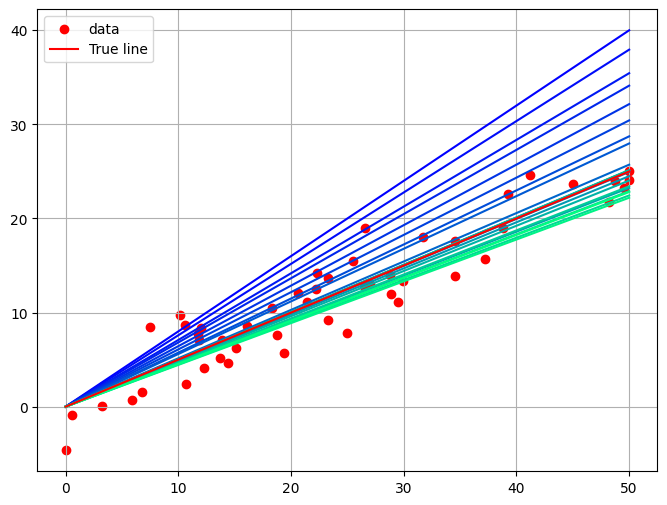

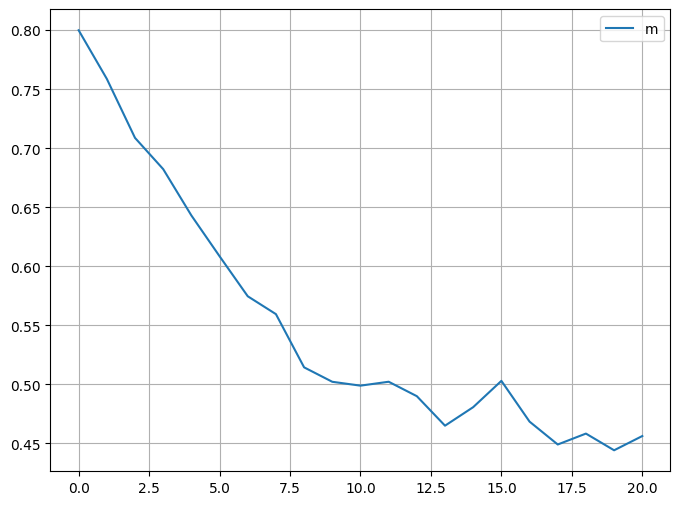

In [12]:
learning_rate = 1e-3
delta = 0.1
steps = 20
loss_fn = AE_loss

true_m, true_b = [0.5,0]
data = get_data_from_a_line(true_m, true_b, 50)
m = 0.8                                         # Inicializamos la m a 0.8 con propósitos meramente didácticos. Debería ser aleatorio.
b = 0
line_evolution = [m]

for step in range(steps):
  # Obtenemos un dato aleatorio.
  random_index_to_select_data = torch.randint(low=0, high=data.size()[0], size=(1,))[0]
  random_point_from_data = data[random_index_to_select_data]
  x_true = random_point_from_data[0]
  y_true = random_point_from_data[1]

  # Calculamos el ratio de cambio de m.
  loss_rate_of_change_m = (loss_fn(line_model(m-delta,b,x_true), y_true) - loss_fn(line_model(m+delta,b,x_true), y_true)) / (2*delta)
  print(f"--------- step {step}")
  print(f"m actual: {m}")
  print(f"Dato escogido aleatoriamente (x_true,y_true): {x_true,y_true}")
  print(f"Valor de y predicho: {line_model(m,b,x_true)}")
  print(f"Valor de y predicho 'bajando la m': {line_model(m-delta,b,x_true)}, error: {loss_fn(line_model(m-delta,b,x_true), y_true)}")
  print(f"Valor de y predicho 'aumentando la m': {line_model(m+delta,b,x_true)}, error: {loss_fn(line_model(m+delta,b,x_true), y_true)}")
  print(f"Ratio de cambio en la pérdida de m: {loss_rate_of_change_m}, multiplicado por el ratio de aprendizaje: {learning_rate*loss_rate_of_change_m}")
  # Actualizamos la m.
  m = m + learning_rate*loss_rate_of_change_m
  line_evolution.append(m)

print(line_evolution)
plt.figure(figsize=(8,6))
colors = plt.cm.winter(torch.linspace(0,1,steps+1))
for index, m in enumerate(line_evolution):
  plt.plot([0,data.max()], [0,m*data.max()], c=colors[index])
plt.scatter(data[:,0], data[:,1], marker='o', c='r', label="data")
plt.plot([0,data.max()], [0,true_m*data.max()], c='r', label="True line")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8,6))
plt.plot(range(0, steps+1), line_evolution, label="m")
plt.legend()
plt.grid(True)
plt.show()

Ahora parece que sí estamos ajustándonos. En la gráfica podemos ver cómo la evolución de la recta (las azules son los primeros pasos y las verdes los últimos) se acerca a la recta que usamos para generar los datos (rojo). Si analizamos la evolución numérica podemos ver que es algo irregular. A veces son positivos y otras veces negativos. Esto puede ocurrir, aunque es indeseable que un entrenamiento sea tan *inestable*. En este caso uno de los principales sospechosos de que ocurra es que los datos tienen ruido. Muy pocos de los datos que tenemos se ajustan bien a la recta con la que fueron generados. Como cogemos un dato de referencia cada vez, este dato puede quedar más o menos lejos de la recta que representa nuestro modelo en cada paso. ¡Puede incluso hacer que nuestro modelo se ajuste en la dirección equivocada!

Por suerte, eso tiene fácil solución. No cojamos un único dato. Vamos a usarlos todos en cada paso de entrenamiento. Para eso primero hay que hacerle unos pequeños ajustes a nuestras funciones de error.

In [22]:
def MAE_loss(y_pred, y_true):
  """
  Función para calcular la media del error absoluto.
  """
  absolute_error = torch.abs(y_pred-y_true)
  return absolute_error.mean()

def MSE_loss(y_pred, y_true):
  """
  Función para calcular la media del error cuadrático.
  """
  squared_error = (y_pred-y_true)**2
  return squared_error.mean()

Una vez nuestras funciones de error obtienen valores medios, podemos ajustar el proceso de entrenamiento del modelo para que trabaje con todos los datos siempre.

--------- step 0
m actual: 0.8
Valor medio de y: 10.713339805603027
Valor medio de y predicho: 17.369768142700195
Valor medio de y predicho 'bajando la m': 15.19854736328125, error: 4.966958522796631
Valor medio de y predicho 'aumentando la m': 19.540987014770508, error: 9.257625579833984
Ratio de cambio en la pérdida de m: -21.45333480834961, multiplicado por el ratio de aprendizaje: -0.021453335881233215
--------- step 1
m actual: 0.7785466909408569
Valor medio de y: 10.713339805603027
Valor medio de y predicho: 16.903968811035156
Valor medio de y predicho 'bajando la m': 14.732748031616211, error: 4.514253616333008
Valor medio de y predicho 'aumentando la m': 19.075191497802734, error: 8.794508934020996
Ratio de cambio en la pérdida de m: -21.401275634765625, multiplicado por el ratio de aprendizaje: -0.02140127681195736
--------- step 2
m actual: 0.7571454048156738
Valor medio de y: 10.713339805603027
Valor medio de y predicho: 16.439298629760742
Valor medio de y predicho 'bajando 

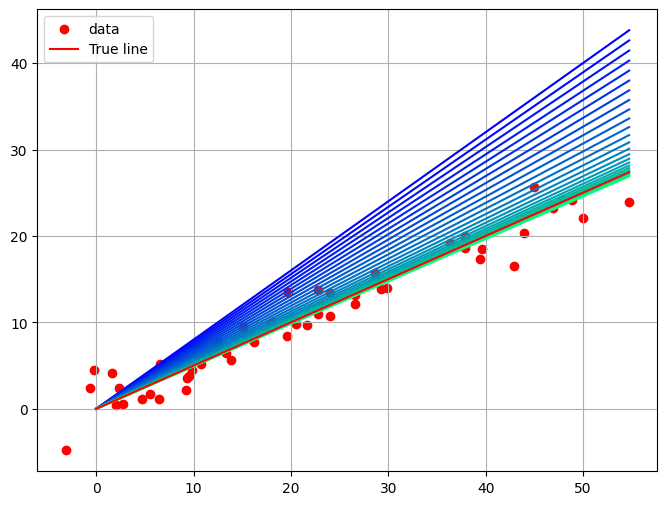

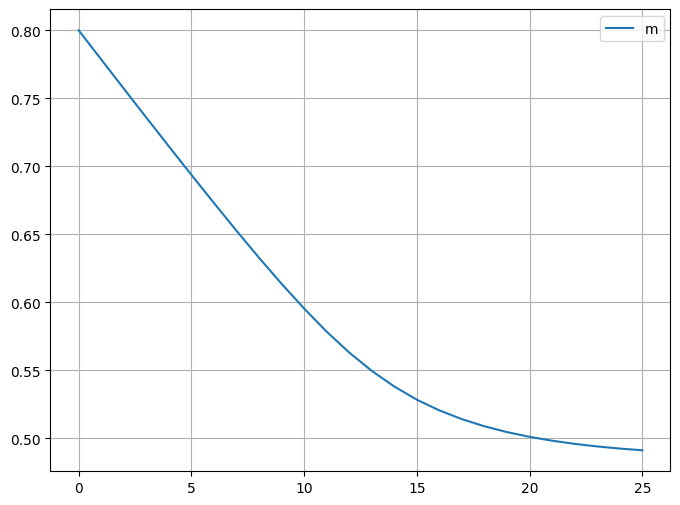

In [23]:
learning_rate = 1e-3
delta = 0.1
steps = 25
loss_fn = MAE_loss

true_m, true_b = [0.5,0]
data = get_data_from_a_line(true_m, true_b, 50)
m = 0.8                                         # Inicializamos la m a 0.8 con propósitos meramente didácticos.
b = 0
line_evolution = [m]

for step in range(steps):
  x_true = data[:,0]
  y_true = data[:,1]

  loss_rate_of_change_m = (loss_fn(line_model(m-delta,b,x_true), y_true) - loss_fn(line_model(m+delta,b,x_true), y_true)) / (2*delta)
  print(f"--------- step {step}")
  print(f"m actual: {m}")
  print(f"Valor medio de y: {y_true.mean()}")
  print(f"Valor medio de y predicho: {line_model(m,b,x_true).mean()}")
  print(f"Valor medio de y predicho 'bajando la m': {line_model(m-delta,b,x_true).mean()}, error: {loss_fn(line_model(m-delta,b,x_true), y_true)}")
  print(f"Valor medio de y predicho 'aumentando la m': {line_model(m+delta,b,x_true).mean()}, error: {loss_fn(line_model(m+delta,b,x_true), y_true)}")
  print(f"Ratio de cambio en la pérdida de m: {loss_rate_of_change_m}, multiplicado por el ratio de aprendizaje: {learning_rate*loss_rate_of_change_m}")
  m = m + learning_rate*loss_rate_of_change_m
  line_evolution.append(m)

plt.figure(figsize=(8,6))
colors = plt.cm.winter(torch.linspace(0,1,steps+1))
for index, m in enumerate(line_evolution):
  plt.plot([0,data.max()], [0,m*data.max()], c=colors[index])
plt.scatter(data[:,0], data[:,1], marker='o', c='r', label="data")
plt.plot([0,data.max()], [0,true_m*data.max()], c='r', label="True line")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8,6))
plt.plot(range(0, steps+1), line_evolution, label="m")
plt.legend()
plt.grid(True)
plt.show()

¡Lo que cambia una media! Ahora el ajuste es numéricamente estable, el ratio de cambio va disminuyendo a cada paso de entrenamiento y siempre avanza en la misma dirección. Como los datos se han generado con ruido gaussiano, los errores de unos y los de otros se compensan, así que la media es mucho más fiable para hacer el ajuste. Sin embargo, si nos fijamos, la recta no se está ajustando a m=0.5, sino a un valor ligeramente inferior. Esto seguramente se deba a que los datos se ajustan mejor a esa recta con una inclinación ligeramente inferior. Cuantos más datos generemos a partir de nuestra recta, mejor se ajustarán en general a ella. Un ajuste perfecto requeriría una cantidad infinita de datos.

Este proceso de entrenamiento tal como está tiene diversos problemas:

1.   Sirve para un parámetro, pero hacerlo con muchos sería muy ineficiente.
2.   El delta es una elección arbitraria cuyo valor va a determinar la velocidad de la convergencia y el margen de error de esta. Pisa un poco la función del ratio de aprendizaje. ¿Necesitamos los dos?
3. ¡No saca partido de la GPU!

En la siguiente sesión vamos a refinarlo :)

Recapitulación:

*   Hemos creado un sistema de aprendizaje iterativo muy sencillo para ajustar una recta a unos datos.
*   Hemos observado la necesidad de un modelo que ajustar.
*   Hemos visto la necesidad de una función de error que debe elegir el diseñador del sistema.
*   Hemos visto que la convergencia se puede controlar con algunos hiperparámetros que controlan cuánto actualizamos los parámetros.
*   Hemos visto la diferencia entre hacer un paso de entrenamiento solo con un parámetro y hacerlo con la media de todos.



---
# Parte 4: Aprendizaje en PyTorch II
---

In [12]:
import torch
import matplotlib.pyplot as plt

# Aprendizaje II

> Autor: Jorge García González (Universidad de Málaga)

> Última Actualización: 22/09/2026

> Asignatura: Programación para la Inteligencia Artificial

En la sesión anterior hemos visto cómo realizar un proceso de ajuste de parámetros iterativo en base a calcular las diferencias entre aumentar *ligeramente* y disminuir *ligeramente* el parámetro que queremos ajustar. Esa diferencia respecto al hiperparámetro la llamamos Δ y, aunque el proceso funciona, el hiperparámetro Δ resulta problemático. ¿Qué elegimos? ¿Uno muy pequeño? ¿Uno muy grande? Grande o pequeño son términos muy relativos. ¿En qué rango de valores estamos trabajando? ¿Cómo desciende la función?

Seguiremos trabajando con el ajuste de una recta así que vamos a rescatar algunas funciones de la sesión anterior:

In [13]:
def get_data_from_a_line(m, b, n, sigma=2, range=50):
  """
  Función que devuelve datos a partir de una recta. Recordemos que la ecuación de la recta está definida por y=mx+b.
  Args:
    m: inclinación de la recta.
    b: ordenada en el origen de la recta.
    n: número de datos que queremos obtener.
    sigma: desviación típica para el ruido que añadiremos a los datos (2 por defecto).
    range: extremo del rango [0,rango] en el eje x en el que queremos situar los datos (50 por defecto).
  """
  x = range*torch.rand(n)                                               # Generamos los datos en el eje x.
  y = m*x+b                                                             # Obtemeos la posición correspondiente en el eje y.
  noise_x = torch.normal(torch.zeros_like(y), sigma*torch.ones_like(y)) # Generamos un vector de ruido gaussiano para el eje x.
  noise_y = torch.normal(torch.zeros_like(y), sigma*torch.ones_like(y)) # Generamos un vector de ruido gaussiano para el eje y.
  x_with_noise = x + torch.clamp(noise_x,min=0)
  y_with_noise = y + noise_y

  data = torch.cat((x_with_noise[:,None], y_with_noise[:,None]), dim=1)
  return data

def line_model(m, b, inputs):
  """
  Functión para modelar una recta.
  Args:
    m: inclinación de la recta.
    b: ordenada en el origen de la recta.
    inputs: vector con los valores de entrada para ser calculados por el modelo.
  """
  return m*inputs+b

def AE_loss(y_pred, y_true):
  return torch.abs(y_pred - y_true)

def SE_loss(y_pred, y_true):
  return (y_pred-y_true)**2

def MAE_loss(y_pred, y_true):
  """
  Función para calcular la media del error absoluto.
  """
  absolute_error = torch.abs(y_pred-y_true)
  return absolute_error.mean()

def MSE_loss(y_pred, y_true):
  """
  Función para calcular la media del error cuadrático.
  """
  squared_error = (y_pred-y_true)**2
  return squared_error.mean()

En la sesión anterior observamos cómo cambiaba el error para un punto dado según cómo se alteraba la inclinación de la recta. Vamos ahora a ver cómo evoluciona alterando los dos parámetros (m y b).

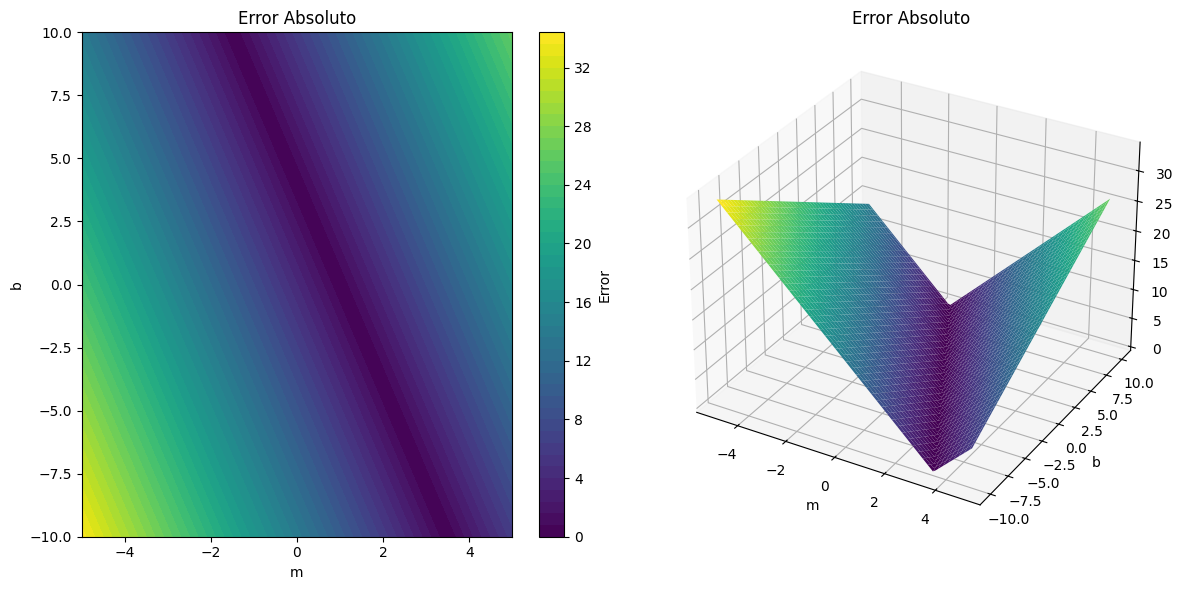

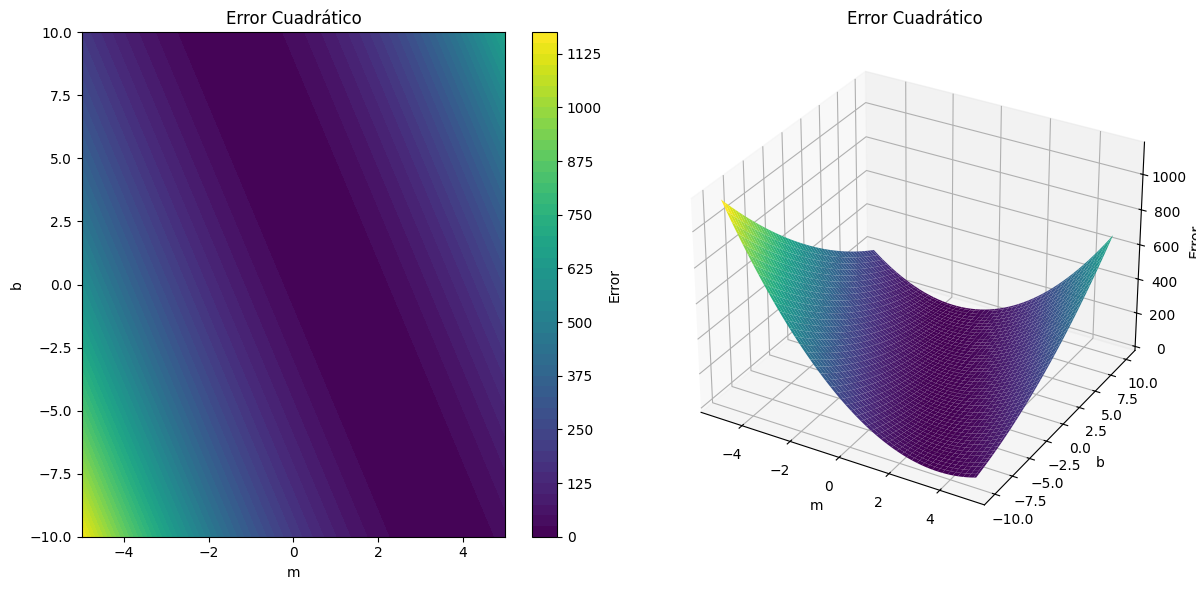

In [14]:
x_true, y_true = (4,4)
ae_list = []
se_list = []

m = torch.linspace(-5,5,100)
b = torch.linspace(-10,10,100)
M, B = torch.meshgrid(m, b, indexing='ij')   # Producto cartesiano
y_pred = line_model(M,B,x_true)
ae_error = AE_loss(y_pred, y_true)
se_error = SE_loss(y_pred, y_true)

# Mostramos el Error Absoluto
fig = plt.figure(figsize=(12, 6))

# Plotear un mapa de calor
ax1 = fig.add_subplot(1, 2, 1)
c = ax1.contourf(M, B, ae_error, levels=50, cmap="viridis")
fig.colorbar(c, ax=ax1, label="Error")
ax1.set_xlabel("m")
ax1.set_ylabel("b")
ax1.set_title("Error Absoluto")

# Superficie 3D
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
ax2.plot_surface(M, B, ae_error, cmap="viridis")
ax2.set_xlabel("m")
ax2.set_ylabel("b")
ax2.set_zlabel("Error")
ax2.set_title("Error Absoluto")

plt.tight_layout()
plt.show()

# Mostramos el Error Cuadrático
fig = plt.figure(figsize=(12, 6))

# Plotear un mapa de calor
ax1 = fig.add_subplot(1, 2, 1)
c = ax1.contourf(M, B, se_error, levels=50, cmap="viridis")
fig.colorbar(c, ax=ax1, label="Error")
ax1.set_xlabel("m")
ax1.set_ylabel("b")
ax1.set_title("Error Cuadrático")

# Superficie 3D
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
ax2.plot_surface(M, B, se_error, cmap="viridis")
ax2.set_xlabel("m")
ax2.set_ylabel("b")
ax2.set_zlabel("Error")
ax2.set_title("Error Cuadrático")

plt.tight_layout()
plt.show()

Ahora vamos a intentar ajustar los dos parámetros a la vez usando nuestro bucle de entrenamiento. Vamos a generar los datos por separado porque vamos a trabajar con ellos varias veces.

In [15]:
true_m, true_b = [1,5]
data = get_data_from_a_line(true_m, true_b, 50, sigma=1, range=5)

--------- step 0
m actual: 3
Valor medio de y: 7.543177604675293
Valor medio de y predicho: 11.61306381225586
Valor medio de y predicho 'bajando la m': 10.177552223205566, error: 3.110626220703125
Valor medio de y predicho 'aumentando la m': 13.048574447631836, error: 5.816106796264648
Ratio de cambio en la pérdida de m: -2.7054805755615234, multiplicado por el ratio de aprendizaje: -0.0270548053085804
b actual: 3
Valor medio de y: 7.543177604675293
Valor medio de y predicho: 11.61306381225586
Valor medio de y predicho 'bajando la b': 11.11306381225586, error: 4.087155342102051
Valor medio de y predicho 'aumentando la b': 12.11306381225586, error: 4.810568332672119
Ratio de cambio en la pérdida de b: -0.7234129905700684, multiplicado por el ratio de aprendizaje: -0.007234129589051008
Actualizamos m y b.
--------- step 1
m actual: 2.972945213317871
Valor medio de y: 7.543177604675293
Valor medio de y predicho: 11.528154373168945
Valor medio de y predicho 'bajando la m': 10.0926437377929

Valor medio de y predicho 'aumentando la b': 7.7955427169799805, error: 1.0910605192184448
Ratio de cambio en la pérdida de b: 0.21804487705230713, multiplicado por el ratio de aprendizaje: 0.0021804487332701683
Actualizamos m y b.
--------- step 431
m actual: 1.2891244888305664
Valor medio de y: 7.543177604675293
Valor medio de y predicho: 7.2959136962890625
Valor medio de y predicho 'bajando la m': 5.860403537750244, error: 1.7257968187332153
Valor medio de y predicho 'aumentando la m': 8.731424331665039, error: 1.7886991500854492
Ratio de cambio en la pérdida de m: -0.06290233135223389, multiplicado por el ratio de aprendizaje: -0.0006290232995525002
b actual: 3.5948104858398438
Valor medio de y: 7.543177604675293
Valor medio de y predicho: 7.2959136962890625
Valor medio de y predicho 'bajando la b': 6.795914173126221, error: 1.308464527130127
Valor medio de y predicho 'aumentando la b': 7.7959136962890625, error: 1.090670108795166
Ratio de cambio en la pérdida de b: 0.2177944183349

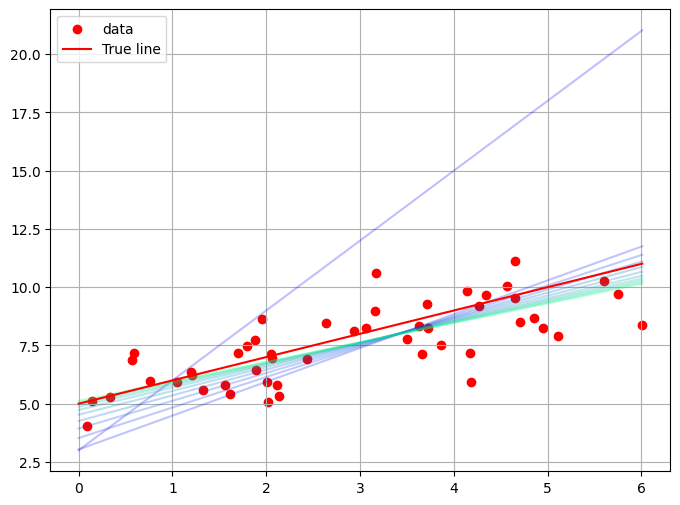

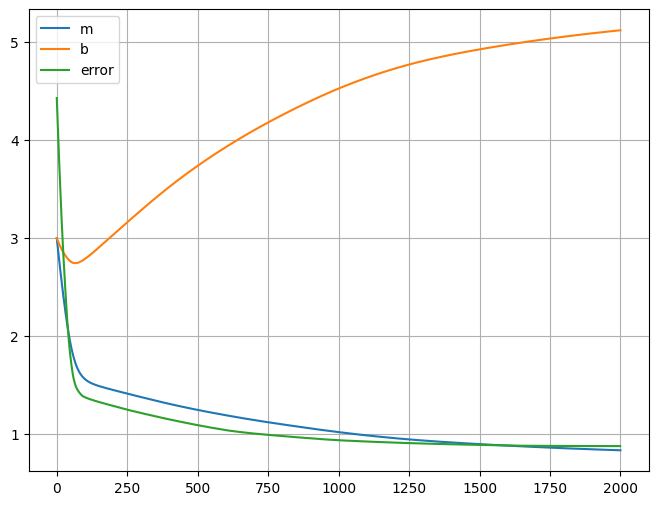

In [16]:
learning_rate = 1e-2
delta = 0.5
steps = 2000
loss_fn = MAE_loss

m, b = [3,3]                                        # Inicializamos la m y b con propósitos meramente didácticos. Deberían ser aleatorios.
line_evolution = [(m,b)]
error_evolution = []

for step in range(steps):
  x_true = data[:,0]
  y_true = data[:,1]
  error_evolution.append(loss_fn(line_model(m,b,x_true), y_true))

  loss_rate_of_change_m = (loss_fn(line_model(m-delta,b,x_true), y_true) - loss_fn(line_model(m+delta,b,x_true), y_true)) / (2*delta)
  print(f"--------- step {step}")
  print(f"m actual: {m}")
  print(f"Valor medio de y: {y_true.mean()}")
  print(f"Valor medio de y predicho: {line_model(m,b,x_true).mean()}")
  print(f"Valor medio de y predicho 'bajando la m': {line_model(m-delta,b,x_true).mean()}, error: {loss_fn(line_model(m-delta,b,x_true), y_true)}")
  print(f"Valor medio de y predicho 'aumentando la m': {line_model(m+delta,b,x_true).mean()}, error: {loss_fn(line_model(m+delta,b,x_true), y_true)}")
  print(f"Ratio de cambio en la pérdida de m: {loss_rate_of_change_m}, multiplicado por el ratio de aprendizaje: {learning_rate*loss_rate_of_change_m}")
  

  loss_rate_of_change_b = (loss_fn(line_model(m,b-delta,x_true), y_true) - loss_fn(line_model(m,b+delta,x_true), y_true)) / (2*delta)
  print(f"b actual: {b}")
  print(f"Valor medio de y: {y_true.mean()}")
  print(f"Valor medio de y predicho: {line_model(m,b,x_true).mean()}")
  print(f"Valor medio de y predicho 'bajando la b': {line_model(m,b-delta,x_true).mean()}, error: {loss_fn(line_model(m,b-delta,x_true), y_true)}")
  print(f"Valor medio de y predicho 'aumentando la b': {line_model(m,b+delta,x_true).mean()}, error: {loss_fn(line_model(m,b+delta,x_true), y_true)}")
  print(f"Ratio de cambio en la pérdida de b: {loss_rate_of_change_b}, multiplicado por el ratio de aprendizaje: {learning_rate*loss_rate_of_change_b}")
  
  print(f"Actualizamos m y b.")
  m = m + learning_rate*loss_rate_of_change_m
  b = b + learning_rate*loss_rate_of_change_b

  line_evolution.append((m,b))

plt.figure(figsize=(8,6))
plt.scatter(data[:,0], data[:,1], marker='o', c='r', label="data")
colors = plt.cm.winter(torch.linspace(0,1,steps+1))
for index, (m,b) in enumerate(line_evolution):
  if index%(steps/10)==0:
    plt.plot([0,data[:,0].max()], [line_model(m,b,0),line_model(m,b,data[:,0].max())], c=colors[index], alpha=0.25)
plt.plot([0,data[:,0].max()], [line_model(true_m,true_b,0),line_model(true_m,true_b,data[:,0].max())], c='r', label="True line")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8,6))
plt.plot(range(0, steps+1), [m for (m,b) in line_evolution], label="m")
plt.plot(range(0, steps+1), [b for (m,b) in line_evolution], label="b")
plt.plot(range(0, steps), error_evolution, label = "error")
plt.legend()
plt.grid(True)
plt.show()


Como podemos observar, cada parámetro aumenta o disminuye el error "a una velocidad distinta". Un cambio en el parámetro m altera el error más que un cambio en el parámetro b. Si el hiperparámetro Δ determina cuánto alteramos un parámetro para obtener el ratio de cambio, el mismo valor para dos parámetros que hacen cambiar la función a ritmos distintos es problemático. Un buen valor de Δ para un parámetro podría ser uno malo para el otro. ¿Qué hacemos? ¿Elegimos un Δ para cada parámetro? Si tenemos mil parámetros, ¿elegimos mil valores? No parece muy práctico. Mejor eliminar ese hiperparámetro :)

Y para eliminarlo vamos a usar el gradiente (representado con ∇) de la función de error. Intuitivamente podemos entender el vector gradiente de una función calculado en un punto como la dirección en la que la función varía más rápidamente y su módulo representa el ritmo de variación en dicha dirección.

Más información: https://es.wikipedia.org/wiki/Gradiente

Justo lo que necesitamos. Usábamos el hierparámetro Δ para hacer un cálculo que indique hacia dónde alterar el parámetro. El gradiente es otra manera de obtener esa información. ¡Necesitamos calcular el gradiente del error en un punto concreto!

¿Cómo se calcula el gradiente? Obteniendo las derivadas parciales. Concretamente necesitaremos derivar funciones compuestas ya que el error se calcula a partir del modelo, así que vamos a repasar cómo se deriva una función compuesta.

Recordemos la Regla de la Cadena (o Teorema de las Funciones Compuestas, que suena mucho mejor). Esta regla dice que la derivada de una función compuesta $h(x) = f(g(x))$ se calcula como:

$h(x)dx = (f(g(x))dx)(g(x)dx)$

Más información: https://es.wikipedia.org/wiki/Regla_de_la_cadena

La regla de la cadena es clave en todo lo que vamos a hacer. En nuestro caso tenemos la función de error (que vamos a llamar 𝘓) que depende de la función que representa nuestro modelo de recta (que vamos a llamar r<sub>m,b</sub> indicando que es una función que depende de los parámetros m y b). Dado un dato conocido (xₙ,yₙ) y unos parámetros m y b, el error es 𝘓(r<sub>m,b</sub>(xₙ), yₙ). Para obtener el gradiente de los parámetros debemos obtener las derivadas parciales respecto a cada uno de esos parámetros.

$\nabla_{m,b} L = (\frac{\delta L}{\delta m}, \frac{\delta L}{\delta b})$

Y aplicando la regla de la cadena:

$(\frac{\delta L}{\delta m}, \frac{\delta L}{\delta b}) = (\frac{\delta L}{\delta r_{m,b}} \frac{\delta r_{m,b}}{\delta m}, \frac{\delta L}{\delta r_{m,b}} \frac{\delta r_{m,b}}{\delta b})$

En definitiva, debemos obtener la derivada de la función de error respecto al modelo ($\frac{\delta L}{\delta r_{m,b}}$) y las derivadas parciales de nuestro modelo respecto a cada parámetro ($\frac{\delta r_{m,b}}{\delta m}$, $\frac{\delta r_{m,b}}{\delta b}$).

Vamos a empezar por las derivadas de nuestras funciones de error. Estamos trabajando con errores medios. Para "derivar" la media no hay más que entenderla como una sucesión de sumas multiplicada por una constante (1/N con N el número de elementos en la suma). La derivada de la suma es la suma de las derivadas y la derivada de una constante por una función es la constante por la derivada de la función. Vamos, que derivar una media es hacer la media de las derivadas. Para que quede más claro, vamos a implementar la derivada de la función para cada elemento y luego aplicaremos la media.

En el caso del error cuadrático, la derivada es sencilla: $x²dx = 2x$.

El error absoluto medio es también sencillo, pero tiene un problema: no es derivable en todo el dominio. El valor absoluto es una función definida a trozos ($f(x)=x$ si $x>=0$, $f(x)=-x$ si $x<0$). Una función definida a trozos solo es derivable si coinciden las derivadas laterales en los puntos de transición. En este caso no coinciden. ¡La función no es derivable en el 0!

Sin embargo... nos da igual. Es un problema menor ya que en cada trozo la derivada tiene un valor constante (-1 si x<0, 1 si x>0). Podemos decidir arbitrariamente si en el 0 devolver un valor -1 o un valor 1 simplemente para evitar un problema numérico. ¿Tiene esto mucha justificación matemática? No, pero cumple su función. Más problemático sería si la no derivabilidad fuera consecuencia de una indeterminación.

Nota: En esta implementación veréis que no he hecho la media de las derivadas, sino que devuelvo la derivada para todos los puntos. La media la hago más adelante :)

In [17]:
def AE_loss_d_y_pred(y_pred, y_true):
  """
  Derivada del error absoluto.
  """
  absolute_error_d_y_pred = ((y_pred-y_true)>=0)*1+((y_pred-y_true)<0)*-1
  return absolute_error_d_y_pred

def SE_loss_d_y_pred(y_pred, y_true):
  """
  Derivada del error cuadrático.
  """
  squared_error_d_y_pred = 2*(y_pred-y_true)
  return squared_error_d_y_pred

Una vez tenemos la derivada de las funciones de error, ahora necesitamos las derivadas parciales del modelo. Las parciales de $y=mx+b$ respecto a los parámetros m y b son triviales.

In [18]:
def line_model_d_m(m, b, inputs):
  """
  Derivada respecto a la m de la functión para modelar una recta.
  Args:
    m: inclinación de la recta.
    b: ordenada en el origen de la recta.
    inputs: vector con los valores de entrada para ser calculados por el modelo.
  """
  return inputs

def line_model_d_b(m,b,inputs):
  """
  Derivada respecto a la b de la functión para modelar una recta.
  Args:
    m: inclinación de la recta.
    b: ordenada en el origen de la recta.
    inputs: vector con los valores de entrada para ser calculados por el modelo.
  """
  return 1.0


Finalmente componemos una función gradiente para cada función de error usando la regla de la cadena.

Nota: Hago la media correspondiente a la derivada de la media de los errores ahora. ¿Por qué? Porque así multiplicamos elemento a elemento la derivada de la función de error con la parcial del modelo. Estamos, por tanto, haciendo el cálculo del gradiente para cada punto y luego hacemos la media. Teóricamente debería ser lo mismo.

In [19]:
def grad_MAE(x_true, y_pred, y_true, m, b):
  ae_loss_d_y_pred = AE_loss_d_y_pred(y_pred, y_true)
  ae_loss_d_m = ae_loss_d_y_pred * line_model_d_m(m,b, x_true)
  ae_loss_d_b = ae_loss_d_y_pred * line_model_d_b(m,b, x_true)
  mae_loss_d_m = ae_loss_d_m.mean()
  mae_loss_d_b = ae_loss_d_b.mean()
  return torch.stack([mae_loss_d_m, mae_loss_d_b])

def grad_MSE(x_true, y_pred, y_true, m, b):
  se_loss_d_y_pred = SE_loss_d_y_pred(y_pred, y_true)
  se_loss_d_m = se_loss_d_y_pred * line_model_d_m(m,b, x_true)
  se_loss_d_b = se_loss_d_y_pred * line_model_d_b(m,b, x_true)
  mse_loss_d_m = se_loss_d_m.mean()
  mse_loss_d_b = se_loss_d_b.mean()
  return torch.stack([mse_loss_d_m, mse_loss_d_b])

Vamos a ver cómo queda nuestro nuevo algoritmo de ajuste de parámetros.

--------- step 0
m,b actual: (3, 3)
Valor medio de y: 7.543177604675293
Valor medio de y predicho: 11.61306381225586
Gradiente: tensor([2.7711, 0.7600]), actualización de m: -0.02771075814962387 actualización de b: -0.007599999662488699
--------- step 1
m,b actual: (tensor(2.9723), tensor(2.9924))
Valor medio de y: 7.543177604675293
Valor medio de y predicho: 11.52590560913086
Gradiente: tensor([2.7711, 0.7600]), actualización de m: -0.02771075814962387 actualización de b: -0.007599999662488699
--------- step 2
m,b actual: (tensor(2.9446), tensor(2.9848))
Valor medio de y: 7.543177604675293
Valor medio de y predicho: 11.43874740600586
Gradiente: tensor([2.7711, 0.7600]), actualización de m: -0.02771075814962387 actualización de b: -0.007599999662488699
--------- step 3
m,b actual: (tensor(2.9169), tensor(2.9772))
Valor medio de y: 7.543177604675293
Valor medio de y predicho: 11.35158920288086
Gradiente: tensor([2.7711, 0.7600]), actualización de m: -0.02771075814962387 actualización de

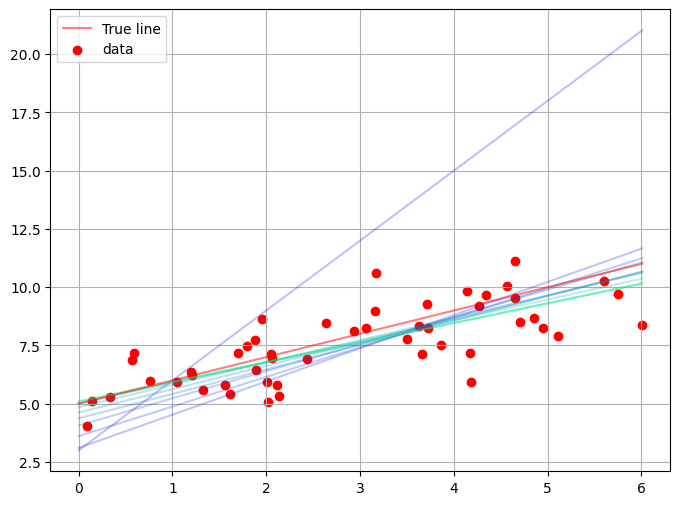

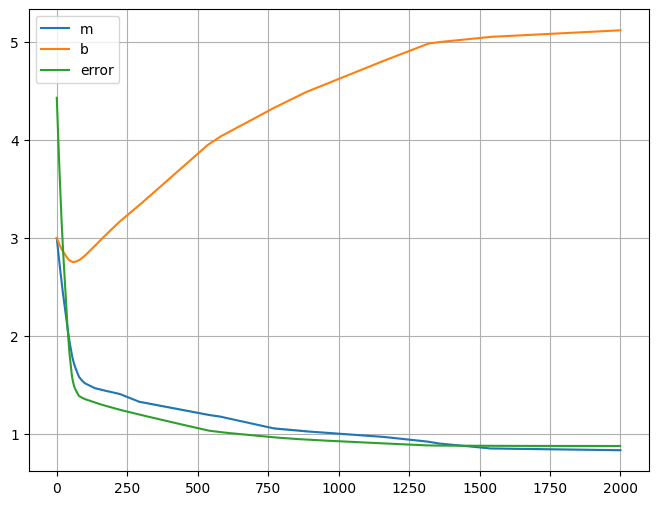

In [20]:
learning_rate = 1e-2
steps = 2000
loss_fn = MAE_loss
loss_fn_grad = grad_MAE

m, b = [3,3]                                        # Inicializamos la m y b con propósitos meramente didácticos. Deberían ser aleatorios.
line_evolution_m = [m]
line_evolution_b = [b]
error_evolution = []

for step in range(steps):
  x_true = data[:,0]
  y_true = data[:,1]
  y_pred = line_model(m, b, x_true)                   # Forward
  loss = loss_fn(y_pred, y_true)
  error_evolution.append(loss)
  grad = loss_fn_grad(x_true, y_pred, y_true, m, b)   # Backward
  print(f"--------- step {step}")
  print(f"m,b actual: {m,b}")
  print(f"Valor medio de y: {y_true.mean()}")
  print(f"Valor medio de y predicho: {y_pred.mean()}")
  print(f"Gradiente: {grad}, actualización de m: {-learning_rate*grad[0]} actualización de b: {-learning_rate*grad[1]}")
  m = m - learning_rate*grad[0]
  b = b - learning_rate*grad[1]
  line_evolution_m.append(m)
  line_evolution_b.append(b)

plt.figure(figsize=(8,6))
colors = plt.cm.winter(torch.linspace(0,1,steps+1))
for index, (m, b) in enumerate(zip(line_evolution_m, line_evolution_b)):
  if index%(steps/10)==0:
    plt.plot([0,data[:,0].max()], [m*0+b,m*data[:,0].max()+b], c=colors[index], alpha=0.25)
plt.plot([0,data[:,0].max()], [true_m*0+true_b,true_m*data[:,0].max()+true_b], c='r', label="True line", alpha=0.5)
plt.scatter(data[:,0], data[:,1], marker='o', c='r', label="data")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8,6))
plt.plot(range(0, steps+1), [m for m in line_evolution_m], label="m")
plt.plot(range(0, steps+1), [b for b in line_evolution_b], label="b")
plt.plot(range(0, steps), error_evolution, label = "error")
plt.legend()
plt.grid(True)
plt.show()

Parece que funciona, pero hay algunas cosas llamativas. Se puede notar que ahora *restamos* a la hora de ajustar la variable. Esto se debe a que el gradiente conceptualmente nos da la dirección de incremento y nosotros queremos minimizar. ¡Δ ha muerto, larga vida a ∇!

Además hay dos líneas que hemos señalado como *forward* y *backward*. Por convención denominamos *forward* como el *paso hacia adelante* del modelo (realizar la predicción). Con *backward* nos referimos al *paso hacia atrás* (calcular los gradientes).

Entonces es de suponer que para trabajr en Aprendizaje Profundo habrá que pasarse el día definiendo derivadas. En este caso nuestro modelo solo tiene dos parámetros, pero un modelo con millones de parámetros requerirá definir millones de derivadas parciales ^^U

Por suerte, derivar es un proceso que consiste en seguir reglas. Se puede automatizar y de hecho... PyTorch lo tiene automatizado :)

La mayoría de las funciones integradas en PyTorch ya tienen programadas sus derivadas y PyTorch tiene un sistema denominado autograd para obtener automáticamente los gradientes de la composición de funciones si esas funciones se han hecho con PyTorch.

In [21]:
tensor_a = torch.tensor(2., requires_grad=True)
print(f"a: {tensor_a}")

tensor_b = tensor_a**3
print(f"b: {tensor_b}")

print(f"Gradiente de la función x**3 respecto al tensor_a: {tensor_a.grad}")

tensor_b.backward()
print(f"Gradiente de la función x**3 respecto al tensor_a: {tensor_a.grad}")

a: 2.0
b: 8.0
Gradiente de la función x**3 respecto al tensor_a: None
Gradiente de la función x**3 respecto al tensor_a: 12.0


En el ejemplo definimos un tensor con valor 2 y calculamos un segundo tensor elevando al cubo. Podemos indicarle a PyTorch que calcule el gradiente (realice el *backward* o paso hacia atrás) desde los resultados y si no se lo indicamos no lo realiza. Calcular los gradientes puede no ser un cálculo computacionalmente trivial, así que no lo hace por defecto.

Cuando operamos con un tensor cuyo gradiente se requiere, PyTorch lleva un registro de las operaciones en las que está implicado. Este registro es el grafo de operaciones ( o grafo d ecómputo), en el que los tensores cuyo gradiente se requiere deberían ser nodos hoja (interpretando que el grafo se extiende desde las últimas operaciones). Cuando llamamos a .backward() desde un nodo resultado de alguna operación, PyTorch recorre el grafo hacia atrás calculando las derivadas hasta los nodos hoja que requieren gradiente. Obtenemos así el resultado de la derivada parcial respecto a cada tensor hoja.

En el ejemplo de arriba el tensor hoja es a, la única operación es elevarlo al cubo y el resultao es b. Calcular el backward hacia atrás es solo calcular la derivada de x<sup>3</sup>. La derivada es 3x<sup>2</sup>, que para la entrada (2), tiene resultado 12. Ese es el valor del gradiente.

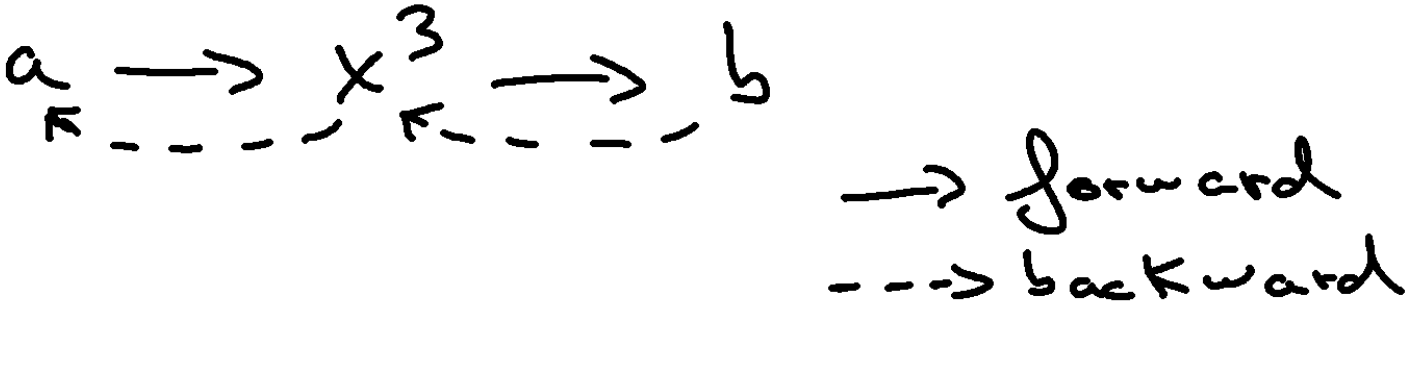

Por supuesto, funciones habituales de error como el error cuadrático medio o el error absoluto están ya implementadas en PyTorch (y precompiladas, así que serán más rápidas que una implementación nuestra).

Las podemos encontrar como L1Loss (error absoluto) y MSELoss (error cuadrático). ¿Por qué L1 en vez de MAE? Simplemente hace referencia a que matemáticamente se lo conoce como la norma L1. EL MSE a veces se denomina norma L2. PyTorch decidió mezclar nomenclaturas.

L1Loss: https://docs.pytorch.org/docs/stable/generated/torch.nn.L1Loss.html

MSELoss: https://docs.pytorch.org/docs/stable/generated/torch.nn.MSELoss.html

Así que podemos hacer de nuevo nuestro algoritmo de aprendizaje usando las funciones de PyTorch.

--------- step 0
m,b actual: (tensor(3., requires_grad=True), tensor(3., requires_grad=True))
Valor medio de y: 7.543177604675293
Valor medio de y predicho: 11.61306381225586
Gradiente: [tensor(2.7711), tensor(0.7600)]
Actualización de m: -0.02771075814962387
Actualización de b: -0.007599999662488699
--------- step 1
m,b actual: (tensor(2.9723, requires_grad=True), tensor(2.9924, requires_grad=True))
Valor medio de y: 7.543177604675293
Valor medio de y predicho: 11.52590560913086
Gradiente: [tensor(2.7711), tensor(0.7600)]
Actualización de m: -0.02771075814962387
Actualización de b: -0.007599999662488699
--------- step 2
m,b actual: (tensor(2.9446, requires_grad=True), tensor(2.9848, requires_grad=True))
Valor medio de y: 7.543177604675293
Valor medio de y predicho: 11.43874740600586
Gradiente: [tensor(2.7711), tensor(0.7600)]
Actualización de m: -0.02771075814962387
Actualización de b: -0.007599999662488699
--------- step 3
m,b actual: (tensor(2.9169, requires_grad=True), tensor(2.977

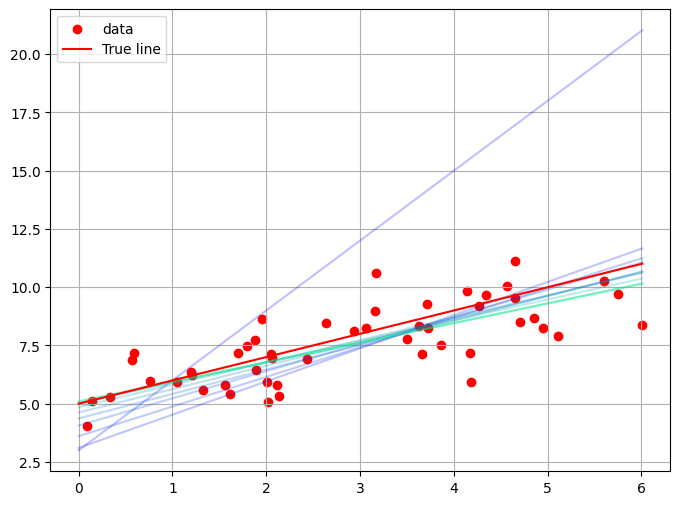

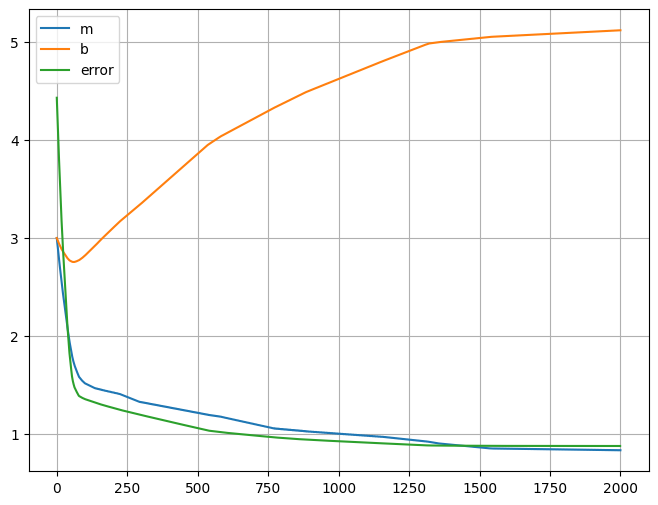

In [22]:
learning_rate = 1e-2
steps = 2000
loss_fn = torch.nn.L1Loss()

m = torch.tensor(3., requires_grad=True)             # Inicializamos la m y la b a 3 con propósitos meramente didácticos.
b = torch.tensor(3., requires_grad=True)
line_evolution_m = [m.clone().detach()]               # A las listas no añadimos el parámetro, sino una copia que nos aseguramos
line_evolution_b = [b.clone().detach()]               # de sacar del grafo usando un detach()
error_evolution = []

for step in range(steps):
  if m.grad is not None:
    m.grad.zero_()
  if b.grad is not None:
    b.grad.zero_()

  x_true = data[:,0]
  y_true = data[:,1]
  y_pred = line_model(m, b, x_true)                   # Forward
  loss = loss_fn(y_pred, y_true)
  loss.backward()                                     # Backward
  error_evolution.append(loss.clone().detach())
  grad = [m.grad, b.grad]
  print(f"--------- step {step}")
  print(f"m,b actual: {m,b}")
  print(f"Valor medio de y: {y_true.mean()}")
  print(f"Valor medio de y predicho: {y_pred.mean()}")
  print(f"Gradiente: {grad}")
  print(f"Actualización de m: {-learning_rate*grad[0]}")
  print(f"Actualización de b: {-learning_rate*grad[1]}")
  with torch.no_grad():
    #m = m - learning_rate*grad[0]                        # No funciona
    #m = (m - learning_rate*grad[0]).requires_grad_(True) # Funciona, pero es un poco engorroso.
    m -= learning_rate*grad[0]                            # Funciona, es más "elegante" y más eficiente.
    b -= learning_rate*grad[1]                          
  line_evolution_m.append(m.clone().detach())
  line_evolution_b.append(b.clone().detach())

plt.figure(figsize=(8,6))
colors = plt.cm.winter(torch.linspace(0,1,steps+1))
for index, (m, b) in enumerate(zip(line_evolution_m, line_evolution_b)):
  if index%(steps/10)==0:
    plt.plot([0,data[:,0].max()], [m*0+b,m*data[:,0].max()+b], c=colors[index], alpha=0.25)
plt.scatter(data[:,0], data[:,1], marker='o', c='r', label="data")
plt.plot([0,data[:,0].max()], [true_m*0+true_b,true_m*data[:,0].max()+true_b], c='r', label="True line")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8,6))
plt.plot(range(0, steps+1), [m for m in line_evolution_m], label="m")
plt.plot(range(0, steps+1), [b for b in line_evolution_b], label="b")
plt.plot(range(0, steps), error_evolution, label = "error")
plt.legend()
plt.grid(True)
plt.show()

En este caso el grafo de operaciones es un poco más complicado, pero sería algo así (omitiendo variables intermedias y abstrayendo el cálculo de la L1):

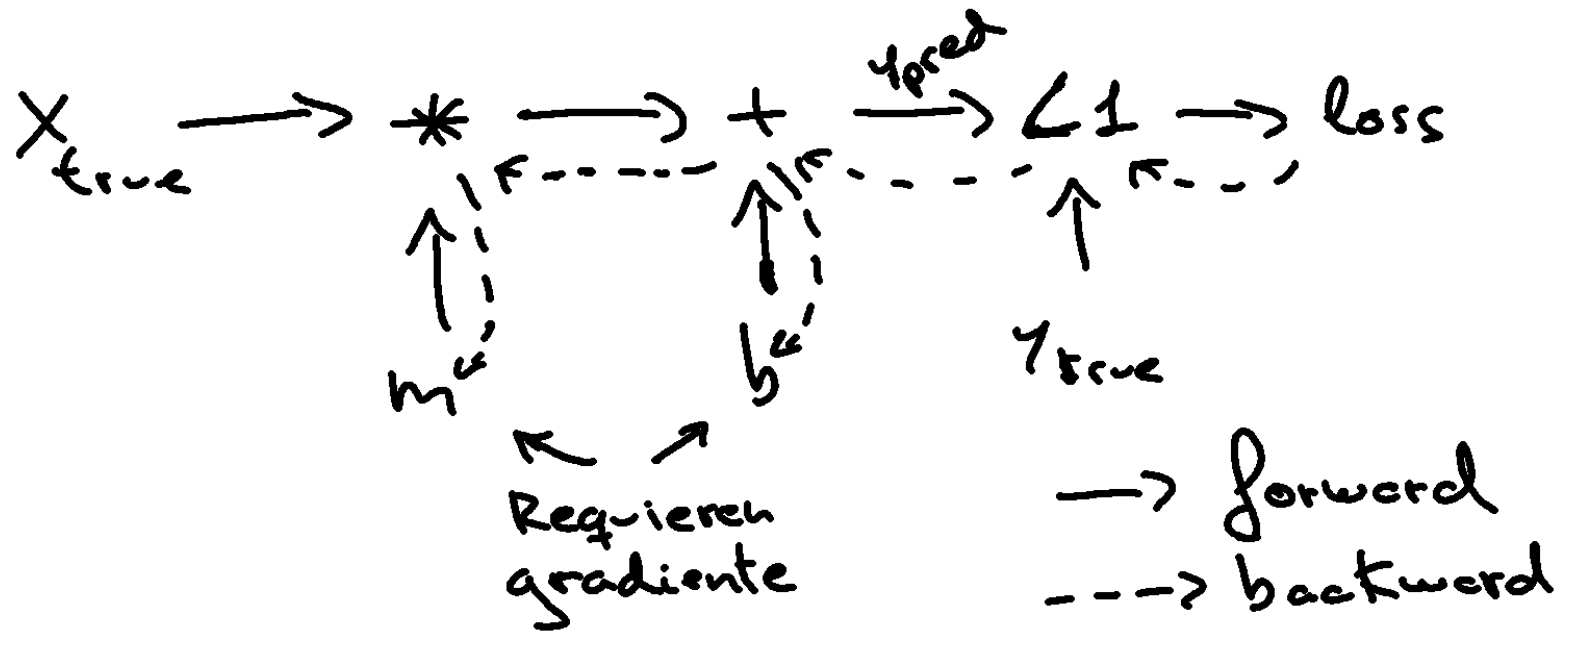

Hay varias cosas llamativas más allá de los cambios en la función de error, ¿verdad? Vamos a verlas una a una.

*   Para empezar, hemos necesitado indicarle a PyTorch que requeriremos el gradiente de los parámetros. Le estamos diciendo explícitamente que construya un grafo de computación con las operaciones que hagamos a partir de ellos.
*   Después podemos ver que al añadirlos a las listas estamos haciendo copias (.clone) y aplicamos un .detach a esa copia. El detach es una forma de indicarle a PyTorch que esa variable hay que sacarla del grafo de computación para obtener gradientes. Si no lo hacemos, dará un error matplotlib indicando que no puede trabajar con datos que requieren gradiente.
*   m.grad.zero_() es una manera de indicarle a PyTorch que devuelva el gradiente acumulado en ese tensor a 0. PyTorch funciona *acumulando* gradientes. Si calculamos varias veces el gradiente respecto a un parámetro lo *suma* al anterior y nosotros no queremos ese comportamiento.
*   Llamamos explícitamente al procedimiento .backward() de la función de error. ¡PyTorch se encarga de hacer el cálculo del gradiente respecto a los parámetros que lo requieren en ese momento!
* with torch.nograd es una manera de indicarle a PyTorch que el contexto encapsulado por el with no lo tenga en cuenta a la hora de crear el grafo de computación para calcular gradientes. ¡No nos interesa añadir la actualización de los parámetros al cálculo del gradiente!

También se pueden observar varias opciones para actualizar el parámetro m. La primera y más directa no funciona porque crea otro tensor m (con el mismo nombre, sí, pero otro tensor) que por defecto no requiere gradiente. Hacerlo así lleva a un error en la segunda época del bucle porque m no tiene gradiente. En la segunda opción forzamos que ese nuevo tensor requiera el gradiente para solucionarlo, pero es más simple hacer una operación que, en vez de generar un nuevo tensor, guarde la información en el antiguo. Ahorramos requerir más memoria y obtenemos el resultado deseado :)

Recapitulando:

*   Hemos visto que depender de un Δ para obtener la dirección de ajuste de los parámetros es problemático.
*   El gradiente nos permite obtener esa dirección de ajuste sin requerir $\Delta$.
*   Podemos crear nuestros medios para calcular el gradiente, pero no es práctico. ¡PyTorch se encarga!







---
# Parte 5: Modelos Neuronales I
---

In [1]:
import torch
import matplotlib.pyplot as plt

# Modelos Neuronales I
Autor: Jorge García González (Universidad de Málaga)

Última Actualización: 25/09/2025

Asignatura: Programación para la Inteligencia Artificial



Hasta ahora hemos hablado del aprendizaje y lo hemos planteado simplemente como el ajuste de parámetros de un modelo. Dicho ajuste lo hemos realizado valiéndonos de las propiedades del gradiente del error que comete el modelo respecto a dichos parámetros para unos datos concretos. Esa estrategia es a grandes rasgos lo que se conoce como el método del Descenso del Gradiente.

Ahora vamos a centrarnos en el modelo a optimizar. De nuevo vamos a rescatar algunas funciones de sesiones anteriores:

In [26]:
def get_data_from_a_line(m, b, n, sigma=2, range=50):
  """
  Función que devuelve datos a partir de una recta. Recordemos que la ecuación de la recta está definida por y=mx+b.
  Args:
    m: inclinación de la recta.
    b: ordenada en el origen de la recta.
    n: número de datos que queremos obtener.
    sigma: desviación típica para el ruido que añadiremos a los datos (2 por defecto).
    range: extremo del rango [0,rango] en el eje x en el que queremos situar los datos (50 por defecto).
  """
  x = range*torch.rand(n)                                               # Generamos los datos en el eje x.
  y = m*x+b                                                             # Obtemeos la posición correspondiente en el eje y.
  noise_x = torch.normal(torch.zeros_like(y), sigma*torch.ones_like(y)) # Generamos un vector de ruido gaussiano para el eje x.
  noise_y = torch.normal(torch.zeros_like(y), sigma*torch.ones_like(y)) # Generamos un vector de ruido gaussiano para el eje y.
  x_with_noise = x + noise_x
  y_with_noise = y + noise_y

  data = torch.cat((x_with_noise[:,None], y_with_noise[:,None]), dim=1)
  return data

def line_model(m, b, inputs):
  """
  Functión para modelar una recta.
  Args:
    m: inclinación de la recta.
    b: ordenada en el origen de la recta.
    inputs: vector con los valores de entrada para ser calculados por el modelo.
  """
  return m*inputs+b

Hasta ahora hemos trabajado con un modelo lineal. Sirve para modelar una recta en 2 dimensiones. Cualquier recta en 2 dimensiones, pero solo rectas en 2 dimensiones. Por poder, se puede intentar ajustar un modelo lineal a cualquier conjunto de datos y minimizar el error, pero lo máximo que conseguiríamos sería una recta que quede más o menos centrada respecto a los datos. Nada que consideremos un ajuste razonable.

Por eso hace falta un modelo más potente. Más *flexible* o *expresivo*. Y es ahí donde entran los modelos neuronales.

Llamamos Redes Neuronales Artificiales (RNA o ANN por sus siglas en inglés) a los modelos que combinan neuronas artificiales formando un grafo. Un ejemplo típico es el de un perceptrón:

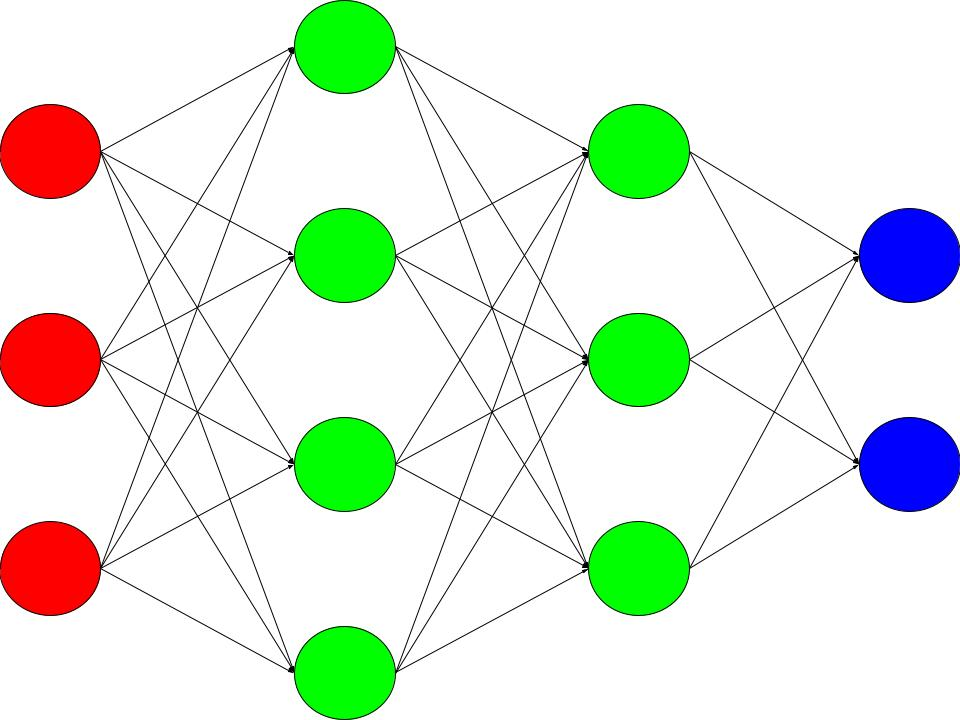

Ahora no es relevante qué representan los círculos rojos, verdes y azules. Lo relevante es que en conjunto representan un grafo en el que hay unas unidades de cómputo que llamamos neuronas y las salidas de unas unidades de cómputo se convierten en las entradas de otras.

Una neurona artificial es una función matemática que se inspira en el funcionamiento de las neuronas naturales. Es un modelo bioinspirado, pero el objetivo no es modelar el funcionamiento biológico. Las neuronas artificiales no están limitadas por modelar las neuronas anturales, sino que toman ideas de su funcionamiento. De ahora en adelante nos referiremos siempre a neuronas artificiales, así que por simplicidad omitiremos el *artificiales* y simplemente hablaremos de neuronas.

Como hemos dicho, una neurona es una función matemática. Hay diversos tipos de estas funciones en la bibliografía (lineales, convolucionales, LSTM, etc) con utilidades distintas. Nosotros por ahora nos vamos a centrar en la neurona clásica. También denominada neurona lineal o densa, que se define como:

$y= a(\sum w_{i}x_{i}-b)$

Siendo **w** un vector de pesos, **x** un vector de entradas, *b* un valor umbral (también llamado desviación o *bias*) y *a* una función de activación. Los parámetros que se ajustan son **w** y **b**.

Antes de entrar en la arquitectura, vamos a pensar detenidamente en la fórmula de la neurona clásica. Por ahora supongamos que $a$ es la función identidad $f(x)=x$ (la ignoramos). Nos queda la función $y=\sum w_{i}x_{i}-b$. Supongamos además que los vectores **w** y **x** tienen una única componente. Podemos reducirlo a $y=wx-b$. ¡Un momento! ¡Esa es la ecuación de la recta en 2D! Si la extendemos un poco tenemos $y=w_{i}x_{i}+w_{j}x_{j}-b$ que representa un plano y así podemos seguir extendiendo dimensiones. Si *a* es la función identidad, nuestra neurona no es más que una función lineal y una función lineal se caracteriza por tener siempre la misma inclinación. Vamos a verlo en 2D.

Para empezar, vamos a crear algunas funciones que permitan usar polinomios y generar datos a partir de un polinomio.

In [2]:
def generate_polynomial(c_list):
  """
  Función para generar una función que aplique un polinomio.
  Args:
    c_list: Lista de coeficientes del polinomio. ej: [2,1,0] representa el polinomio y = 2x**2 + x + 0
  """
  def apply_polynomial(x):
    """
    Función para aplicar un polinomio.
    Args:
      x: las entradas a las que aplicarle el polinomio.
    """
    y = torch.cat([c*x[None,:]**index for index, c in enumerate(reversed(c_list))]).sum(dim=0)  # Para cada coeficiente (desde el final) operamos todas
                                                                                                # las x elevándolo a su índice (0,1,2,etc) y obtenemos
                                                                                                # una fila.
                                                                                                # El cat concatena las filas, así cada columna tiene,
                                                                                                # para un solo x, las operaciones de cada término del
                                                                                                # polinomio.
                                                                                                # Finalmente sumamos a lo largo de las columnas.
    return y

  return apply_polynomial

def get_data_from_a_polynomial(poly, n, sigma=2, range=50):
  """
  Función que devuelve datos a partir de una recta. Recordemos que la ecuación de la recta está definida por y=mx+b.
  Args:
    poly: Función que aplica un polinomio.
    n: número de datos que queremos obtener.
    sigma: desviación típica para el ruido que añadiremos a los datos (2 por defecto).
    range: extremo del rango [0,rango] en el eje x en el que queremos situar los datos (50 por defecto).
  """
  x = range*torch.rand(n)                                                             # Generamos los datos en el eje x.
  y = poly(x)                                                                         # Obtenemos los valores del polinomio para cada x.
  noise_x = torch.normal(torch.zeros_like(y), sigma*torch.ones_like(y))               # Generamos un vector de ruido gaussiano para el eje x.
  noise_y = torch.normal(torch.zeros_like(y), sigma*torch.ones_like(y))               # Generamos un vector de ruido gaussiano para el eje y.
  x_with_noise = x + noise_x
  y_with_noise = y + noise_y

  data = torch.cat((x_with_noise[:,None], y_with_noise[:,None]), dim=1)
  return data

def draw_2D_function(function, range=[-4,4], function_label = None, title = None, data=None):
  plt.figure(figsize=(8,6))
  if data is not None:
    plt.scatter(data[:,0], data[:,1])
    x = torch.linspace(data[:,0].min(), data[:,0].max(), 100)
  else:
    x = torch.linspace(range[0], range[1], 100)
  y = function(x)
  plt.plot(x, y, label=function_label)

  if title is not None:
    plt.title(title)
  if function_label is not None:
    plt.legend()
  plt.grid(True)
  plt.show()


Nota: Sí. La función generate_polynomial genera otras funciones. Con esas funciones puedo generar polinomios de los que generar datos con un poco de ruido como hacíamos con las rectas. Por ejemplo, del polinomio $y=x^2$:

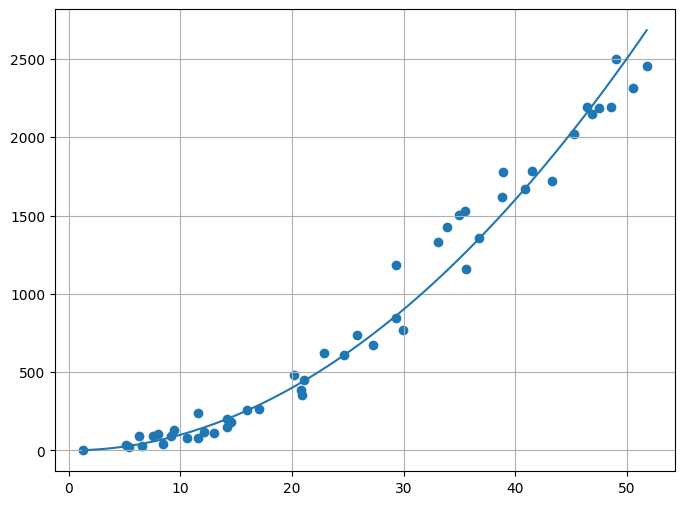

In [28]:
polynomial_cofficients = [1,0,0]
polynomial = generate_polynomial(polynomial_cofficients)
data = get_data_from_a_polynomial(polynomial, 50)
draw_2D_function(polynomial, data=data)

¿Cómo puedo representar esa curva con un modelo lineal de la forma $y=mx+b$? ¡La inclinación de ese modelo va a ser siempre $m$! Su derivada respecto a $x$ es constante, lo que quiere decir que la función no se *dobla* en ningún lugar. No puede tener curvas. Lo mismo pasa con todo modelo lineal con más variables. La inclinación es siempre la misma. Además, combinar muchos modelos lineales da como resultado otro modelo lineal.

Vamos a verlo en una prueba sencilla:

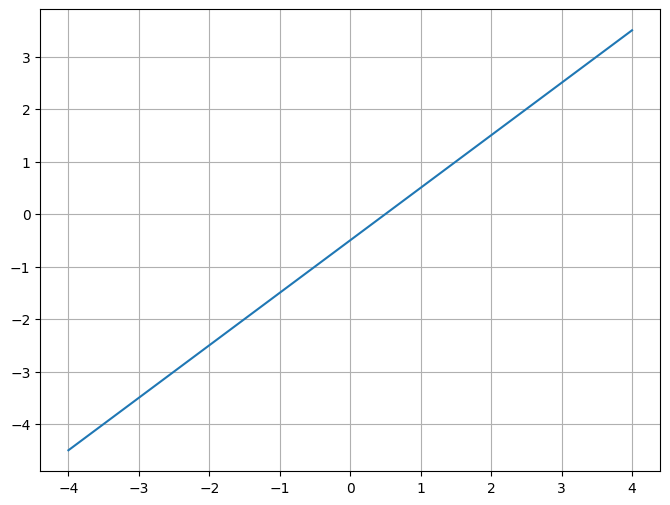

In [29]:
def wrapper_function(inputs):
  return line_model(4,1, inputs) + line_model(-3,-1.5, inputs)
draw_2D_function(wrapper_function)

Nota: un wrapper en programación es una función intermedia que sirve para hacer compatibles distintas funciones. Una función intermediaria, por así decirlo.

Si cambiamos los valores de m y b de los modelos lineales anteriores el resultado siempre es otro modelo lineal. Al fin y al cabo:

$y=(m_{1}x+b_{1})+(m_{2}x+b_{2}) = (m_{1}+m_{2})x+(b_{1}+b_{2})$

Si intentamos combinarlos secuencialmente (que la salida de uno sea la entrada de otro que es lo mismo que hacer la composición de ambos).



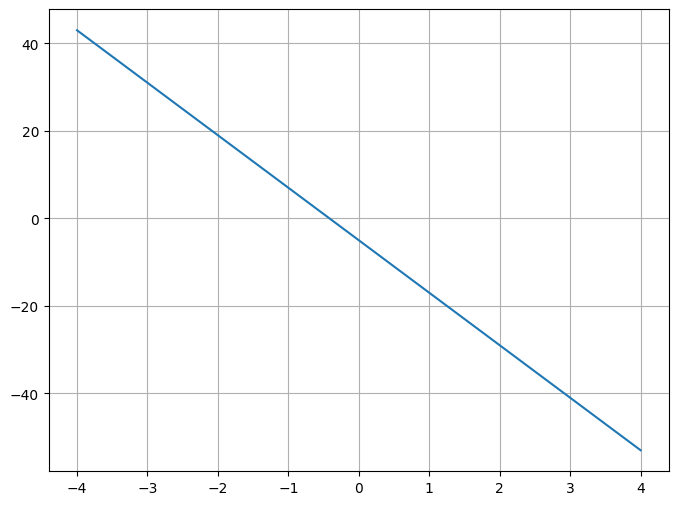

In [30]:
def wrapper_function(inputs):
  return line_model(4,1, line_model(-3,-1.5, inputs))
draw_2D_function(wrapper_function)

¡Vuelve a ser otra línea recta!

$y = (m_{1}(m_{2}x+b_{2})+b_{1}) = m_{1}m_{2}x+m_{1}b_{2}+b_{1}$

Si sumar modelos lineales y componerlos tiene como resultado otros modelos lineales, ¿Dónde está el truco de las redes? Por mucho que cree un grafo con muchas neuronas clásicas, el resultado siempre iba a ser una recta. ¿Qué les otorga flexibilidad? El truco  está en el elemento que hemos dejado *inutilizado*, la función de activación.

La función $y=x^2$ tiene esta forma:



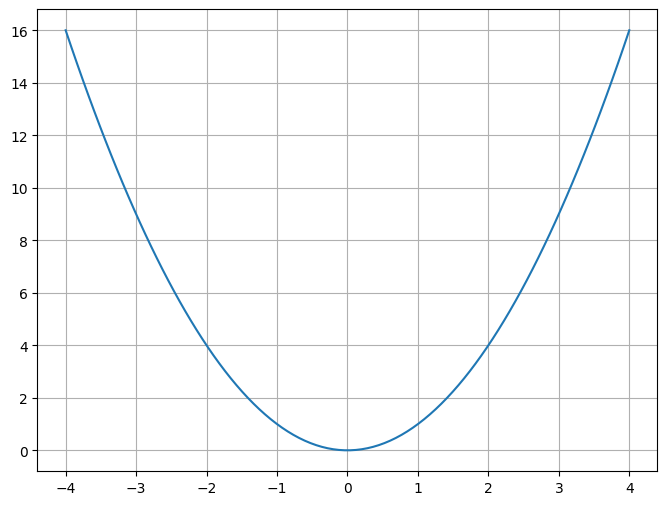

In [31]:
polynomial_cofficients = [1,0,0]
polynomial = generate_polynomial(polynomial_cofficients)
draw_2D_function(polynomial)

Si combinamos un par de modelos lineales a los que añadimos unas funciones de activación (de las que ahora hablaremos), obtenemos algo así:


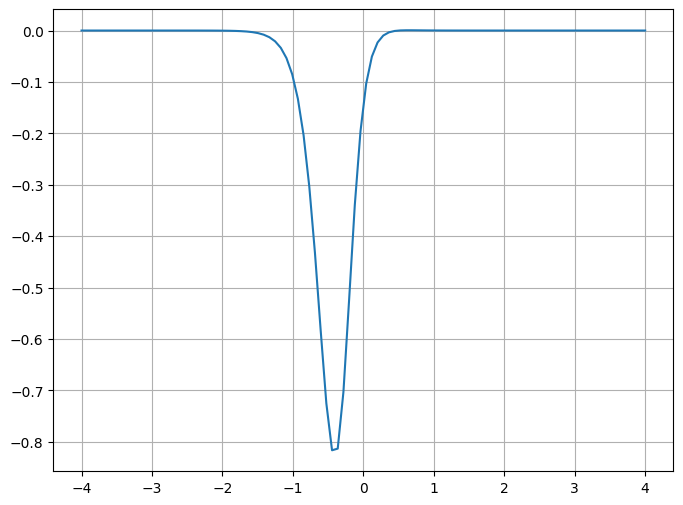

In [32]:
def wrapper_function(inputs):
  return torch.tanh(line_model(4,1, inputs)) + torch.tanh(line_model(-3, -1.5, inputs))
draw_2D_function(wrapper_function)

Vale. No son la misma función. Ni siquiera tienen la misma forma, pero se parecen más. Y lo más importante, ¡No es una línea recta! La función de activación permite representar algo más que líneas rectas. Concretamente la función que hemos utilizado es la tangente hiperbólica (abreviado típicamente a tanh) Y es una función de activación habitual que tiene la forma:


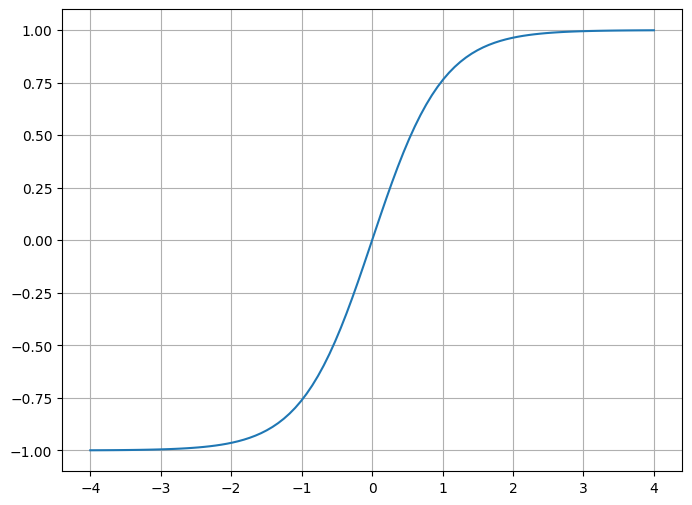

In [33]:
draw_2D_function(torch.tanh)

Su fórmula es:

tanh(x) = (e<sup>x</sup>-e<sup>-x</sup>)/(e<sup>x</sup>+e<sup>-x</sup>)

Y como características destacadas diremos que es derivable en todo su dominio y su resultado está en (-1,1).

vamos a ver otras funciones de activación relevantes.

La función logistica (típicamente llamada sigmoide, aunque técnicamente es un caso particular de función sigmoide):


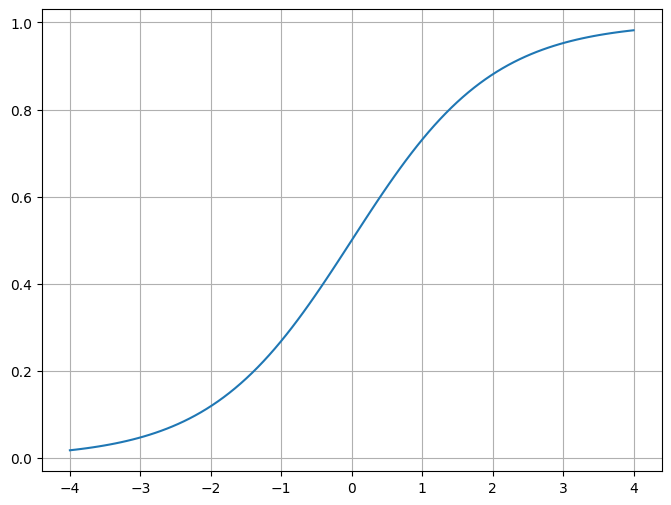

In [34]:
draw_2D_function(torch.sigmoid)

sigmoid(x) = 1/(1+e<sup>-x</sup>)

También derivable y con resultados en (0,1).

La función Linear Rectificada (abreviada ReLU por Rectified Linear Unit):

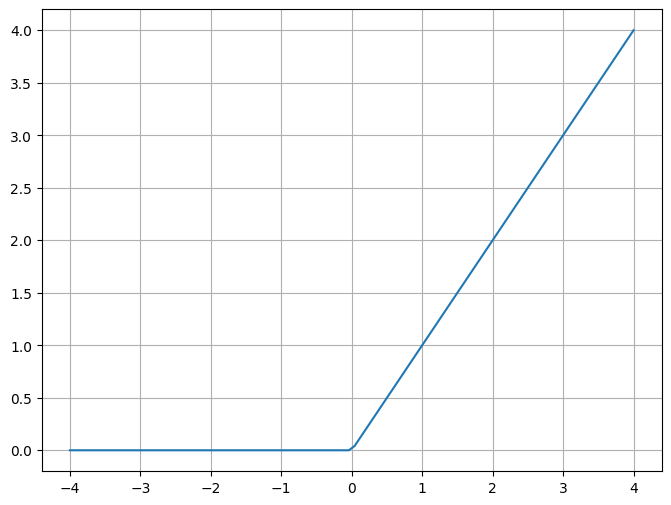

In [35]:
draw_2D_function(torch.relu)

ReLU(x) = max(0,x)

Esta no es derivable en todo su dominio ya que su derivada no está definida en el 0, pero ya hemos visto que eso no siempre es un problema (en ese casos se suele elegir arbitrariamente que la derivada sea 0 o 1). Su resultado esta en [0,+∞).

La LeakyReLU:

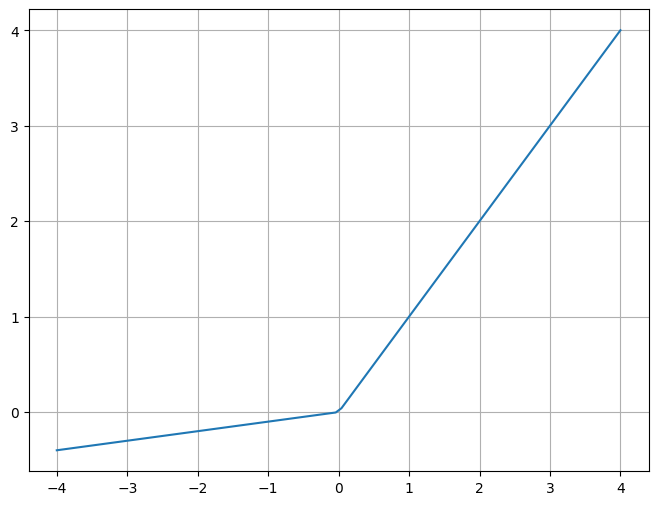

In [36]:
leaky_relu = torch.nn.LeakyReLU(negative_slope=0.1)
draw_2D_function(leaky_relu)

LeakyReLU(x) = max(0,x) + negative_slope*min(0,x)

En este caso la función vuelve a no ser derivable en todo el dominio, pero con la ReLU se puede elegir un valor arbitrario (1 o la inclinación negativa) para la derivada en el 0. Su resultado está en (-∞,+∞).

Nota histórica: Cuando la función de activación es la función paso (f(x)= 1 si x>=1 y 0 si x<0), a esta neurona se la llama neurona de McCulloch-Pitts (los que la propusieron en 1943) y de ese paso de *activación* cuando el sumatorio supera el umbral viene la terminología de activación y umbral.

Hay muchas otras funciones de activación (alguna más veremos en el futuro), pero estas son las más importantes para cualquier problema de regresión en Aprendizaje Profundo.

¿Qué tienen en común?

*   No son funciones lineales. ¡Ya hemos visto que componer funciones lineales tiene como resultado otra función lineal! Justamente queremos que las funciones de activación rompan esa linealidad para permitir a las redes neuronales ajustarse a funciones no lineales.
*   Son derivables o los puntos en los que no son derivables los podemos evitar asignando valores razonables sin provocar problemas numéricos. Recordemos que nuestra estrategia de entrenamiento se basa en el gradiente y para eso tenemos que poder obtener derivadas parciales.
*   Tienen al menos un rango *sensible*. Rangos en los que cambios no triviales en la entrada provocan cambios no triviales en la salida.

¿Qué se puede observar en algunas de ellas?

Varias tienen rangos no *sensibles*. Son asintotas en las que cambios en la entrada provocan poco o ningún cambio en la salida. ¡En esas asíntotas la derivada es 0! Si aplicamos la regla de la cadena con una función de activación en su rango insensible, el gradiente se convierte en 0. ¡No podemos ajustar nada! A este problema se le llama el Problema de Desvanecimiento de Gradiente (*Vanishing Gradient Problem*) y es un problema relativamente frecuente a la hora de entrenar modelos. Por eso hay que tener cuidado con el rango de valores en el que se inicializan los modelos y en el que están los datos. Si una neurona se inicializa con parámetros en valores que operados por los datos saquen a la función de su rango sensible, esa neurona no va a poder aprender.

Para terminar este cuaderno vamos a actualizar nuestro ejemplo algoritmo de aprendizaje usando la neurona lineal de PyTorch yvamos a optimizar ambos parámetros.

Linear(in_features=1, out_features=1, bias=True)
--------- step 0
m,b actual: (Parameter containing:
tensor([[0.2846]], requires_grad=True), Parameter containing:
tensor([-0.2452], requires_grad=True))
Valor medio de y: 9.680885314941406
Valor medio de y predicho: 5.584117889404297
Gradiente: [tensor([[-18.3109]]), tensor([-0.8000])]
--------- step 1
m,b actual: (Parameter containing:
tensor([[0.3029]], requires_grad=True), Parameter containing:
tensor([-0.2444], requires_grad=True))
Valor medio de y: 9.680885314941406
Valor medio de y predicho: 5.959984302520752
Gradiente: [tensor([[-17.1880]]), tensor([-0.7200])]
--------- step 2
m,b actual: (Parameter containing:
tensor([[0.3201]], requires_grad=True), Parameter containing:
tensor([-0.2437], requires_grad=True))
Valor medio de y: 9.680885314941406
Valor medio de y predicho: 6.312768459320068
Gradiente: [tensor([[-17.1880]]), tensor([-0.7200])]
--------- step 3
m,b actual: (Parameter containing:
tensor([[0.3373]], requires_grad=True)

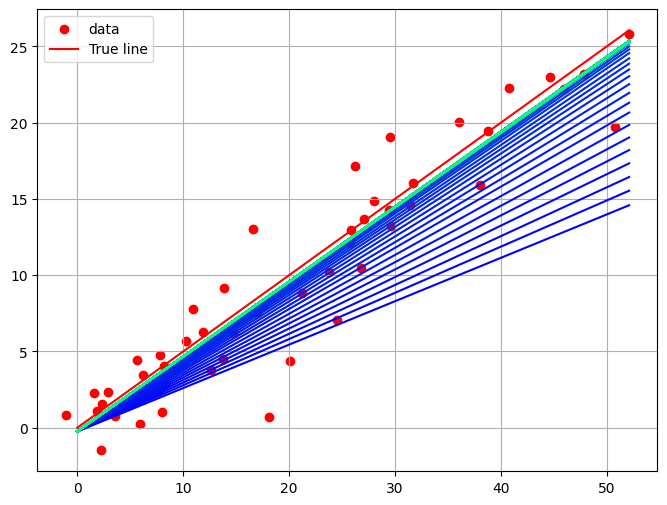

In [42]:
true_m, true_b = [0.5,0]
data = get_data_from_a_line(true_m, true_b, 50)

learning_rate = 1e-3
steps = 80
loss_fn = torch.nn.L1Loss()

model = torch.nn.Linear(1,1)

m = model.weight
b = model.bias
line_evolution_m = [m[0].clone().detach()]               # A las listas no añadimos el parámetro, sino una copia que nos aseguramos
line_evolution_b = [b.clone().detach()]               # de sacar del grafo usando un detach()

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=learning_rate
)

x_true = data[:,0][:,None]
y_true = data[:,1][:,None]

for step in range(steps):
  y_pred = model(x_true)                              # Forward
  optimizer.zero_grad()
  loss = loss_fn(y_pred, y_true)
  loss.backward()                                     # Backward
  m = model.weight
  b = model.bias
  grad = [m.grad, b.grad]
  print(f"--------- step {step}")
  print(f"m,b actual: {m,b}")
  print(f"Valor medio de y: {y_true.mean()}")
  print(f"Valor medio de y predicho: {y_pred.mean()}")
  print(f"Gradiente: {grad}")
  optimizer.step()

  line_evolution_m.append(m[0].clone().detach())
  line_evolution_b.append(b.clone().detach())

plt.figure(figsize=(8,6))
colors = plt.cm.winter(torch.linspace(0,1,steps+1))
for index, (m, b) in enumerate(zip(line_evolution_m, line_evolution_b)):
  plt.plot([0,x_true.max()], [m*0+b,m*x_true.max()+b], c=colors[index])
plt.scatter(x_true, data[:,1], marker='o', c='r', label="data")
plt.plot([0,x_true.max()], [true_m*0+true_b,true_m*x_true.max()+true_b], c='r', label="True line")
plt.legend()
plt.grid(True)
plt.show()

En esta versión de nuesto algoritmo de aprendizaje hay varios cambios. Para empezar, nuestro modelo lo inicializamos con un torch.nn.Linear(1,1). Dentro de torch.nn están generalmente las utilidades específicas de Redes Neuronales (Neural Networks). torch.nn.Linear() es la clase que representa una capa de neuronas lineales. Ya hablaremos de capas más adelante. Por ahora basta entender que el primer argumento indica el tamaño de entrada (en nuestro caso 1 ya que solo hay una variable) y el segundo argumento indica el tamaño de salida (que coincide con el número de neuronas en la capa) y en nuestro caso es 1 porque queremos representar una única función lineal. Nótese que no le indicamos la función de activación. Por defecto asume que no hay. Nuestra m y nuestra b la tenemos que extraer ahora de la neurona (su único peso y su bias).

Lo segundo llamativo es que ya no tenemos explícitamente nuestra regla de aprendizaje. Lo hemos sustituido por añadir el optimizador SGD (Stochastic Gradient Descent). Un optimizador es una clase que gestiona el aprendizaje de la red. Se le indican los parámetros de cuyo aprendizaje tiene que ocuparse y el ratio de aprendizaje y cuando llega el momento de actualizar esos parámetros se le indica que ejecute un paso de aprendizaje (.step). Esto enmascara y simplifica el código, además de facilitar hacer cambios rápidos alterando el algoritmo de aprendizaje. No tenemos que preocuparnos por ejecutar la actualización sin afectar el grafo de computación y llamando a zero_grad() los gradientes de todos los parámetros se resetearan a 0. El optimizador se encarga. Ya hablaremos más de optimizadores en el futuro.




Vale. Ya hemos visto cómo usar una neurona lineal en PyTorch y optimizarla para ajustar la recta, pero ¿qué pasa con la función y=x<sup>2</sup>? ¿Permite la neurona lineal con una función de activación adecuada ajustarla?

Depende. Ninguna función de activación de las que hemos comentado permite ajustar una función con esa forma. El rango de salida de la función sigmoide o la tangente hiperbólica no es el mismo que el de y=x<sup>2</sup> así que esperar que sirva para ajustarla no tiene mucho sentido. ¿Y usando una ReLU o LeakyReLU? El rango de salida de la ReLU es el mismo que el de y=x<sup>2</sup>. Ambas van de 0 a infinito. No cuesta nada probar...

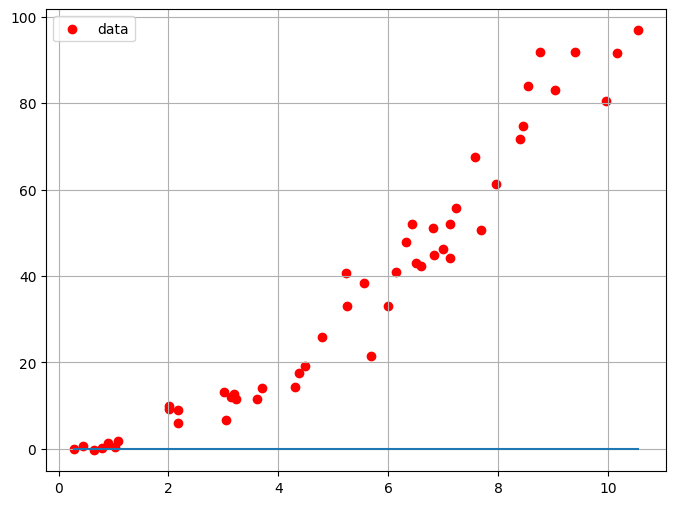

In [3]:
polynomial_cofficients = [1,0,0]
polynomial = generate_polynomial(polynomial_cofficients)
data = get_data_from_a_polynomial(polynomial, 50, sigma=0.5, range=10)

learning_rate = 1e-3
steps = 8000
loss_fn = torch.nn.L1Loss()

model = torch.nn.Sequential(
    torch.nn.Linear(1,1),
    torch.nn.ReLU(),
)

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=learning_rate
)

x_true = data[:,0][:,None]
y_true = data[:,1][:,None]

for step in range(steps):
  y_pred = model(x_true)                              # Forward
  optimizer.zero_grad()
  loss = loss_fn(y_pred, y_true)
  loss.backward()                                     # Backward
  optimizer.step()

plt.figure(figsize=(8,6))
x = torch.linspace(x_true.min(), x_true.max(), 100)[:,None]
y = model(x).detach()
plt.plot(x, y)
plt.scatter(data[:,0], data[:,1], marker='o', c='r', label="data")
plt.legend()
plt.grid(True)
plt.show()

Pues parece que la ReLU no nos soluciona el problema. De hecho.. ¡Ha aprendido una recta! ¿Y la LeakyReLU?

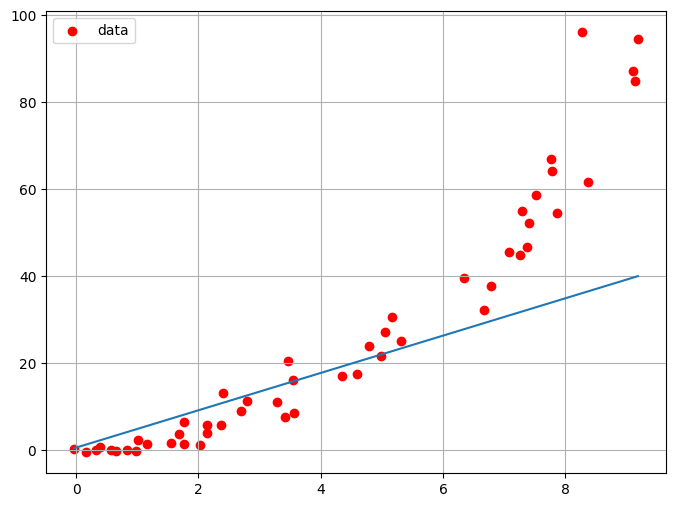

In [48]:
polynomial_cofficients = [1,0,0]
polynomial = generate_polynomial(polynomial_cofficients)
data = get_data_from_a_polynomial(polynomial, 50, sigma=0.5, range=10)

learning_rate = 1e-3
steps = 8000
loss_fn = torch.nn.L1Loss()

model = torch.nn.Sequential(
    torch.nn.Linear(1,1),
    torch.nn.LeakyReLU(),
)

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=learning_rate
)

x_true = data[:,0][:,None]
y_true = data[:,1][:,None]

for step in range(steps):
  y_pred = model(x_true)                              # Forward
  optimizer.zero_grad()
  loss = loss_fn(y_pred, y_true)
  loss.backward()                                     # Backward
  optimizer.step()

plt.figure(figsize=(8,6))
x = torch.linspace(x_true.min(), x_true.max(), 100)[:,None]
y = model(x).detach()
plt.plot(x, y)
plt.scatter(data[:,0], data[:,1], marker='o', c='r', label="data")
plt.legend()
plt.grid(True)
plt.show()

Otra dichosa recta. ¿Pero no habíamos dicho que el truco estaba en la función de activación? Una función de activación no es más que una función matemática, así que podríamos usar como función de activación a(x)=x<sup>2</sup> y así conseguir la forma que tenemos. Sería una opción, pero esa forma de razonar solo tiene sentido si sabemos que los datos se ajustan bien a y=x<sup>2</sup>. ¿Cómo lo sabemos? En este caso porque hemos creado los datos artificialmente a partir de ese polinomio, pero en un caso real no sabemos a qué función se corresponden los datos. Necesitamos un modelo flexible que pueda ajustar funciones desconocidas. La flexibilidad de las redes no está en usar una única neurona, sino en usar muchas combinadas. De eso vamos a hablar en el siguiente cuaderno.

Conclusiones:


*   La neurona clásica es una función lineal que necesita una función de activación no lineal para poder aprender algo que no sean rectas.
*   Hay muchas funciones de activación muy variadas con distintos rangos de salida que condicionarán la misma.
*   Las funciones de activación tienen unos rangos en las que son útiles, pero pueden quedar inutilizadas fuera de esos rangos porque el gradiente en esos puntos se vuelva 0 y no se pueda seguir aprendiendo.
*   PyTorch ya incluye la neurona clásica implementada (entre otras).
*   PyTorch enmascara los pasos del algoritmo de actualización de los pesos para simplificar el código mediante los optimizadores.
*   Una sola neurona no es muy flexible.

---
# Parte 6: Modelos Neuronales II
---

In [1]:
import torch
import matplotlib.pyplot as plt

Modelos Neuronales II
Autor: Jorge García González (Universidad de Málaga)

Última Actualización: 25/09/2025

Asignatura: Programación para la Inteligencia Artificial

Anteriormente hemos hablado de la neurona clásica, el papel de la función de activación en la misma y cómo una única neurona no tiene suficiente flexibilidad para ajustar funciones sencillas como y=x<sup>2</sup>. Vamos a hablar ahora de la combinación de varias neuronas. Vamos a hablar de las redes neuronales.

Antes, de nuevo vamos a rescatar algunas funciones del cuaderno anterior:

In [2]:
def generate_polynomial(c_list):
  """
  Función para generar una función que aplique un polinomio.
  Args:
    c_list: Lista de coeficientes del polinomio. ej: [2,1,0] representa el polinomio y = 2x**2 + x + 0
  """
  def apply_polynomial(x):
    """
    Función para aplicar un polinomio.
    Args:
      x: las entradas a las que aplicarle el polinomio.
    """
    y = torch.cat([c*x[None,:]**index for index, c in enumerate(reversed(c_list))]).sum(dim=0)  # Para cada coeficiente (desde el final) operamos todas
                                                                                                # las x elevándolo a su índice (0,1,2,etc) y obtenemos
                                                                                                # una fila.
                                                                                                # El cat concatena las filas, así cada columna tiene,
                                                                                                # para un solo x, las operaciones de cada término del
                                                                                                # polinomio.
                                                                                                # Finalmente sumamos a lo largo de las columnas.
    return y

  return apply_polynomial

def get_data_from_a_polynomial(poly, n, sigma=2, range=50):
  """
  Función que devuelve datos a partir de una recta. Recordemos que la ecuación de la recta está definida por y=mx+b.
  Args:
    poly: Función que aplica un polinomio.
    n: número de datos que queremos obtener.
    sigma: desviación típica para el ruido que añadiremos a los datos (2 por defecto).
    range: extremo del rango [0,rango] en el eje x en el que queremos situar los datos (50 por defecto).
  """
  x = range*torch.rand(n)                                                             # Generamos los datos en el eje x.
  y = poly(x)                                                                         # Obtenemos los valores del polinomio para cada x.
  noise_x = torch.normal(torch.zeros_like(y), sigma*torch.ones_like(y))               # Generamos un vector de ruido gaussiano para el eje x.
  noise_y = torch.normal(torch.zeros_like(y), sigma*torch.ones_like(y))               # Generamos un vector de ruido gaussiano para el eje y.
  x_with_noise = x + noise_x
  y_with_noise = y + noise_y

  data = torch.cat((x_with_noise[:,None], y_with_noise[:,None]), dim=1)
  return data

def draw_2D_function(function, range=[-4,4], function_label = None, title = None, data=None):
  plt.figure(figsize=(8,6))
  if data is not None:
    plt.scatter(data[:,0], data[:,1])
    x = torch.linspace(data[:,0].min(), data[:,0].max(), 100)
  else:
    x = torch.linspace(range[0], range[1], 100)
  y = function(x)
  plt.plot(x, y, label=function_label)

  if title is not None:
    plt.title(title)
  if function_label is not None:
    plt.legend()
  plt.grid(True)
  plt.show()

Una red neuronal es un grafo de neuronas. En teoría puede ser cualquier grafo de neuronas, pero en la práctica hay diversas estructuras habituales. Tipos de grafos concretos en combinación con ciertas neuronas y reglas de aprendizaje definen el tipo de red neuronal con el que se está trabajando.

Nosotros nos vamos a centrar en redes neuronales prealimentadas (feedforward neural networks). ¿Qué significa eso? Pues que nuestro grafo de neuronas es acíclico. Que no se retroalimenta en ningún momento.

Este tipo de redes es muy común y puede tener aspectos muy diversos. A continuación están los esquemas de la AlexNet (una red de clasificación de objetos), una red autocodificadora (comunmente llamadas por su nombre en ingles *autoencoder*) y la UNet (una red usada tanto en segmentación como en generación de imágenes).

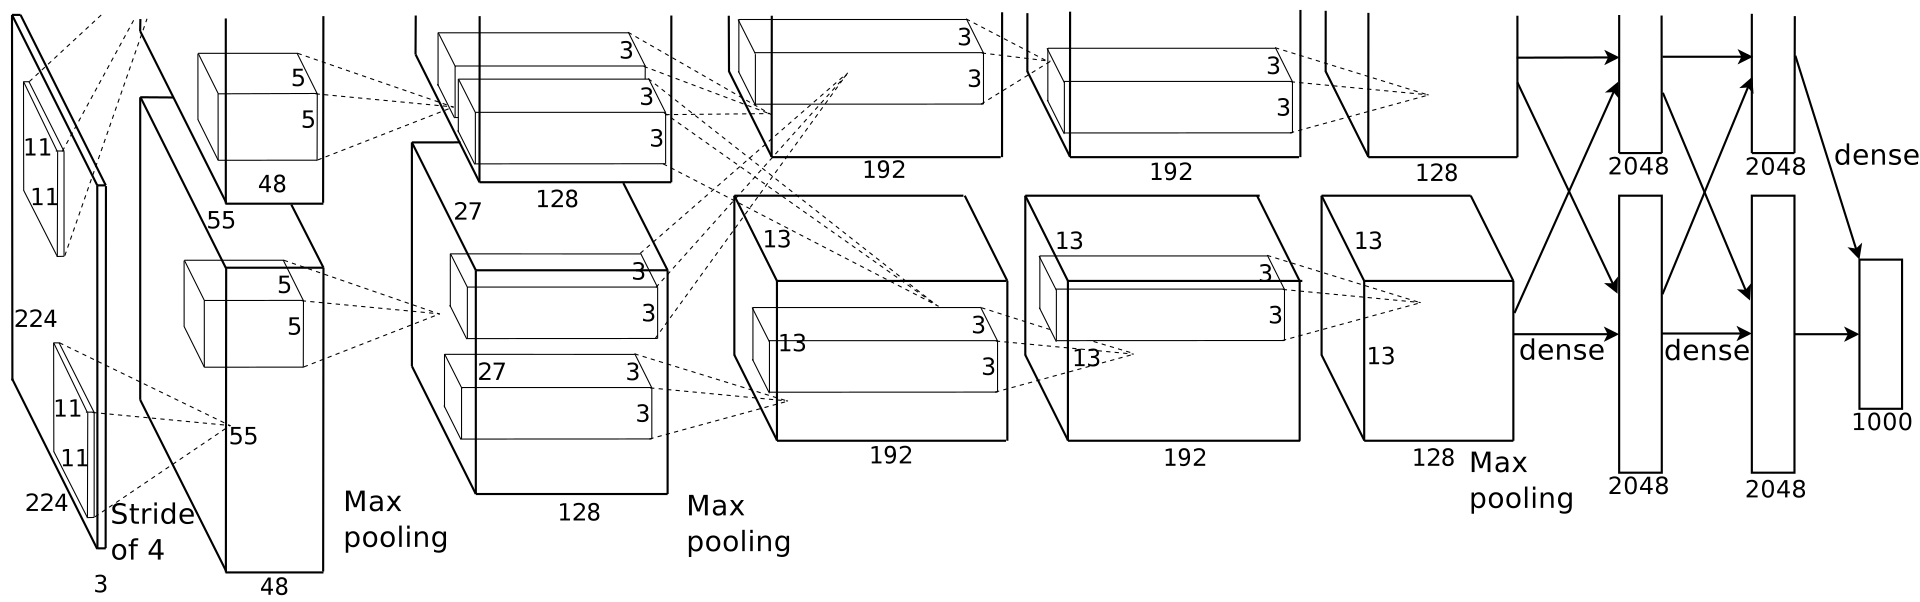

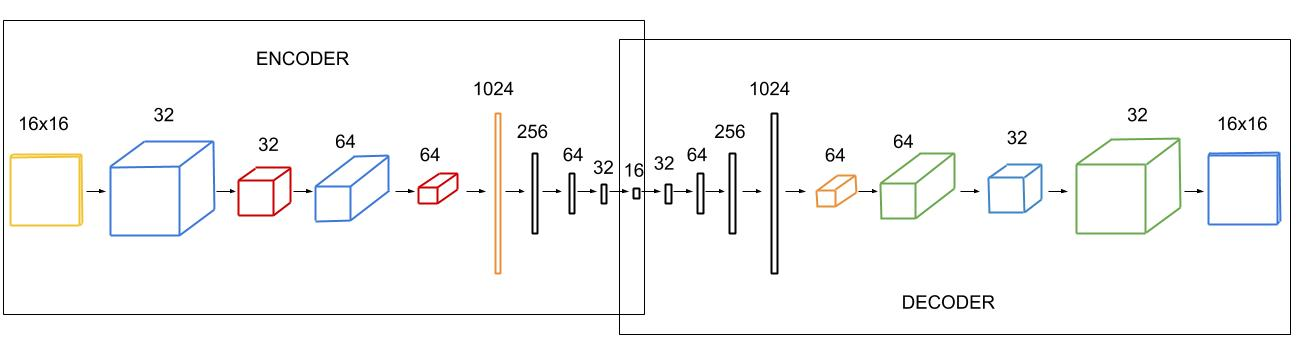

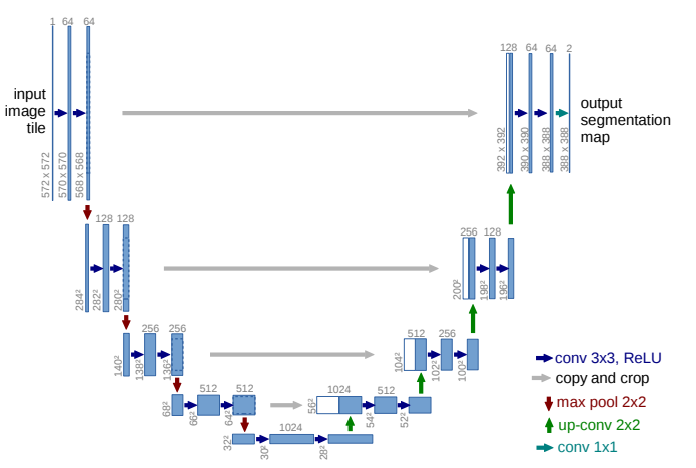

Los tres son casos de redes *Feedforward*, pero lo interesante de estos esquemas es... que ahí no aparecen neuronas. Esos grafos muestran la relación entre *capas* de neuronas. En la práctica en Aprendizaje Profundo el diseño de las redes no se hace pensando en neuronas particulares, sino en capas. En palabras de François Chollet (creador de Keras y uno de los principales investigadores de Google durante 10 años): *The fundamental data structure in neural networks is the layer*. Y él mismo las denomina *the building blocks of deep learning*.

Podríamos afirmar que una capa es una abstracción sobre las neuronas, así que formalmente podríamos decir que son una lista de funciones (porque cada neurona recordemos que es una función).

l = [f<sub>1</sub>, f<sub>2</sub>, ..., f<sub>n</sub>]

Lo importante es que todas esas funciones son neuronas que por convención son del mismo tipo y comparten datos de entrada. De esa manera, podemos hablar de una capa de neuronas lineales, una capa de neuronas convolucionales, etc.

Un ejemplo claro es un Perceptrón Multicapa.


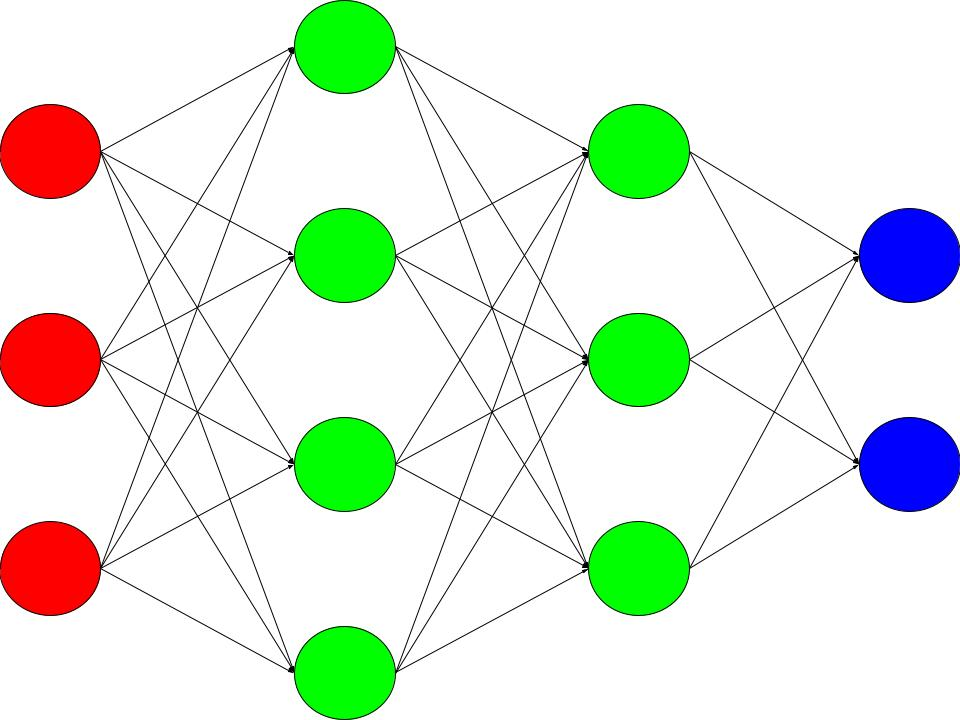

Ese dibujo representa explícitamente las neuronas, pero en la práctica uno lo interpretaría como: 3 datos de entrada (círculos rojos a veces denóminados engañosamente capa de entrada), una capa de 4 neuronas densas, otra capa de 3 neuronas densas (los círculos verdes) y una capa final con 2 neuronas densas que sirven como salida. Por convención en los Perceptrones Multicapa se diferencia entre la capa de entrada, las capas ocultas y la capa de salida. Esto, como digo, es mera convención porque en el perceptrón todas las neuronas (círculos verdes y azules) son neuronas clásicas (o lineales o densas, como las queramos llamar). Si se suele hablar de capas densas es porque al añadir una capa de neuronas de ese tipo se asume que todas las neuronas de la capa están conectadas con todas las salidas de la capa anterior. Antes me he referido como engañoso al hablar de la capa de entrada porque realmente no representan funciones, sino los datos de entrada. Aún así, la convención llama a los datos de entrada capa de entrada y en algunos Frameworks como Tensorflow hay que indicar explícitamente una capa de entrada de datos al montar la red.

¿Por qué hablamos de capas en realidad? ¡Porque en cada una ponemos muchísimas neuronas como para hacer grafos mostrándolas! En los esquemas anteriores podemos ver representadas las capas densas al final de la Alexnet y en el centro del autoencoder como rectángulos verticales (reflejando esa idea intuitiva de que son una fila de neuronas colocadas verticalmente heredada de los MLPs clásicos) junto a la cifra que indica cuántas neuronas tiene esa capa. Con esa facilidad indicamos que se han añadido miles de neuronas...

Según convenga uno hace la distinción a nivel de neurona, a nivel de capa, a nivel de bloque de capas (eso es raro) o a nivel de todo el modelo.

Ahora que tenemos la noción de capa vamos a volver a PyTorch y a ver cómo se puede montar una red neuronal.

Antes, por pura comodidad vamos a crear una función que sea nuestro bucle de entrenamiento.

In [17]:
def learning_loop(x_true, y_true, model, steps, loss_fn, learning_rate, optimizer):
  loss_list = []

  opt = optimizer(
    model.parameters(),
    lr=learning_rate
  )

  for step in range(steps):
    y_pred = model(x_true)                              # Forward
    opt.zero_grad()
    loss = loss_fn(y_pred, y_true)
    loss.backward()                                     # Backward
    #print(f"--------- step {step}")
    #print(f"Parametros actuales actual: {[param for param in model.parameters()]}")
    #print(f"Valor medio de y: {y_true.mean()}")
    #print(f"Valor medio de y predicho: {y_pred.mean()}")
    #print(f"Error: {loss}")
    loss_list.append(loss.clone().detach())
    #print(f"Gradiente: {[param.grad for param in model.parameters()]}")
    opt.step()

  return model, loss_list

Como se puede ver, hemos omitido o comentado la referencia a los parámetros concretos. De ahora en adelante vamos a asumir que son demasiados como para atender a ningún parámetro en particular. Sí que llevamos el registro del valor de error. ¿Por qué? Para tener una noción de cómo avanza el entrenamiento.

Ahora vamos a intentar ajustar un modelo neuronal con dos capas a la dichosa función y=x<sup>2</sup>. Vamos a empezar probando con dos capas de una única neurona cada una. La primera capa tendrá de activación la tangente hiperbólica, mientras que a la segunda no le vamos a poner ninguna activación.

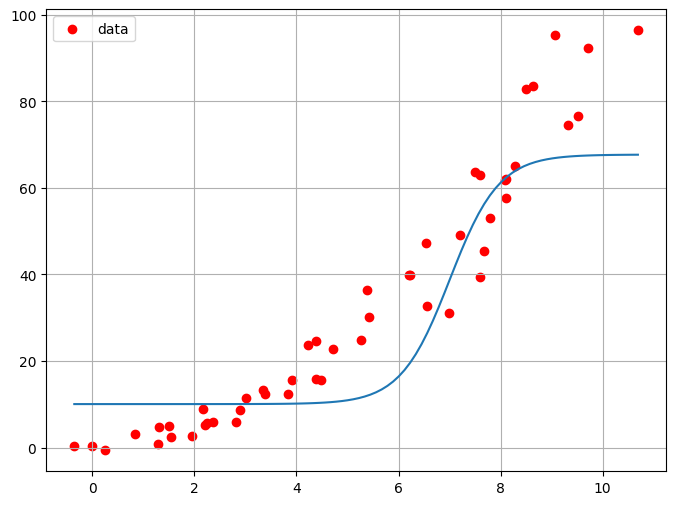

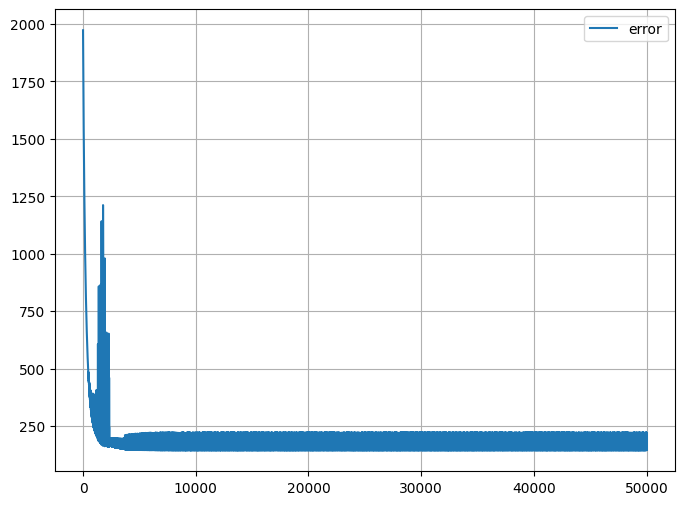

In [19]:
polynomial_cofficients = [1,0,0]
polynomial = generate_polynomial(polynomial_cofficients)
data = get_data_from_a_polynomial(polynomial, 50, sigma=0.5, range=10)

learning_rate = 1e-3
steps = 50000
loss_fn = torch.nn.MSELoss()

model = torch.nn.Sequential(
    torch.nn.Linear(1,1),
    torch.nn.Tanh(),
    torch.nn.Linear(1,1),
)

optimizer = torch.optim.SGD

x_true = data[:,0][:,None]
y_true = data[:,1][:,None]

model, loss_list = learning_loop(x_true, y_true, model, steps, loss_fn, learning_rate, optimizer)

plt.figure(figsize=(8,6))
x = torch.linspace(x_true.min(), x_true.max(), 100)[:,None]
y = model(x).detach()
plt.plot(x, y)
plt.scatter(data[:,0], data[:,1], marker='o', c='r', label="data")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8,6))
plt.plot(range(steps), loss_list, label="error")
plt.legend()
plt.grid(True)
plt.show()

Eso básicamente es la forma de la tangente hiperbólica trasladada y reescalada por la segunda capa para intentar minimizar el error, pero no es suficiente. Veamos con dos neuronas en la primera capa.

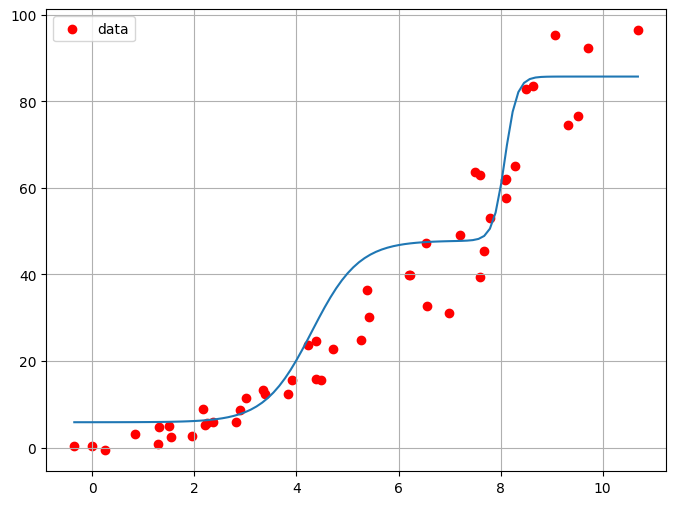

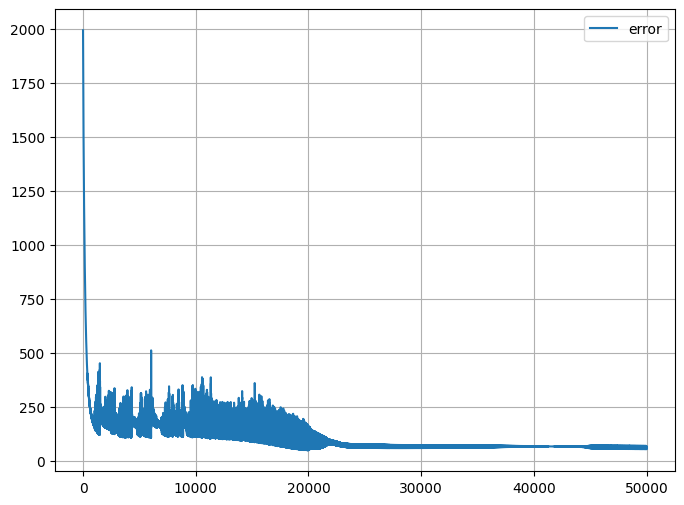

In [20]:
model = torch.nn.Sequential(
    torch.nn.Linear(1,2),
    torch.nn.Tanh(),
    torch.nn.Linear(2,1),
)

model, loss_list = learning_loop(x_true, y_true, model, steps, loss_fn, learning_rate, optimizer)

plt.figure(figsize=(8,6))
x = torch.linspace(x_true.min(), x_true.max(), 100)[:,None]
y = model(x).detach()
plt.plot(x, y)
plt.scatter(data[:,0], data[:,1], marker='o', c='r', label="data")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8,6))
plt.plot(range(steps), loss_list, label="error")
plt.legend()
plt.grid(True)
plt.show()

Mejor, pero parece que aún el modelo no tiene potencia suficiente para adquirir la forma que queremos. 3 neuronas en la primera capa:

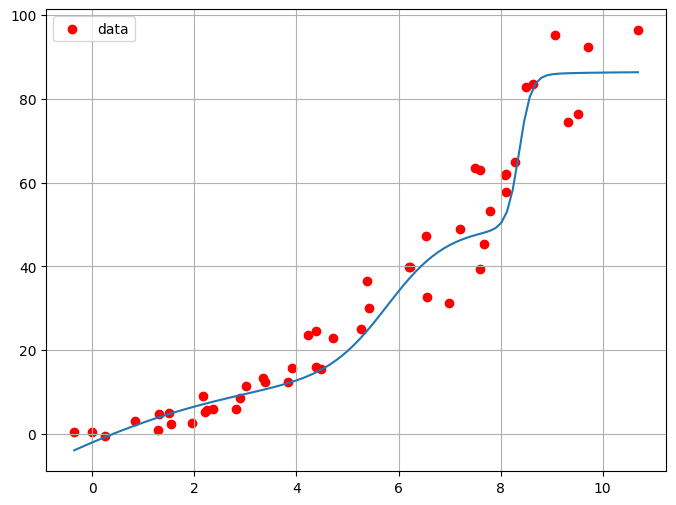

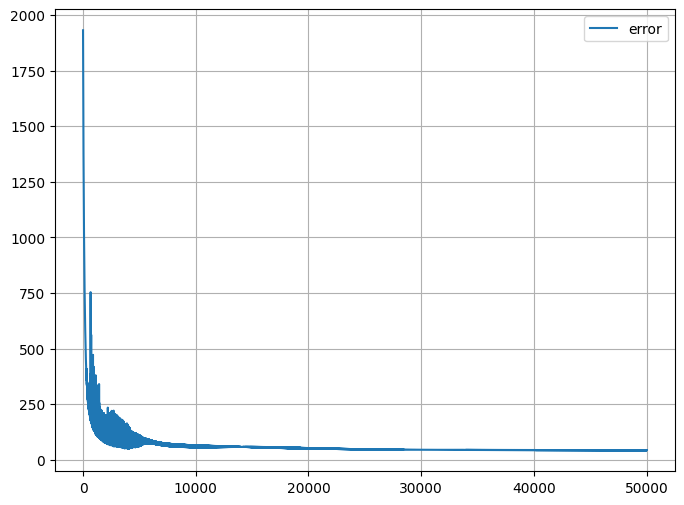

In [21]:
model = torch.nn.Sequential(
    torch.nn.Linear(1,3),
    torch.nn.Tanh(),
    torch.nn.Linear(3,1),
)

model, loss_list = learning_loop(x_true, y_true, model, steps, loss_fn, learning_rate, optimizer)

plt.figure(figsize=(8,6))
x = torch.linspace(x_true.min(), x_true.max(), 100)[:,None]
y = model(x).detach()
plt.plot(x, y)
plt.scatter(data[:,0], data[:,1], marker='o', c='r', label="data")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8,6))
plt.plot(range(steps), loss_list, label="error")
plt.legend()
plt.grid(True)
plt.show()

¿Y con 5?

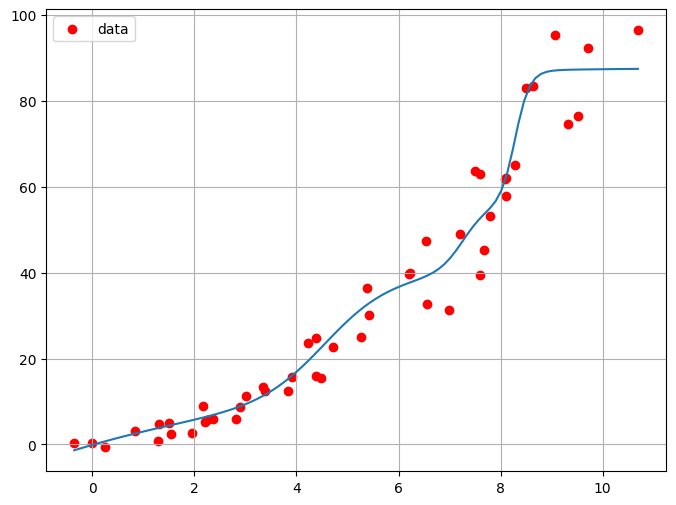

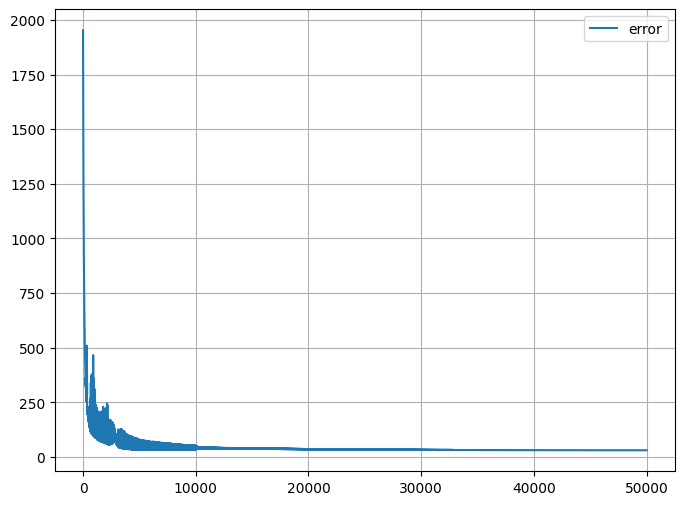

In [22]:
model = torch.nn.Sequential(
    torch.nn.Linear(1,5),
    torch.nn.Tanh(),
    torch.nn.Linear(5,1),
)

model, loss_list = learning_loop(x_true, y_true, model, steps, loss_fn, learning_rate, optimizer)

plt.figure(figsize=(8,6))
x = torch.linspace(x_true.min(), x_true.max(), 100)[:,None]
y = model(x).detach()
plt.plot(x, y)
plt.scatter(data[:,0], data[:,1], marker='o', c='r', label="data")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8,6))
plt.plot(range(steps), loss_list, label="error")
plt.legend()
plt.grid(True)
plt.show()

Parece que vamos mejorando...

Como se puede ver, para definir el modelo estamos usando la clase torch.nn.Sequential(). No es la única manera de definir un modelo neuronal que permite PYTorch, pero es una rápida y flexible. Como rgumento se le indica la lista de capas (y funciones de activación) que queremos y ya tenemos un modelo listo para ser entrenado.

Las capas, en este caso Lineales, se deben interpretar de la siguiente manera: torch.nn.Lineal(1,5) indica que es una capa de neuronas lineales que tiene una entrada y 5 salidas. Cada salida va a ser una neurona, así que es una capa con cinco neuronas ya que obtendremos una salida distinta por neurona. Las capas de otros tipos de neuronas se definen de maneras distintas según el tipo de neurona.

Vamos a venirnos arriba. Añadamos otra capa más de 5 neuronas también con activación tangente hiperbólica.

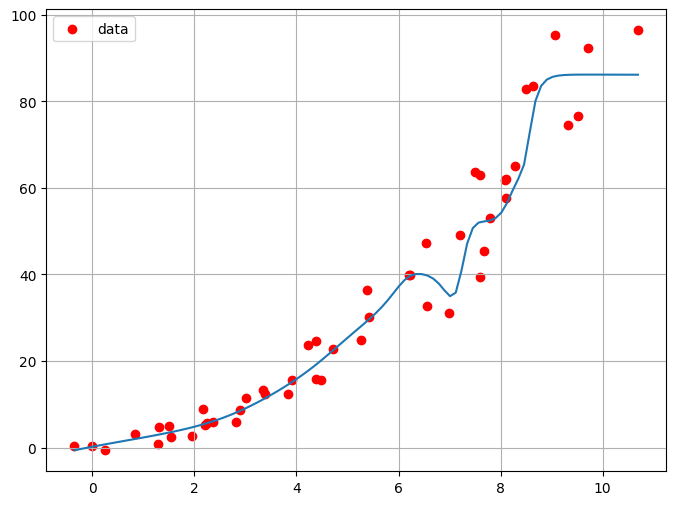

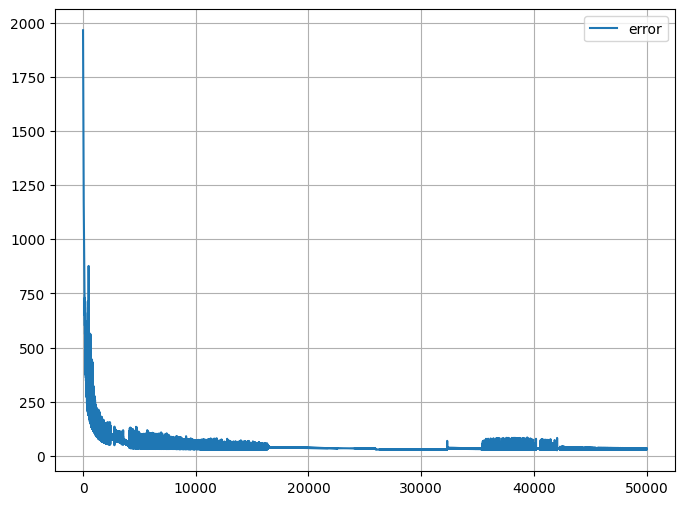

In [27]:
model = torch.nn.Sequential(
    torch.nn.Linear(1,5),
    torch.nn.Tanh(),
    torch.nn.Linear(5,5),
    torch.nn.Tanh(),
    torch.nn.Linear(5,1),
)

model, loss_list = learning_loop(x_true, y_true, model, steps, loss_fn, learning_rate, optimizer)

plt.figure(figsize=(8,6))
x = torch.linspace(x_true.min(), x_true.max(), 100)[:,None]
y = model(x).detach()
plt.plot(x, y)
plt.scatter(data[:,0], data[:,1], marker='o', c='r', label="data")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8,6))
plt.plot(range(steps), loss_list, label="error")
plt.legend()
plt.grid(True)
plt.show()

Venga, otra capa más.

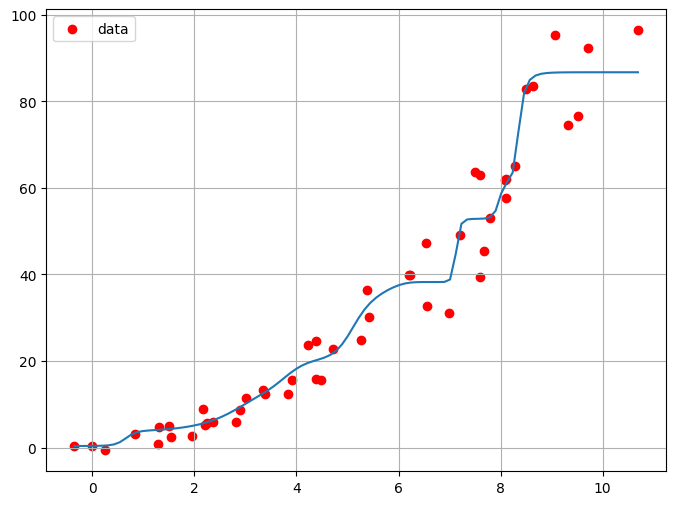

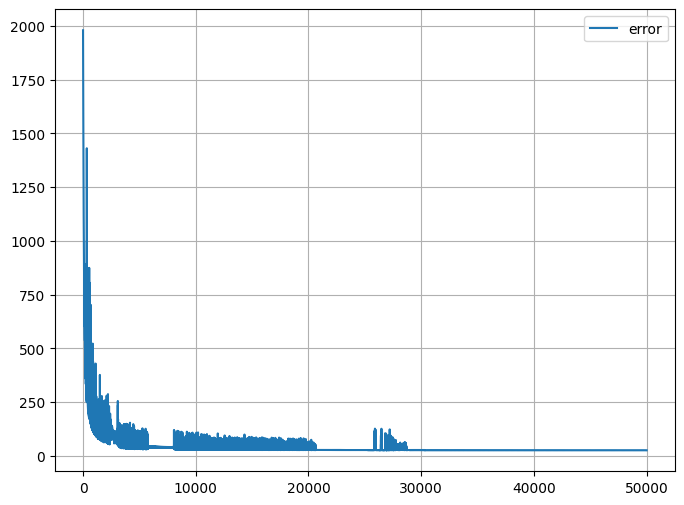

In [28]:
model = torch.nn.Sequential(
    torch.nn.Linear(1,5),
    torch.nn.Tanh(),
    torch.nn.Linear(5,5),
    torch.nn.Tanh(),
    torch.nn.Linear(5,5),
    torch.nn.Tanh(),
    torch.nn.Linear(5,1),
)

model, loss_list = learning_loop(x_true, y_true, model, steps, loss_fn, learning_rate, optimizer)

plt.figure(figsize=(8,6))
x = torch.linspace(x_true.min(), x_true.max(), 100)[:,None]
y = model(x).detach()
plt.plot(x, y)
plt.scatter(data[:,0], data[:,1], marker='o', c='r', label="data")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8,6))
plt.plot(range(steps), loss_list, label="error")
plt.legend()
plt.grid(True)
plt.show()

Vamos a probar cambiando las funciones de activación por las ReLU.

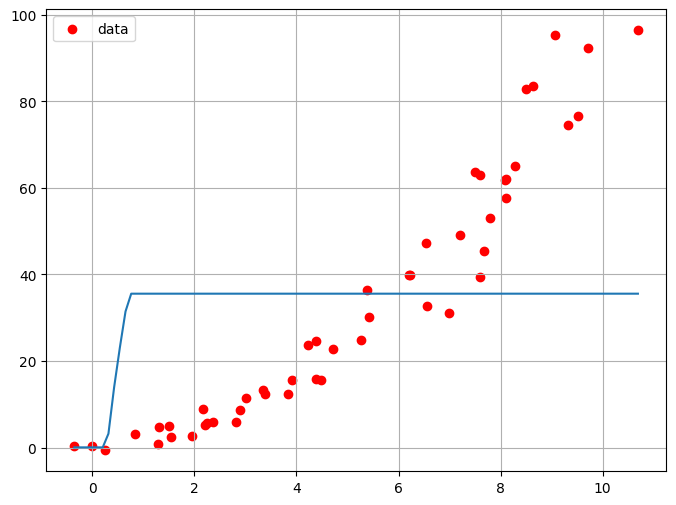

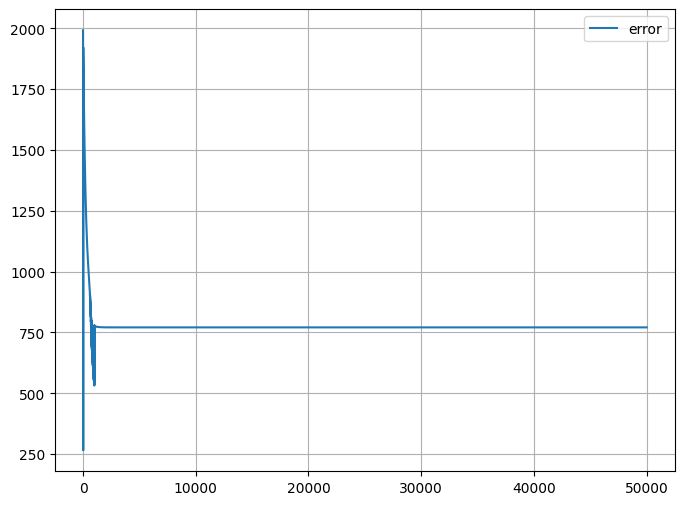

In [32]:
model = torch.nn.Sequential(
    torch.nn.Linear(1,5),
    torch.nn.ReLU(),
    torch.nn.Linear(5,5),
    torch.nn.ReLU(),
    torch.nn.Linear(5,5),
    torch.nn.ReLU(),
    torch.nn.Linear(5,1),
)

model, loss_list = learning_loop(x_true, y_true, model, steps, loss_fn, learning_rate, optimizer)

plt.figure(figsize=(8,6))
x = torch.linspace(x_true.min(), x_true.max(), 100)[:,None]
y = model(x).detach()
plt.plot(x, y)
plt.scatter(data[:,0], data[:,1], marker='o', c='r', label="data")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8,6))
plt.plot(range(steps), loss_list, label="error")
plt.legend()
plt.grid(True)
plt.show()

Qué resultados más raros... ¡Vamos a echar un vistazo al gradiente que se obtiene!

In [35]:
loss = torch.nn.MSELoss()(model(x_true), y_true)
loss.backward()
print([param.grad for param in model.parameters()])

[tensor([[0.],
        [0.],
        [0.],
        [0.],
        [0.]]), tensor([0., 0., 0., 0., 0.]), tensor([[0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0.]]), tensor([0., 0., 0., 0., 0.]), tensor([[0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0.]]), tensor([-0.0004,  0.0000,  0.0000,  0.0000, -0.0004]), tensor([[0.0004, 0.0000, 0.0000, 0.0000, 0.0003]]), tensor([-0.0057])]


UPS. Parece que hemos perdido el gradiente. Probablemente los valores han entrado en la zona no sensible de la función de activación. ¡Veamos si cambiamos por LeakyReLU!

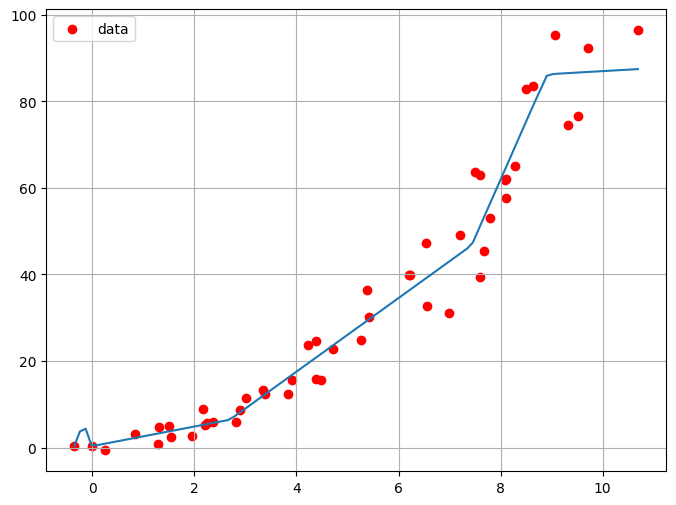

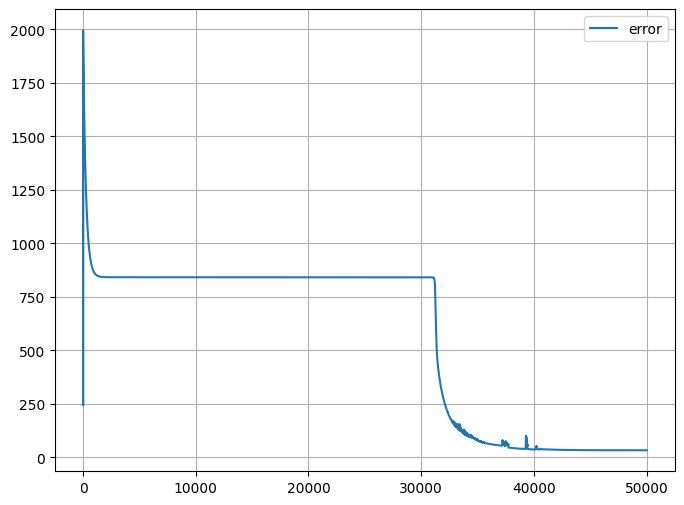

In [36]:
model = torch.nn.Sequential(
    torch.nn.Linear(1,5),
    torch.nn.LeakyReLU(),
    torch.nn.Linear(5,5),
    torch.nn.LeakyReLU(),
    torch.nn.Linear(5,5),
    torch.nn.LeakyReLU(),
    torch.nn.Linear(5,1),
)

model, loss_list = learning_loop(x_true, y_true, model, steps, loss_fn, learning_rate, optimizer)

plt.figure(figsize=(8,6))
x = torch.linspace(x_true.min(), x_true.max(), 100)[:,None]
y = model(x).detach()
plt.plot(x, y)
plt.scatter(data[:,0], data[:,1], marker='o', c='r', label="data")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8,6))
plt.plot(range(steps), loss_list, label="error")
plt.legend()
plt.grid(True)
plt.show()

Parece que no somos capaces de obtener una curva bonita como la función y=x<sup>2</sup>. Vaya decepción, ¿no? Aunque en honor a la verdad, estamos consiguiendo aproximaciones a los datos que parecen razonables. Simplemente no son la función de la que nosotros sabemos que vienen los datos, ¡pero es que normalmente nos abemos la función de origen! Una aproximación razonable es lo máximo que podemos conseguir...

Supongo que la siguiente pregunta es... ¿Cómo se diseña una red neuronal? ¿Cómo decidimos cuántas capas? ¿Cuántas neuronas por capa? ¿Qué función de activación en cada capa? Lo cierto es... que no hay ningún método. El Teorema de Aproximación Universal de 1989 demuestra que un MLP con al menos una capa oculta con una función de activación como las que hemos visto y una salida lineal debería ser capaz de aproximar cualquier función. Lo que no dice el Teorema es cuántas neuronas necesita esa capa oculta ni cómo entrenar ese hipotético MLP. Solo dice que existe la solución, pero ni cuál es ni cómo alcanzarla. Para el diseño uno se tiene que guiar por la prueba y error, su experiencia, su conocimiento de problemas similares y su intuición matemática.

¿Ponemos entonces una sola capa oculta en los MLPs y atacamos con eso todos los problemas? No. Aunque el teorema dice que existe esa solución, en muchos casos una capa oculta con muchísimas neuronas lineales no es fácil o rápido de entrenar y varias capas más pequeñas (o el uso de otras neuronas) permiten entrenamientos más estables que converjan a una solución. El número de neuronas de la última capa sí es fácil de deducir. Si quiero solo un valor como resultado, será una, si quiero mil valores, serán mil.

Respecto a las funciones de activación, hay que tener en mente que juegan dos papeles:

*   En las capas internas de un modelo sirven para transformar los datos. Ahí no hay un criterio general sobre cómo elegir función de activación, aunque la práctica experimental nos dice que funciones como la ReLU y la LeakyReLU **suelen** funcionar mejor que usar la tangente hiperbólica o la sigmoide.
*   En la última capa la elección de la función de activación viene restringido por el problema que estoy resolviendo. Si quiero un resultado entre dos opciones (por ejemplo para un problema de clasificación binaria) usaré una función sigmoide o una tangente hiperbólica. Si quiero resolver un problema de regresión general tendré que usar una cuyo codominio permita todos los reales como la LeakyReLU o (como hacíamos aquí) dejar la última capa sin activación específica y permitir que se comporte como una función lineal. Si el resultado es un número positivo cualquiera podríamos usar la ReLU.



---
# Parte 7: Modelos Neuronales III
---

In [1]:
import torch
import matplotlib.pyplot as plt
from tqdm import tqdm
import time
from torch.utils.data import Dataset, DataLoader

# Modelos Neuronales III

Autor: Jorge García González (Universidad de Málaga)

Última Actualización: 05/10/2026

Asignatura: Programación para la Inteligencia Artificial

Bien, en los cuadernos anteriores ya hemos empezado a entrenar modelos neuronales usando PyTorch y algunas herramientas de PyTorch para gestionar los datos durante el entrenamiento. Antes de seguir, vamos a ver cómo encaja tener un *DataLoader* en nuestro bucle de entrenamiento. Vamos a necesitar crear un *Dataset*. vamos a hacer uno genérico aunque no sea muy eficiente.

Pero antes, toca rescatar algunas funciones. get_data_from_a_polynomial y get_data_from_a_line han sido modificadas para que den resultados también menores en el dominio menor que 0.

In [2]:
def generate_polynomial(c_list):
  """
  Función para generar una función que aplique un polinomio.
  Args:
    c_list: Lista de coeficientes del polinomio. ej: [2,1,0] representa el polinomio y = 2x**2 + x + 0
  """
  def apply_polynomial(x):
    """
    Función para aplicar un polinomio.
    Args:
      x: las entradas a las que aplicarle el polinomio.
    """
    y = torch.cat([c*x[None,:]**index for index, c in enumerate(reversed(c_list))]).sum(dim=0)  # Para cada coeficiente (desde el final) operamos todas
                                                                                                # las x elevándolo a su índice (0,1,2,etc) y obtenemos
                                                                                                # una fila.
                                                                                                # El cat concatena las filas, así cada columna tiene,
                                                                                                # para un solo x, las operaciones de cada término del
                                                                                                # polinomio.
                                                                                                # Finalmente sumamos a lo largo de las columnas.
    return y

  return apply_polynomial

def get_data_from_a_polynomial(poly, n, sigma=2, range=50):
  """
  Función que devuelve datos a partir de una recta. Recordemos que la ecuación de la recta está definida por y=mx+b.
  Args:
    poly: Función que aplica un polinomio.
    n: número de datos que queremos obtener.
    sigma: desviación típica para el ruido que añadiremos a los datos (2 por defecto).
    range: extremos del rango [-range,range] en el eje x en el que queremos situar los datos (50 por defecto).
  """
  x = 2*range*torch.rand(n)-range                                                     # Generamos los datos en el eje x.
  y = poly(x)                                                                         # Obtenemos los valores del polinomio para cada x.
  noise_x = torch.normal(torch.zeros_like(y), sigma*torch.ones_like(y))               # Generamos un vector de ruido gaussiano para el eje x.
  noise_y = torch.normal(torch.zeros_like(y), sigma*torch.ones_like(y))               # Generamos un vector de ruido gaussiano para el eje y.
  x_with_noise = x + noise_x
  y_with_noise = y + noise_y

  data = torch.cat((x_with_noise[:,None], y_with_noise[:,None]), dim=1)
  return data

def get_data_from_a_line(m, b, n, sigma=2, range=50):
  """
  Función que devuelve datos a partir de una recta. Recordemos que la ecuación de la recta está definida por y=mx+b.
  Args:
    m: inclinación de la recta.
    b: ordenada en el origen de la recta.
    n: número de datos que queremos obtener.
    sigma: desviación típica para el ruido que añadiremos a los datos (2 por defecto).
    range: extremo del rango [0,rango] en el eje x en el que queremos situar los datos (50 por defecto).
  """
  x = 2*range*torch.rand(n)-range                                       # Generamos los datos en el eje x.
  y = m*x+b                                                             # Obtemeos la posición correspondiente en el eje y.
  noise_x = torch.normal(torch.zeros_like(y), sigma*torch.ones_like(y)) # Generamos un vector de ruido gaussiano para el eje x.
  noise_y = torch.normal(torch.zeros_like(y), sigma*torch.ones_like(y)) # Generamos un vector de ruido gaussiano para el eje y.
  x_with_noise = x + noise_x
  y_with_noise = y + noise_y

  data = torch.cat((x_with_noise[:,None], y_with_noise[:,None]), dim=1)
  return data

Vamos a hacer un *Dataset* que simplemente guarde llos valores de x e y. Por simplicidad vamos a aceptar que siempre estén en memoria. Esta vez vamos a omitir los transform.

In [3]:
class XYDataset(Dataset):
  def __init__(self, x, y):
    self.x = x
    self.y = y

  def __len__(self):
    # La longitud del Dataset coincide con el número de elementos del vector x.
    return self.x.numel()

  def __getitem__(self, idx):
    x = self.x[idx]
    y = self.y[idx]
    return torch.tensor([x]), torch.tensor([y])

Nótese que como elementos de la tupla devuelvo un vector de tamaño uno en vez de simplemente un número. Esto es para que luego los lotes tengan tamaño Bx1.

Ahora puedo generar un *Dataset* fácilmente.

In [80]:
polynomial_cofficients = [1,0,0,0]
polynomial = generate_polynomial(polynomial_cofficients)
data = get_data_from_a_polynomial(polynomial, 5, sigma=0.2, range=10)
x = data[:,0]
y = data[:,1]
xydataset = XYDataset(x, y)
print(len(xydataset))

5


Ahora tenemos que adaptar nuestro bucle de entrenamiento para funcionar en base a los lotes que genera un *DataLoader*

In [81]:
def learning_loop(dataloader, model, epochs, loss_fn, learning_rate, optimizer):
  epoch_loss_list = []

  opt = optimizer(
    model.parameters(),
    lr=learning_rate
  )

  for epoch in tqdm(range(epochs), desc="epoch:"):
    step_loss_list = []
    for x_true, y_true in dataloader:
      y_pred = model(x_true)                              # Forward
      opt.zero_grad()
      loss = loss_fn(y_pred, y_true)
      loss.backward()                                     # Backward
      step_loss_list.append(loss.clone().detach())
      opt.step()
    epoch_loss_list.append(torch.tensor(step_loss_list).mean())

  return model, epoch_loss_list

Este bucle representa la lógica general que *habitualmente* sigue un proceso de ajuste de parámetros respecto a las épocas. Entendemos por un paso de entrenamiento (un *step*), el paso que se da tras cada secuencia de *forward* y *backward* (el bucle interno). Ese bucle debería recorrer todos los datos del conjunto y a eso llamamos una época (*epoch*). Aunque según el problema puede ocurrir, la regla general es medir la longitud de los entrenamientos en épocas (el bucle exterior).

¿La dimensión ficticia que añadíamos a los datos de entrada en cuadernos anteriores antes de hacer el *forward*? La necesitabamos porque PyTorch asume que lo que se proporciona es un *batch* de datos. Por tanto, espera que la primera dimensión del tensor se corresponda con el tamaño del *batch*. Si tenemos N ejemplos en un vector de tamaño N y se le proporciona tal cuál, no sabe desambiguar si se trata de un único ejemplo compuesto por N valores o N ejemplos de 1 valor. Por eso le creabamos una dimensión ficticia al final y que PyTorch encontrara un tensor de tamaño Nx1 (N ejemplos de tamaño 1).

Como regla general, la primera dimensión es el *batch* y, por ejemplo, si trabajaramos con imágenes, cada batch tendría tamaño BxCxHxW (*batch*, canal, alto y ancho).

El tamaño del *batch* es uno de los hiperparámetros que deben definirse a la hora del entrenamiento, pero antes de hablar de eso vamos  ahacer una prueba de nuestro nuevo bucle de entrenamiento para aprender una recta.

Número de parámetros 405


epoch:: 100%|██████████| 2000/2000 [00:01<00:00, 1152.72it/s]


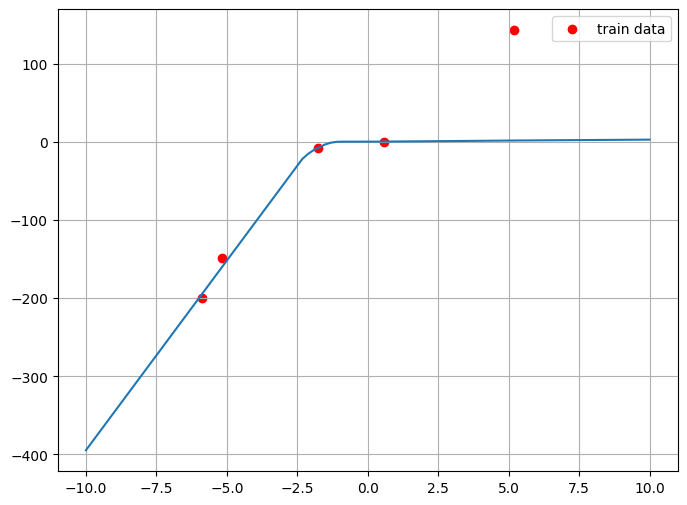

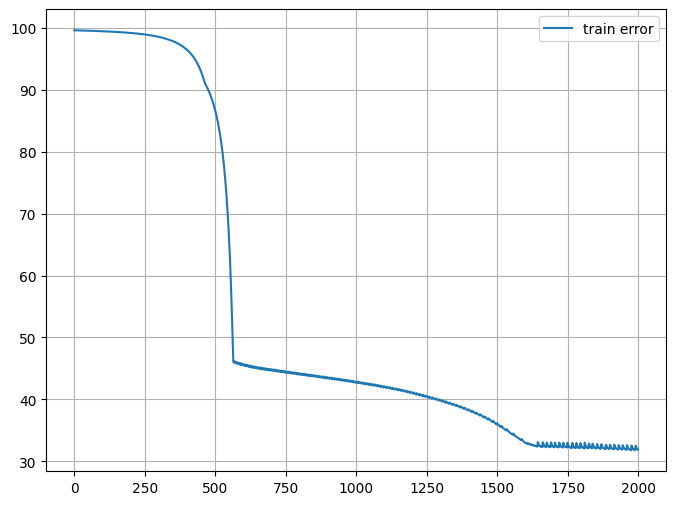

In [82]:
batch_size = 5
learning_rate = 1e-3
epochs = 2000
loss_fn = torch.nn.L1Loss()
optimizer = torch.optim.SGD

xyd_dataloader = DataLoader(xydataset, batch_size = batch_size, shuffle=True)

model = torch.nn.Sequential(
    torch.nn.Linear(1,12),
    torch.nn.LeakyReLU(),
    torch.nn.Linear(12,12),
    torch.nn.LeakyReLU(),
    torch.nn.Linear(12,16),
    torch.nn.LeakyReLU(),
    torch.nn.Linear(16,1),
)

print(f"Número de parámetros {torch.tensor([p.numel() for p in model.parameters()]).sum()}")

model, loss_list = learning_loop(xyd_dataloader, model, epochs, loss_fn, learning_rate, optimizer)

# Para mostrarlos sí que voy a obtener todos los elementos del Dataset.

data = torch.tensor([example for example in xydataset])
x_data = data[:,0]
y_data = data[:,1]
plt.figure(figsize=(8,6))
x = torch.linspace(-10, 10, 100)[:,None]
y = model(x).detach()
plt.plot(x, y)
plt.scatter(x_data, y_data, marker='o', c='r', label="train data")
#plt.scatter(val_line_data[:,0], val_line_data[:,1], marker='o', c='g', label="val data")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8,6))
plt.plot(range(epochs), loss_list, label="train error")
#plt.plot(range(0,steps, 10), loss_val_list, label="val error")
plt.legend()
plt.grid(True)
plt.show()

¡UPS! No ha salido muy recta que digamos...

Vale, sí, esta vez hemos hecho trampas. Le hemos dado muy pocos datos que sumado al ruido de los mismos han hecho que no converga a la recta que debería. Hemos provocado el problema pudiendo evitarlo fácilmente, pero ha sido por una cuestión didáctica. Estamos ante un caso de sobreajuste (*overfitting*). Cuando el modelo se ajusta más a los datos de lo que es deseable y pierde en cierta medida la capacidad de *generalizar*.

Se entiende que en asignaturas anteriores se ha estudiado el fenómeno del sobreajuste, así que no vamos a extendernos sobre él. La pregunta es: ¿Cómo analizamos el sobreajuste en Aprendizaje Profundo? Pues con la estrategia que se usa en general para el Aprendizaje Computacional: necesitamos evaluar el modelo en datos que no se usan para entrenar. ¡Solo que en Aprendizaje profundo acostumbramos a hacerlo mientras entrenamos! A esos datos los solemos llamar conjunto de validación (en contraposición al conjunto de entrenamiento).

¡Vamos a contemplarlo en nuestro bucle de entrenamiento!

In [83]:
def learning_loop_with_val(train_dataloader, val_dataloader, model, epochs, loss_fn, learning_rate, optimizer):
  train_loss_list = []
  val_loss_list = []
  opt = optimizer(
    model.parameters(),
    lr=learning_rate
  )

  for epoch in tqdm(range(epochs), desc="epoch:"):
    train_step_loss_list = []
    for x_train_true, y_train_true in train_dataloader:
      y_pred = model(x_train_true)                              # Forward
      opt.zero_grad()
      loss = loss_fn(y_pred, y_train_true)
      loss.backward()                                     # Backward
      train_step_loss_list.append(loss.clone().detach())
      opt.step()
    train_loss_list.append(torch.tensor(train_step_loss_list).mean())

    # Realizaremos una época de validación cada 10 pasos de entrenamiento para
    # minimizar los cálculos que no son estrictamente necesarios.
    if epoch % 10 == 0:
      val_step_loss_list = []
      with torch.no_grad():
        for x_val_true, y_val_true in val_dataloader:
          y_val_pred = model(x_val_true)
          loss_val = loss_fn(y_val_pred, y_val_true)
          val_step_loss_list.append(loss_val)
        val_loss_list.append(torch.tensor(val_step_loss_list).mean())

  return model, train_loss_list, val_loss_list

Generamos un *Dataset* de validación...

In [85]:
polynomial_cofficients = [1,0,0,0]
polynomial = generate_polynomial(polynomial_cofficients)
val_data = get_data_from_a_polynomial(polynomial, 5, sigma=0.2, range=10)
val_x = val_data[:,0]
val_y = val_data[:,1]
val_xydataset = XYDataset(val_x, val_y)
print(len(val_xydataset))

5


Número de parámetros 405


epoch:: 100%|██████████| 2000/2000 [00:01<00:00, 1107.43it/s]


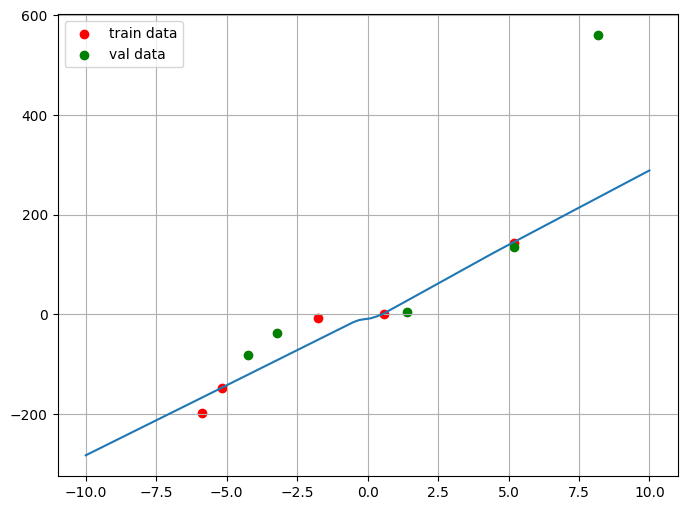

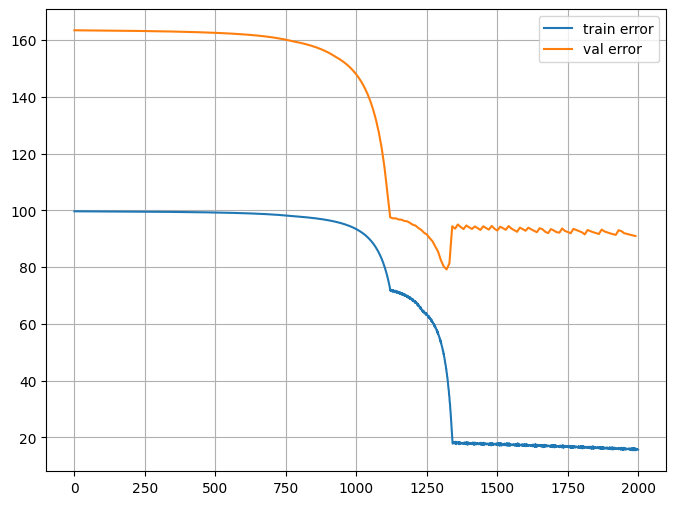

In [86]:
batch_size = 5
learning_rate = 1e-3
epochs = 2000
loss_fn = torch.nn.L1Loss()
optimizer = torch.optim.SGD

val_xyd_dataloader = DataLoader(val_xydataset, batch_size=batch_size, shuffle=True)
train_xyd_dataloader = DataLoader(xydataset, batch_size = batch_size, shuffle=True)

model = torch.nn.Sequential(
    torch.nn.Linear(1,12),
    torch.nn.LeakyReLU(),
    torch.nn.Linear(12,12),
    torch.nn.LeakyReLU(),
    torch.nn.Linear(12,16),
    torch.nn.LeakyReLU(),
    torch.nn.Linear(16,1),
)

print(f"Número de parámetros {torch.tensor([p.numel() for p in model.parameters()]).sum()}")

model, train_loss_list, val_loss_list = learning_loop_with_val(train_xyd_dataloader, val_xyd_dataloader, model, epochs, loss_fn, learning_rate, optimizer)

# Para mostrarlos sí que voy a obtener todos los elementos del Dataset.

train_data = torch.tensor([example for example in xydataset])
train_x_data = train_data[:,0]
train_y_data = train_data[:,1]
val_data = torch.tensor([example for example in val_xydataset])
val_x_data = val_data[:,0]
val_y_data = val_data[:,1]
plt.figure(figsize=(8,6))
x = torch.linspace(min(train_x_data.min(),val_x_data.min(), -10), max(train_x_data.max(),val_x_data.max(), 10), 100)[:,None]
y = model(x).detach()
plt.plot(x, y)
plt.scatter(train_x_data, train_y_data, marker='o', c='r', label="train data")
plt.scatter(val_x_data, val_y_data, marker='o', c='g', label="val data")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8,6))
plt.plot(range(epochs), train_loss_list, label="train error")
plt.plot(range(0,epochs, 10), val_loss_list, label="val error")
plt.legend()
plt.grid(True)
plt.show()

Ahora tenemos dos evoluciones del error para evaluar qué tal está aprendiendo nuestro modelo. El error sobre los datos entrenados nos da una impresión de si el modelo está aprendiendo o hay algún problema, mientras que el error sobre los datos de validación nos da una impresión de la capacidad de generalizar del modelo. Nos dice cómoe voluciona el error esperable con datos con los que no se ha entrenado.

Típicamente nos interesa seguir entrenando el modelo mientras ambos errores vayan descendiendo. Si el error sobre los datos de entrenamiento desciende, pero el error sobre los datos de validación aumenta (como está ocurriendo en nuestro ejemplo), sabemos que nuestro modelo está sobreentrenando (pierde capacidad de generalización).

¿Cuál es el punto interesante? Típicamente, antes de que empiece el sobreentrenamiento. En el ejemplo de arriba podemos ver que nuestro modelo generalizaba mejor antes de la época 1500.

Antes de términar debemos volver al asunto de los lotes. Uno podría pensar que la útilidad de los lotes es meramente técnica. Típicamente trabajamos con una cantidad de datos superior a la que podemos procesar o mantener en memoria a la vez, así que los dividimos. Es una razón, sí, pero hay alguna ventaja más.

Para entrenar estamos usando el Stochastic Gradient Descent... Si solo se basara en el descenso del gradiente se llamaría Gradient Descent a secas, ¿no? ¿Cuál es la parte estocástica? Justamente la elección de los datos. En nuestras primeras versiones del entrenamiento vimos cómo usar solo un dato era contraproducente para la convergencia. Vamos a hacer unos experimentos para ver qué ocurre si cambiamos el tamaño del lote.

Preparamos un conjunto de datos para ajustar una recta porque queremos poder visualizar los parámetros.

In [4]:
data_size = 50
line_data = get_data_from_a_line(1, 0, data_size, sigma=0.5, range=10)
x = line_data[:,0]
y = line_data[:,1]
xydataset = XYDataset(x, y)
print(len(xydataset))

50


Un color para cada experimento y algunos hiperparámetros que dejaremos fijos. En estos experimentos vamos a forzar que siempre comencemos con $m=0.9$ y $b=0.1$. El objetivo es llegar a $m=1$ y $b=0$. Mostraremos el valor de $b$ en el eje vertical y $m$ en el horizontal según avanzan los pasos de entrenamiento. El objetivo es hacer 3 experimentos que distintos que comiencen con los mismos parámetros y solo se vea afectado por cómo se cargan los datos.

In [5]:
colors = ['r', 'g', 'b']
learning_rate = 1e-3
loss_fn = torch.nn.L1Loss()
epochs=50
initial_m = 0.9
initial_b = 0.1

Veamos qué ocurre si el tamaño de lote es 1: cada paso de entrenamiento se hace con un único dato. Además, antes de cada experimento vamos a barajar los datos.

epoch:: 100%|██████████| 50/50 [00:01<00:00, 48.78it/s]


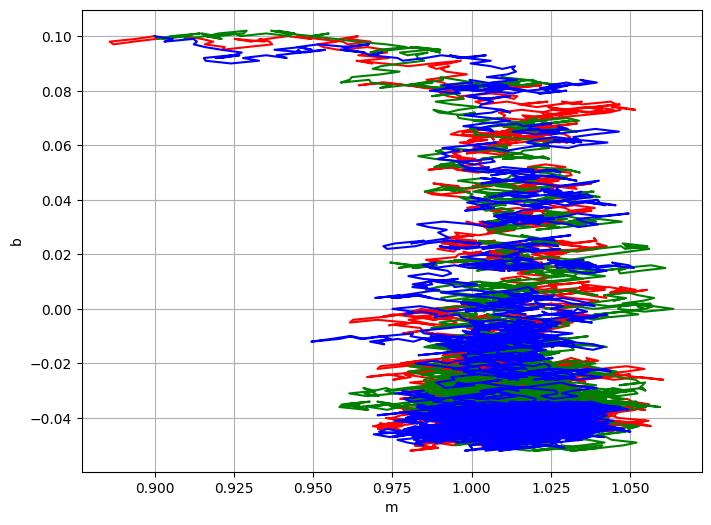

In [6]:
batch_size=1

plt.figure(figsize=(8,6))

for c in colors:
    model = torch.nn.Linear(1,1)
    model.weight = torch.nn.Parameter(torch.tensor([[initial_m]]), requires_grad=True)
    model.bias = torch.nn.Parameter(torch.tensor(initial_b), requires_grad=True)
    train_xyd_dataloader = DataLoader(xydataset, batch_size = batch_size, shuffle=True)


    m = model.weight
    b = model.bias
    line_evolution_m = [m[0].clone().detach()]               # A las listas no añadimos el parámetro, sino una copia que nos aseguramos
    line_evolution_b = [b.clone().detach()]                  # de sacar del grafo usando un detach()

    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=learning_rate
    )

    for epoch in tqdm(range(epochs), desc="epoch:"):
        train_step_loss_list = []
        for x_true, y_true in train_xyd_dataloader:
            y_pred = model(x_true)                              # Forward
            optimizer.zero_grad()
            loss = loss_fn(y_pred, y_true)
            loss.backward()                                     # Backward
            m = model.weight
            b = model.bias
            optimizer.step()

            line_evolution_m.append(m[0].clone().detach())
            line_evolution_b.append(b.clone().detach())


    plt.plot(line_evolution_m, line_evolution_b, color=c)

plt.ylabel('b')
plt.xlabel('m')
plt.grid(True)
plt.show()

Muchísimo ruido, ¿no? Tiene sentido. Cada dato tiene ruido, lo que implica que la dirección del gradiente tendrá ruido también. La flecha que dirige la actualización de los parámetros es muy inestable. Veamos con tamaño de lote 10.

epoch:: 100%|██████████| 50/50 [00:00<00:00, 337.94it/s]


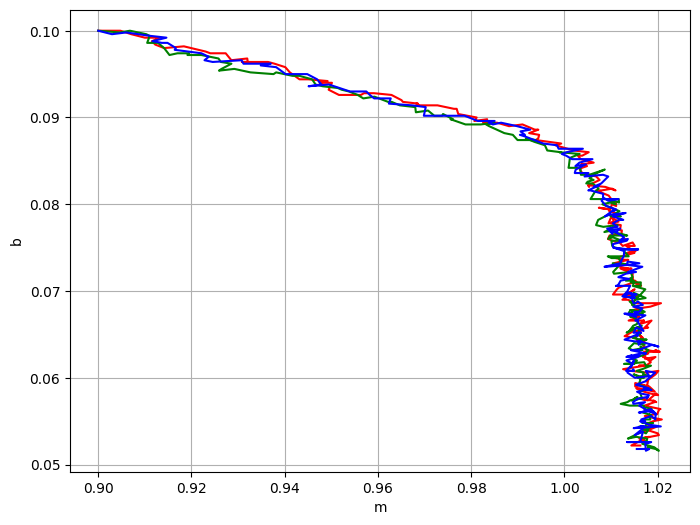

In [7]:
batch_size=10

plt.figure(figsize=(8,6))

for c in colors:
    model = torch.nn.Linear(1,1)
    model.weight = torch.nn.Parameter(torch.tensor([[initial_m]]), requires_grad=True)
    model.bias = torch.nn.Parameter(torch.tensor(initial_b), requires_grad=True)
    train_xyd_dataloader = DataLoader(xydataset, batch_size = batch_size, shuffle=True)


    m = model.weight
    b = model.bias
    line_evolution_m = [m[0].clone().detach()]               # A las listas no añadimos el parámetro, sino una copia que nos aseguramos
    line_evolution_b = [b.clone().detach()]                  # de sacar del grafo usando un detach()

    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=learning_rate
    )

    for epoch in tqdm(range(epochs), desc="epoch:"):
        train_step_loss_list = []
        for x_true, y_true in train_xyd_dataloader:
            y_pred = model(x_true)                              # Forward
            optimizer.zero_grad()
            loss = loss_fn(y_pred, y_true)
            loss.backward()                                     # Backward
            m = model.weight
            b = model.bias
            optimizer.step()

            line_evolution_m.append(m[0].clone().detach())
            line_evolution_b.append(b.clone().detach())


    plt.plot(line_evolution_m, line_evolution_b, color=c)
plt.ylabel("b")
plt.xlabel("m")
plt.grid(True)
plt.show()

No hay tanto ruido, pero vemos que los tres experimentos, aunque tienen un comportamiento muy parecido, no son exactamente iguales. Los parámetros no evolucionan "tanto" porque al aumentar el tamaño del lote, disminuimos el número de pasos de entrenamiento por época(recordemos que una época es usar cada dato una sola vez). Ahora repetimos el experimento sin indicarle al Dataloader que baraje los datos.

epoch::   0%|          | 0/50 [00:00<?, ?it/s]

epoch:: 100%|██████████| 50/50 [00:00<00:00, 350.92it/s]


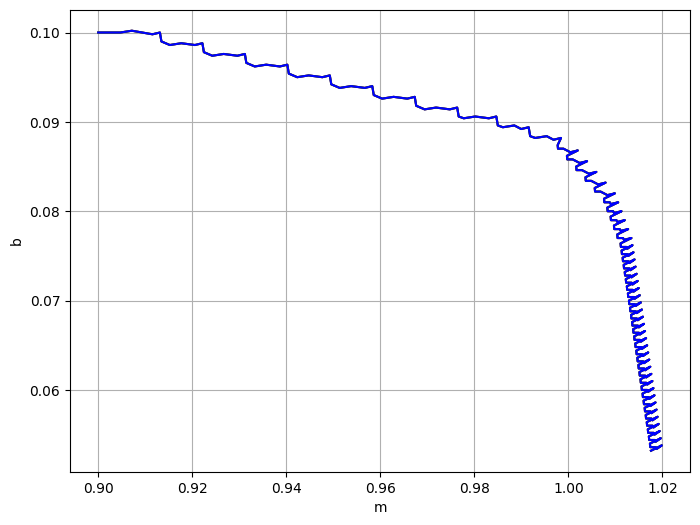

In [ ]:
batch_size=10

plt.figure(figsize=(8,6))

for c in colors:
    model = torch.nn.Linear(1,1)
    model.weight = torch.nn.Parameter(torch.tensor([[initial_m]]), requires_grad=True)
    model.bias = torch.nn.Parameter(torch.tensor(initial_b), requires_grad=True)
    train_xyd_dataloader = DataLoader(xydataset, batch_size = batch_size, shuffle=False)


    m = model.weight
    b = model.bias
    line_evolution_m = [m[0].clone().detach()]               # A las listas no añadimos el parámetro, sino una copia que nos aseguramos
    line_evolution_b = [b.clone().detach()]                  # de sacar del grafo usando un detach()

    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=learning_rate
    )

    for epoch in tqdm(range(epochs), desc="epoch:"):
        train_step_loss_list = []
        for x_true, y_true in train_xyd_dataloader:
            y_pred = model(x_true)                              # Forward
            optimizer.zero_grad()
            loss = loss_fn(y_pred, y_true)
            loss.backward()                                     # Backward
            m = model.weight
            b = model.bias
            optimizer.step()

            line_evolution_m.append(m[0].clone().detach())
            line_evolution_b.append(b.clone().detach())


    plt.plot(line_evolution_m, line_evolution_b, color=c)
plt.ylabel("b")
plt.xlabel("m")
plt.grid(True)
plt.show()

¡Anda! Los tres experimentos son exactamente iguales (se pintan los tres en el mismo lugar). Antes de sacar más conclusiones, vamos a probar con un tamaño del lote igual al número total de datos. Un paso de entrenamiento por época y barajando los datos.

epoch:: 100%|██████████| 50/50 [00:00<00:00, 759.58it/s]


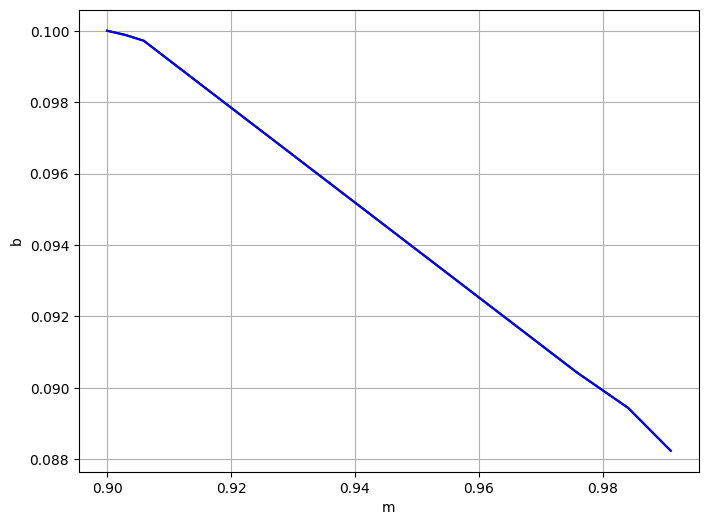

In [ ]:
batch_size=data_size

plt.figure(figsize=(8,6))

for c in colors:
    model = torch.nn.Linear(1,1)
    model.weight = torch.nn.Parameter(torch.tensor([[initial_m]]), requires_grad=True)
    model.bias = torch.nn.Parameter(torch.tensor(initial_b), requires_grad=True)
    train_xyd_dataloader = DataLoader(xydataset, batch_size = batch_size, shuffle=True)


    m = model.weight
    b = model.bias
    line_evolution_m = [m[0].clone().detach()]               # A las listas no añadimos el parámetro, sino una copia que nos aseguramos
    line_evolution_b = [b.clone().detach()]                  # de sacar del grafo usando un detach()

    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=learning_rate
    )

    for epoch in tqdm(range(epochs), desc="epoch:"):
        train_step_loss_list = []
        for x_true, y_true in train_xyd_dataloader:
            y_pred = model(x_true)                              # Forward
            optimizer.zero_grad()
            loss = loss_fn(y_pred, y_true)
            loss.backward()                                     # Backward
            m = model.weight
            b = model.bias
            optimizer.step()

            line_evolution_m.append(m[0].clone().detach())
            line_evolution_b.append(b.clone().detach())


    plt.plot(line_evolution_m, line_evolution_b, color=c)
plt.ylabel("b")
plt.xlabel("m")
plt.grid(True)
plt.show()

¡Qué bonito! Sin embargo, los parámetros han evolucionado poco (solo una actualización por época). Vamos a repetir el experimento con 200 épocas.

epoch:: 100%|██████████| 200/200 [00:00<00:00, 734.05it/s]


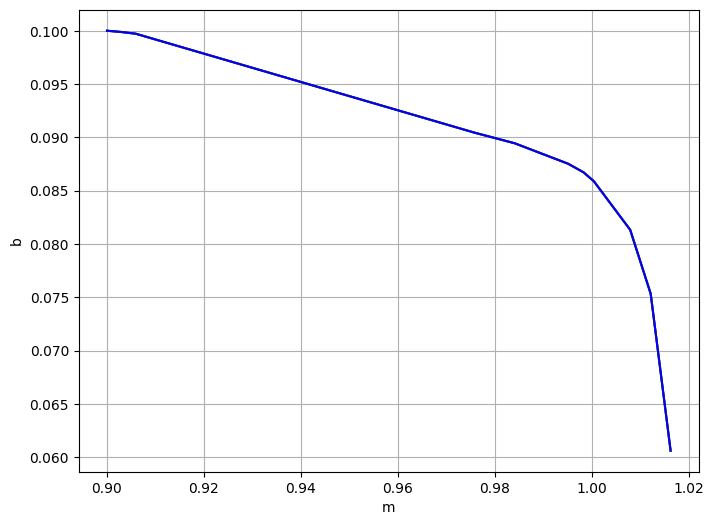

In [16]:
epochs=200
batch_size=data_size

plt.figure(figsize=(8,6))

for c in colors:
    model = torch.nn.Linear(1,1)
    model.weight = torch.nn.Parameter(torch.tensor([[initial_m]]), requires_grad=True)
    model.bias = torch.nn.Parameter(torch.tensor(initial_b), requires_grad=True)
    train_xyd_dataloader = DataLoader(xydataset, batch_size = batch_size, shuffle=True)


    m = model.weight
    b = model.bias
    line_evolution_m = [m[0].clone().detach()]               # A las listas no añadimos el parámetro, sino una copia que nos aseguramos
    line_evolution_b = [b.clone().detach()]                  # de sacar del grafo usando un detach()

    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=learning_rate
    )

    for epoch in tqdm(range(epochs), desc="epoch:"):
        train_step_loss_list = []
        for x_true, y_true in train_xyd_dataloader:
            y_pred = model(x_true)                              # Forward
            optimizer.zero_grad()
            loss = loss_fn(y_pred, y_true)
            loss.backward()                                     # Backward
            m = model.weight
            b = model.bias
            optimizer.step()

            line_evolution_m.append(m[0].clone().detach())
            line_evolution_b.append(b.clone().detach())


    plt.plot(line_evolution_m, line_evolution_b, color=c)
plt.ylabel("b")
plt.xlabel("m")
plt.grid(True)
plt.show()

Parece una evolución muy estable, aunque barajar no ha evitado esta vez que los tres experimentos sean exactamente iguales. Son dos fenómenos relacionados. Si usamos todos los datos para calcular el gradiente en cada paso, el ruido de los mismos se compensa y el entrenamiento se vuelve más estable. Da igual el orden porque el error es una media y el gradiente de la media es la media de los gradientes. Para confirmarlo, vamos a repetir los experimentos sin barajar el DataLoader antes de cada ejecución.

epoch:: 100%|██████████| 200/200 [00:00<00:00, 791.07it/s]


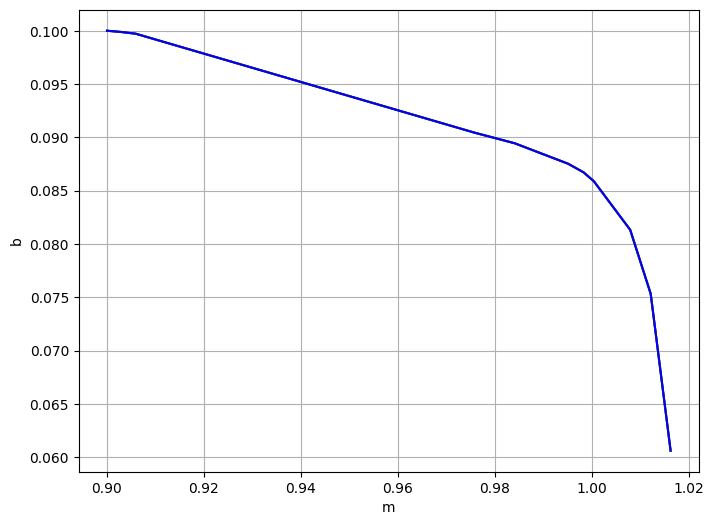

In [17]:
epochs=200
batch_size=data_size

plt.figure(figsize=(8,6))

for c in colors:
    model = torch.nn.Linear(1,1)
    model.weight = torch.nn.Parameter(torch.tensor([[initial_m]]), requires_grad=True)
    model.bias = torch.nn.Parameter(torch.tensor(initial_b), requires_grad=True)
    train_xyd_dataloader = DataLoader(xydataset, batch_size = batch_size, shuffle=False)


    m = model.weight
    b = model.bias
    line_evolution_m = [m[0].clone().detach()]               # A las listas no añadimos el parámetro, sino una copia que nos aseguramos
    line_evolution_b = [b.clone().detach()]                  # de sacar del grafo usando un detach()

    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=learning_rate
    )

    for epoch in tqdm(range(epochs), desc="epoch:"):
        train_step_loss_list = []
        for x_true, y_true in train_xyd_dataloader:
            y_pred = model(x_true)                              # Forward
            optimizer.zero_grad()
            loss = loss_fn(y_pred, y_true)
            loss.backward()                                     # Backward
            m = model.weight
            b = model.bias
            optimizer.step()

            line_evolution_m.append(m[0].clone().detach())
            line_evolution_b.append(b.clone().detach())


    plt.plot(line_evolution_m, line_evolution_b, color=c)
plt.ylabel("b")
plt.xlabel("m")
plt.grid(True)
plt.show()

¡Exactamente igual! Barajar los datos no sirve de nada si todos se usan para calcular el gradiente.

A más datos, más se compensan entre sí los ruidos que introduce cada uno. Tener lotes más pequeños aumenta el ruido y hace que el entrenamiento sea más inestable.

Sin embargo, también tiene una ventaja: ¡Ayuda a "evitar" mínimos locales o puntos silla! Si simplemente obtuvieramos el gradiente de todos nuestros datos, el camino que ese gradiente marca desde un punto de partida en la función que queremos minimizar sería determinista (para un proceso de aprendizaje concreto, un ratio de aprendizaje concreto, etc). Por eso ha salido exactamente el mismor esultado con y sin barajeo de los datos. Si por el camino encuentra un mínimo local o un punto silla, la "dirección" de salida siempre va a ser la misma. Si esa "dirección" no ayuda a "escapar" del punto... No va a cambiar nunca.

Por otro lado, coger distintos subconjuntos de datos hacen que el gradiente sea inestable. No tan "aproximado" al ideal como podría ser. En cada iteración sería distinto. Si entramos en un mínimo local o punto silla para un subconjunto de datos, para otro subconjunto puede no serlo. De manera natural en cada iteración se probarían distintas "direcciones" de salida. Esa es la razón por la que es recomendable indicarle al *DataLoader* que reordene los datos. Así cada experimento no es exactamente igual. Podemos incluso barajar tras cada época. ¡Así las distintas combinaciones de datos producen gradientes distintos en cada época! Es meter ruido en el "camino" del entrenamiento, pero ese ruido nos ayuda a salir de mínimos del que un camino ideal y único no podría.

La siguiente imagen tomado prestada (;P) del libro Deep Learnign with PyTorch lo ilustra:

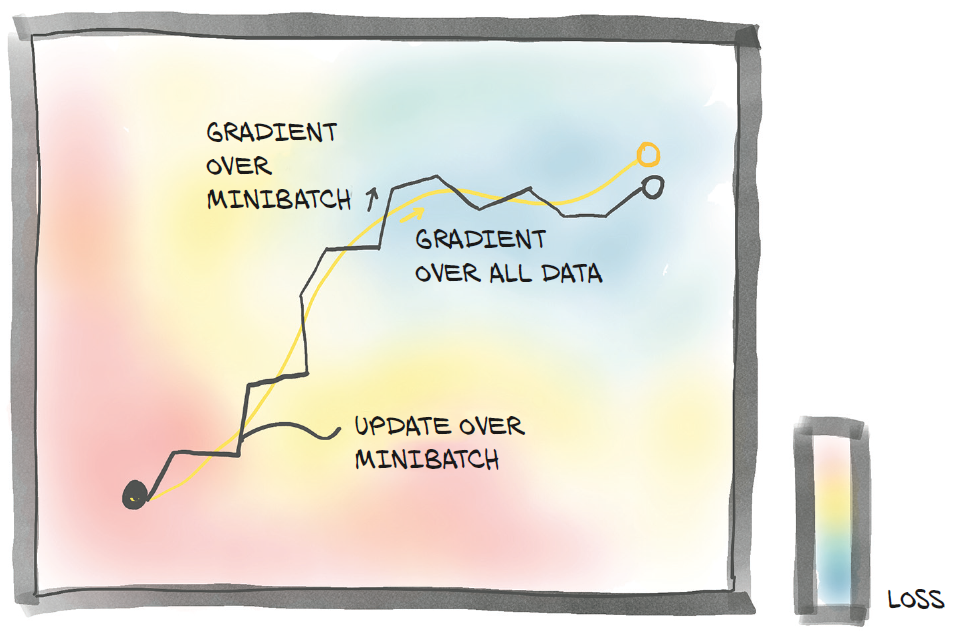

Ahora puede haber varias preguntas. Una es si esto es contraproducente porque nos saque del mínimo absoluto. La respuesta es que podría ocurrir, si es el mínimo absoluto, se espera que el proceso estocástico volviera a "lanzarnos dentro" de ese mínimo. Otra pregunta puede ser si el error que introducimos puede evitar la convergencia y... sí. Por eso es importante que hagamos ajustes pequeños (controlado con el ratio de aprendizaje). Para que si un conjunto de datos introduce tanto ruido que el gradiente se aleja mucho del ideal, solo hayamos dado un pequeño paso en una dirección "demasiado" equivocada. Tampoco es importante no usar lotes demasiado pequeños.

¿Entonces de qué tamaño es ideal poner los lotes? Como muchas otras cosas... depende del problema y del hardware. Lo ideal es aprovechar la capacidad de cómputo de la GPU, así que habría que usar lotes lo suficientemente grandes. Lotes demasiado pequeños (como un único ejemplo) tendrían demasiado ruido... Pero usar todos los datos nos hace perder el componente estocástico. Hay que buscar un punto de equilibrio. 

---
# Parte 8: Modelos Neuronales IV
---

In [146]:
import os
import torch
import torch.nn as nn
from torch.nn.parameter import Parameter

# Modelos Neuronales IV

> Autor: Jorge García González (Universidad de Málaga)

> Última Actualización: 9/10/2025

> Asignatura: Programación para la Inteligencia Artificial

En el cuaderno anterior hemos hablado de cómo definir en PyTorch un modelo neuronal de varias capas usando **torch.nn.Sequential()**. Antes de continuar con más cuestiones teóricas es importante que hablemos de algunas utilidades relacionadas con los modelos neuronales en PyTorch. **torch.nn.Sequential()** es una manera muy útil de definir modelos a partir de capas predefinidas, pero en ocasiones necesitamos definir ajustables más complicados que simplemente aplicar capas y activaciones de manera secuencial. PyTorch ofrece una manera más flexible de definir nuestros modelos: simplemente definirlos como una clase nueva con el comportamiento que queramos. Vamos a ver un ejemplo en el que creamos un modelo de PyTorch para modelar una recta como hemos hecho en cuadernos anteriores.

In [147]:
class Line_2D_Model_PyTorch(torch.nn.Module):
  def __init__(self):
    super().__init__()              # Llamamos al constructor de la clase de la que heredamos por si tuviera algo que inicializar.
    self.m = Parameter(torch.rand(1))
    self.b = Parameter(torch.tensor(0).float())

  def forward(self,x):
    return self.m*x+self.b

  def extra_repr(self):
    return f"inclinación={float(self.m.clone().detach())}, ordenada en el origen={float(self.b.clone().detach())}"

Como podemos ver, definimos una clase que hereda de **torch.nn.Module** y definimos sus parámetros optimizables como atributos de la clase indicados con **torch.nn.parameter.Parameter**. Luego definimos cómo opera este módulo su paso hacia delante con el método **forward**. El método **extra_repr** es simplemente una utilidad para definir qué mostrará la clase en un **print**.

In [148]:
line_2d_model = Line_2D_Model_PyTorch()
print(line_2d_model)
print([p for p in line_2d_model.parameters()])
x=10
print(line_2d_model(x))

Line_2D_Model_PyTorch(inclinación=0.07441467046737671, ordenada en el origen=0.0)
[Parameter containing:
tensor([0.0744], requires_grad=True), Parameter containing:
tensor(0., requires_grad=True)]
tensor([0.7441], grad_fn=<AddBackward0>)


Poder definir el constructor y el *forward* nos da libertad prácticamente absoluta para definir nuestros modelos siempre que durante el *forward* utilicemos operaciones que sean diferenciables para PyTorch (o no podrá realizar el *backward*).

Ahora vamos a ver un ejemplo un poco más complejo en el que definimos un MLP, pero de una manera más personalizada que usando el modelo secuencial de PYTorch. Asumiremos que somos demasiado perezosos para definir las capas línea por línea y queremos automatizarlo.

In [149]:
class My_MLP(torch.nn.Module):
  def __init__(self, list_of_neurons, list_of_activations, device='cpu'):
    super().__init__()         # Llamamos al constructor de la clase de la que heredamos por si tuviera algo que inicializar.
    self.list_of_layers = []
    self.list_of_activations = list_of_activations

    assert len(list_of_neurons)==len(list_of_activations)           # Sanity Check.

    for n in list_of_neurons:
      if len(self.list_of_layers)==0:
        self.list_of_layers.append(nn.LazyLinear(n).to(device))
      else:
        self.list_of_layers.append(nn.Linear(previous_n, n).to(device))
      previous_n=n

  def forward(self, inputs):
    outputs = None
    for layer, activation in zip(self.list_of_layers, self.list_of_activations):
      outputs = activation(layer(inputs)) if outputs is None else activation(layer(outputs))
    return outputs

  def extra_repr(self):
    return f"{[p for p in self.parameters()]}"

Es una lógica sencilla en la que inicializamos la instancia comprobando que la longitud de la lista con las neuronas por capa y el número de funciones de activación coincide (**assert** comprueba que una condición se cumple y para la ejecución con un error en caso contrario) y luego inicializamos todas las capas lineales de PyTorch (recordemos que no incluyen activación) con el número indicado. A la hora de hacer el paso hacia adelante simplemente vamos ejecutando capa a capa con su correspondiente función de activación.

Hay un detalle interesante en este código: el uso de LazyLinear para la primera capa. LazyLinear simplemente es una capa Lineal "vaga" que no requiere indicar el tamaño de la entrada (más información: https://docs.pytorch.org/docs/stable/generated/torch.nn.LazyLinear.html#torch.nn.LazyLinear)

Vamos a probarlo...

In [150]:
list_of_neurons = [3,5,1]
list_of_activations = 3*[torch.nn.ReLU()]
mlp = My_MLP(list_of_neurons, list_of_activations)
print(list_of_neurons)
print(list_of_activations)
print(mlp)

[3, 5, 1]
[ReLU(), ReLU(), ReLU()]
My_MLP([])


Ups. Hemos definido que muestre los parámetros del MLP cuando hacemos un print, sin embargo, la lista de parámetros está vacía. Esto indcia que PyTorch no reconoce ningún parámetro optimizable. Problemático. ¿No podemos entonces usar otros objetos **torch.nn.Module** (que es lo que son los **torch.nn.Linear**) al crear nuestra propia **torch.nn.Module** clase? Hagamos otra prueba suponiendo una clase que solo funciona para MLPs con dos capas ocultas más la capa de salida.

In [151]:
class My_MLP(torch.nn.Module):
  def __init__(self, list_of_neurons, list_of_activations, device='cpu'):
    super().__init__()         # Llamamos al constructor de la clase de la que heredamos por si tuviera algo que inicializar.
    self.layer1 = nn.LazyLinear(list_of_neurons[0]).to(device)
    self.layer2 = nn.Linear(list_of_neurons[0], list_of_neurons[1]).to(device)
    self.layer3 = nn.Linear(list_of_neurons[1], list_of_neurons[2]).to(device)
    self.activation1 = list_of_activations[0]
    self.activation2 = list_of_activations[1]
    self.activation3 = list_of_activations[2]

  def forward(self, inputs):
    outputs = self.activation1(self.layer1(inputs))
    outputs = self.activation2(self.layer2(outputs))
    outputs = self.activation3(self.layer3(outputs))
    return outputs

  def extra_repr(self):
    return f"{[p for p in self.parameters()]}"

In [152]:
list_of_neurons = [3,5,1]
list_of_activations = 3*[torch.nn.ReLU()]
mlp = My_MLP(list_of_neurons, list_of_activations)
print(list_of_neurons)
print(list_of_activations)
print(mlp)

[3, 5, 1]
[ReLU(), ReLU(), ReLU()]
My_MLP(
  [<UninitializedParameter>, <UninitializedParameter>, Parameter containing:
  tensor([[ 0.2323, -0.3665, -0.1739],
          [-0.0948,  0.0778,  0.3858],
          [-0.0061, -0.1340, -0.2615],
          [-0.3173,  0.1205, -0.5644],
          [-0.5141, -0.2040, -0.4174]], requires_grad=True), Parameter containing:
  tensor([ 0.2320, -0.3404,  0.1516,  0.0970, -0.2009], requires_grad=True), Parameter containing:
  tensor([[-0.3354,  0.1948,  0.2246,  0.4458,  0.2878]], requires_grad=True), Parameter containing:
  tensor([-0.2756], requires_grad=True)]
  (layer1): LazyLinear(in_features=0, out_features=3, bias=True)
  (layer2): Linear(in_features=3, out_features=5, bias=True)
  (layer3): Linear(in_features=5, out_features=1, bias=True)
  (activation1): ReLU()
  (activation2): ReLU()
  (activation3): ReLU()
)


Interesante. Esta vez sí obtenemos información al hacer un **print** y parece que, además de los parámetros como le hemos indicado, noes muestra de manera ordenada las capas y las funciones de activación que hay en nuestro modelo. ¿Cuál era el problema con un modelo con un número de capas flexible? Pues un tecnicismo de PyTorch. Si usamos un modelo como sub-modelo, PyTorch espera que sea en un atributo de orden superior (que no esté dentro de una estructura de datos como una lista o un diccionario). Para poder usar listas o diccionarios sin que PyTorch pase por alto esos sub-modulos hay que usar las clases especiales **torch.nn.ModuleList** y **torch.nn.ModuleDict**. Vamos a verlo:

In [153]:
class My_MLP(torch.nn.Module):
  def __init__(self, list_of_neurons, list_of_activations, device='cpu'):
    super().__init__()         # Llamamos al constructor de la clase de la que heredamos por si tuviera algo que inicializar.
    self.list_of_layers = nn.ModuleList()
    self.list_of_activations = nn.ModuleList(list_of_activations)

    assert len(list_of_neurons)==len(list_of_activations)           # Sanity Check.

    for n in list_of_neurons:
      if len(self.list_of_layers)==0:
        self.list_of_layers.append(nn.LazyLinear(n).to(device))
      else:
        self.list_of_layers.append(nn.Linear(previous_n, n).to(device))
      previous_n=n

  def forward(self, inputs):
    print(inputs.shape)
    outputs = None
    for layer, activation in zip(self.list_of_layers, self.list_of_activations):
      outputs = activation(layer(inputs)) if outputs is None else activation(layer(outputs))
    return outputs

In [154]:
list_of_neurons = [3,5,1]
list_of_activations = 3*[torch.nn.ReLU()]
mlp = My_MLP(list_of_neurons, list_of_activations)
print(list_of_neurons)
print(list_of_activations)
print(mlp)

[3, 5, 1]
[ReLU(), ReLU(), ReLU()]
My_MLP(
  (list_of_layers): ModuleList(
    (0): LazyLinear(in_features=0, out_features=3, bias=True)
    (1): Linear(in_features=3, out_features=5, bias=True)
    (2): Linear(in_features=5, out_features=1, bias=True)
  )
  (list_of_activations): ModuleList(
    (0-2): 3 x ReLU()
  )
)


Hagamos una inferencia rápida.

In [155]:
y = mlp(torch.tensor([[10]]).float())

torch.Size([1, 1])


El resultado de la inferencia da igual, lo importante es que la podemos hacer y que si observamos ahora mlp...

In [156]:
print(mlp)

My_MLP(
  (list_of_layers): ModuleList(
    (0): Linear(in_features=1, out_features=3, bias=True)
    (1): Linear(in_features=3, out_features=5, bias=True)
    (2): Linear(in_features=5, out_features=1, bias=True)
  )
  (list_of_activations): ModuleList(
    (0-2): 3 x ReLU()
  )
)


¡Ya no hay capa **LazyLinear**! En su lugar hay una capa **Linear** con una única entrada. Deduce el tamaño de la entrada durante el primer paso de **forward**.

Ya funciona como debe. Es importantísimo que PyTorch detecte cuáles son los parámetros optimizables del modelo o el método **parameters()** no podrá devolverlos y hay que porporcionarselos al optimizador para que pueda realizarse el ajuste!

Antes de pasar al siguiente tema, es importante señalar un detalle. Hasta la fecha, siempre que hemos usado un modelo de PyTorch para hacer el paso hacia delante (*forward*), lo hemos llamado con una instrucción del tipo **model(x)**. Como si fuera un método, aunque el modelo es un objeto. Por defecto, esa instrucción lo que hace es llamar al método **\_\_call__()**, un método heredado que no hace falta definir en la subclase. Sería lo mismo hacer **model.\_\_call__(x)**. Uno podría pensar que en vez de hacerlo así, se podría hacer **model.forward(x)**, ya que definimos el método **forward()** para la subclase. Sin embargo, aunque **\_\_call__()** hace una llamada a **forward()**, no es lo único que hace. **\_\_call__()** realiza cálculos extra que PyTorch necesita para su buen funcionamiento y llamar directamente a **forward()** podría llevar a comportamientos indeseados. Aunque definamos el **forward()**, la llamada para hacer un *forward* siempre debe ser a través del **\_\_call__()**. Además es más sencillo.

Ahora toca hablar de otra cosa puramente práctica, pero importante. ¿Cómo guardamos un modelo una vez entrenado?

PyTorch ofrece distintas alternaetivas para guardar diversos elementos según lo que se desea hacer después con esos modelos. El uso más intuitivo de un modelo una vez entrenado es usarlo para hacer inferencia (predecir respuestas para datos nuevos). Sin embargo, uno también puede querer guardar un modelo para continuar con el entrenamiento más tarde o para permitir hacer *fine-tuning* (de eso ya hablaremos más adelante).

En este tutorial se comentan las diversas maneras de guardar y cargar un modelo según lo que se desea poder hacer después: https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html

Nosotros vamos a comentar aquí la más básica y directa, pero para casi todas hay que entender el concepto de **state_dict**. ¿Qué es? Como su nombre indica, es un diccionario que define el estado de algo en PyTorch. Ese algo puede ser un modelo, pero también hay otros elementos con **state_dict** (como los optimizadores). Veamos el del modelo anterior.

In [157]:
print(mlp.state_dict())

OrderedDict({'list_of_layers.0.weight': tensor([[ 0.0145],
        [ 0.9210],
        [-0.0457]]), 'list_of_layers.0.bias': tensor([ 0.5404, -0.4528,  0.3808]), 'list_of_layers.1.weight': tensor([[-0.4683, -0.2743,  0.0049],
        [ 0.3161, -0.1513, -0.2963],
        [ 0.0941,  0.3087,  0.1365],
        [ 0.2028, -0.2521, -0.1802],
        [-0.3079,  0.5393, -0.1272]]), 'list_of_layers.1.bias': tensor([ 0.4349, -0.0700,  0.3118, -0.0064, -0.3699]), 'list_of_layers.2.weight': tensor([[ 0.4012, -0.1140,  0.2599, -0.2850,  0.1847]]), 'list_of_layers.2.bias': tensor([0.3774])})


Como se puede ver, el **state_dict** no es más que una forma estructurada de devolver los parámetros optimizables asociándolos a las capas. Si queremos guardar un modelo, lo que hacemos es guardar ese state dict. Vamos a hacer una pequeña prueba guardando el modelo anterior y cargándolo.

In [158]:
from google.colab import drive
drive.mount('/content/drive')
workpath = '/content/drive/MyDrive/Work/Docencia UMA/2025-2026/Programacion para la IA/data'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [159]:
torch.save(mlp.state_dict(), os.path.join(workpath, 'mlp.pt'))
mlp2 = My_MLP(list_of_neurons, list_of_activations)
mlp2.load_state_dict(torch.load(os.path.join(workpath, 'mlp.pt'), weights_only=True))

<All keys matched successfully>

Todo bien. Vamos a echar un vistazo a la estructura de capas de ambos y a sus **state_dict**.

In [160]:
print(mlp)
print(mlp.state_dict())
print(mlp2)
print(mlp2.state_dict())

My_MLP(
  (list_of_layers): ModuleList(
    (0): Linear(in_features=1, out_features=3, bias=True)
    (1): Linear(in_features=3, out_features=5, bias=True)
    (2): Linear(in_features=5, out_features=1, bias=True)
  )
  (list_of_activations): ModuleList(
    (0-2): 3 x ReLU()
  )
)
OrderedDict({'list_of_layers.0.weight': tensor([[ 0.0145],
        [ 0.9210],
        [-0.0457]]), 'list_of_layers.0.bias': tensor([ 0.5404, -0.4528,  0.3808]), 'list_of_layers.1.weight': tensor([[-0.4683, -0.2743,  0.0049],
        [ 0.3161, -0.1513, -0.2963],
        [ 0.0941,  0.3087,  0.1365],
        [ 0.2028, -0.2521, -0.1802],
        [-0.3079,  0.5393, -0.1272]]), 'list_of_layers.1.bias': tensor([ 0.4349, -0.0700,  0.3118, -0.0064, -0.3699]), 'list_of_layers.2.weight': tensor([[ 0.4012, -0.1140,  0.2599, -0.2850,  0.1847]]), 'list_of_layers.2.bias': tensor([0.3774])})
My_MLP(
  (list_of_layers): ModuleList(
    (0): LazyLinear(in_features=0, out_features=3, bias=True)
    (1): Linear(in_features=3, o

In [161]:
y = mlp2(torch.tensor([[10,10]]).float())

torch.Size([1, 2])


AssertionError: The in_features inferred from input: 2 is not equal to in_features from self.weight: 1

Y... error. Vale, sí, hemos ido a buscar el error. Pero es un buen momento para reflexionar sobre lo que estamos haciendo. Solo hemos cargado el **state_dict** en otra instancia del modelo, por lo tanto necesitamos que esa isntancia exista. ¡Necesitamos tener ya un código que monte la misma estructura de capas y lo único que hemos guardado son los parámetros en esa estructura de capas.

Pero claro, teníamos una capa **LazyLinear**. No nos ha dado problema al cargarle la información de una capa **Linear**, pero al intentar hacer un paso de *forward* con un tamaño de entrada distinto al de los parámetros que le hemos dado, no ha podido hacer coincidir las matrices y ha fallado. Si lo hacemos sin mala fe debería funcionar:

In [162]:
mlp2 = My_MLP(list_of_neurons, list_of_activations)
mlp2.load_state_dict(torch.load(os.path.join(workpath, 'mlp.pt'), weights_only=True))

<All keys matched successfully>

In [163]:
y = mlp2(torch.tensor([[10]]).float())

torch.Size([1, 1])


In [164]:
print(mlp)

My_MLP(
  (list_of_layers): ModuleList(
    (0): Linear(in_features=1, out_features=3, bias=True)
    (1): Linear(in_features=3, out_features=5, bias=True)
    (2): Linear(in_features=5, out_features=1, bias=True)
  )
  (list_of_activations): ModuleList(
    (0-2): 3 x ReLU()
  )
)


Todo se ha cargado como debía y nuestra **LazyLinear** se ha convertido satisfactoriamente en una capa **Linear**.

Dada una neurona lineal, sabemos que tiene n+1 parámetros (un parámetro para cada entrada más el bias). Si una capa tiene tiene k neuronas lineales, esa capa tendrá k(n+1)=kn+k parámetros.

Supongamos un perceptrón multicapa con una capa oculta con k<sub>1</sub> neuronas y una neurona en la capa de salida. Para n entradas, la red tendrá k<sub>1</sub>(n+1)+k<sub>1</sub>+1 = k<sub>1</sub>(n+2)+1 parámetros.

Ahora supongamos un segundo perceptrón con dos capas ocultas de k<sub>1</sub> y k<sub>2</sub> neuronas y una capa de salida de una única neurona. La red tendrá k<sub>1</sub>(n+1)+k<sub>2</sub>(k<sub>1</sub>+1)+k<sub>2</sub>+1 = k<sub>1</sub>(n+1)+k<sub>2</sub>k<sub>1</sub>+2k<sub>2</sub>+1 parámetros.

Supongamos que queremos disponer 10 neuronas en las capas ocultas y la entrada es un único valor. En el primer caso, tendríamos 10(1+2)+1=31 parámetros. Si tenemos dos capas ocultas de 5 neuronas, en el segundo caso tendremos 5(2)+5(5)+2(5)+1=10+25+10+1=46 parámetros.



In [165]:
model = torch.nn.Sequential(
    torch.nn.Linear(1,10),
    torch.nn.Linear(10,1),
)
print(torch.tensor([p.numel() for p in model.parameters()]).sum())

model = torch.nn.Sequential(
    torch.nn.Linear(1,5),
    torch.nn.Linear(5,5),
    torch.nn.Linear(5,1),
)
print(torch.tensor([p.numel() for p in model.parameters()]).sum())

tensor(31)
tensor(46)


¿Qué pasaría si en vez de 1 valor de entrada hubiera 10? En el primer caso los números cambiarían a 10(12)+1 = 121 parámetros, mientras que en el segundo se elevaría a 5(11)+5(6)+5+1=91.

In [166]:
model = torch.nn.Sequential(
    torch.nn.Linear(10,10),
    torch.nn.Linear(10,1),
)
print(torch.tensor([p.numel() for p in model.parameters()]).sum())

model = torch.nn.Sequential(
    torch.nn.Linear(10,5),
    torch.nn.Linear(5,5),
    torch.nn.Linear(5,1),
)
print(torch.tensor([p.numel() for p in model.parameters()]).sum())

tensor(121)
tensor(91)


Tener una única capa oculta hace que los parámetros crezcan más rápido en relación al tamaño de la entrada que si hacemos redes más profundas. Las redes más profundas además dotan al modelo de mayor flexibilidad a menor coste. Intuitivamente añadir capas es componer funciones. Incluso con el mismo número de neuronas.

y=f<sub>1</sub>(f<sub>2</sub>(f<sub>3</sub>(f<sub>4</sub>(x))))

Cada función aplica una transformación que la siguiente puede "aprovechar". Si hablaramos de neuronas convolucionales diríamos que cada capa aprende características que el siguiente nivel puede componer enc aracterísticas de más alto nivel.

En la práctica, elegir la arquitectura de la red atiende a unos criterios estrictos de limitación física relativos a la memoria: más parámetros requieren más espacio en memoria y provocan entrenamientos más lentos. Además, redes más profundas también provocan entrenamientos más lentos de por sí.

Recordemos que, aunque hasta ahora no lo hayamos hecho, las redes se entrenan típicamente en GPUs en las que se busca maximizar el paralelismo, pero cada capa secuencial tiene que esperar al resultado de la capa anterior para poder computarse, con lo que se está forzando un cómputo en secuencia en lugar de en paralelo.

Hay un equilibrio que al final responde a la prueba y el error, el hardware disponible y el problema.